# Home Credit – GCI – Detailed EDA

This is the exploratory data analysis (EDA) section of a credit-default prediction notebook (evaluation metric: ROC AUC). It is **self-contained**: it only reads `train.csv` and `test.csv` from the provided data, uses no external data, and uses no labels from test (the test set is only used for missing-value rates, train-vs-test comparisons and structure checks). It answers questions about the data and does not train a model to predict the label (a small LightGBM is used in a few places only to measure whether *one column can explain another column*; it is not used for any submission).

**Contents**
1. Overview and data quality (size, types, duplicates, label)
2. Missing values: how many, how they are missing together, whether missingness is related to the label
3. Unusual values (sentinels, spikes, `XNA` strings, logic violations)
4. **Testing hypotheses about missing and unusual values**
   - H1: is `days_employed = 365243` "not working"? (by income type, education, age, organization, occupation...)
   - H2: does a missing `own_car_age` mean "no car"?
   - H3: what is the structure of the four bureau columns that are missing together?
   - H4: `ext_source_1/2/3` missing: random or for a reason?
   - H5: `occupation_type` missing
   - H6: **all** the remaining columns with NaN, using the same testing framework
5. Per-column profile (meaning, hypothesis, statistics, distribution, transform, univariate) and 5b. Bivariate
6. Train vs test (is there a distribution shift?)
7. Correlation between variables
8. Near-duplicate records (data structure)
9. Summary of findings

**How to read the numbers.** Default rates always come with `n` and a 95% confidence interval (Wilson). Small groups have wide confidence intervals, so do not over-read them. The strength of the association between two columns ("strength 0–1") is Cramer's V for categorical columns and |2·AUC−1| for numeric columns; the two scales are only roughly comparable.

## 0. Setup and data loading

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.titleweight": "bold"})
SEED = 42
KAGGLE_PATH = "/kaggle/input/datasets/kiethe/homecredit-gci"
DATA_PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else "."
ID_COL, TARGET = "customer_loan_id", "target"
RENAME_MAP = {"sk_id_curr": "customer_loan_id", "amt_income_total": "income", "amt_credit": "credit_amount", "amt_annuity": "annuity"}


def load(name):
    df = pd.read_csv(f"{DATA_PATH}/{name}.csv")
    df.columns = df.columns.str.lower()
    return df.rename(columns=RENAME_MAP)


train, test = load("train"), load("test")
full = pd.concat([train.assign(_set="train"), test.assign(_set="test")], ignore_index=True)
tr = full[full["_set"] == "train"].reset_index(drop=True)
te = full[full["_set"] == "test"].reset_index(drop=True)
y = tr[TARGET].astype(int).to_numpy()
BASE = y.mean()
FINDINGS = []     # (section, verdict, evidence): summary table in section 9


def is_cat(s):
    return s.dtype == object or pd.api.types.is_string_dtype(s) or isinstance(s.dtype, pd.CategoricalDtype)


RAW = [c for c in train.columns if c not in (ID_COL, TARGET)]
CAT = [c for c in RAW if is_cat(train[c])]
NUM = [c for c in RAW if c not in CAT]
print(f"train {train.shape} | test {test.shape} | default rate {BASE:.2%} | {len(CAT)} categorical columns, {len(NUM)} numeric columns")


# ---------- shared helpers ----------
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    nn = np.maximum(n, 1)
    p = k / nn
    den = 1 + z * z / nn
    c = (p + z * z / (2 * nn)) / den
    h = z * np.sqrt(p * (1 - p) / nn + z * z / (4 * nn ** 2)) / den
    return c - h, c + h


def rate_table(keys, tgt=None, min_n=1):
    # default-rate table by group; NaN is merged into a "(missing)" group
    k = pd.Series(keys).reset_index(drop=True)
    g = pd.DataFrame({"k": k.astype(object).where(k.notna(), "(missing)"), "y": y if tgt is None else tgt})
    t = g.groupby("k")["y"].agg(n="size", bad="sum")
    t["share"] = t["n"] / t["n"].sum()
    t["rate"] = t["bad"] / t["n"]
    t["ci_lo"], t["ci_hi"] = wilson(t["bad"], t["n"])
    t["lift"] = t["rate"] / BASE
    return t[t["n"] >= min_n].sort_values("rate", ascending=False)


def plot_rates(t, title, ax=None, top=14, sort_by_n=False):
    t = (t.sort_values("n", ascending=False).head(top) if sort_by_n else t.head(top)).iloc[::-1]
    ax = ax or plt.subplots(figsize=(7, 0.38 * len(t) + 1.2))[1]
    ax.barh([str(i)[:34] for i in t.index], t["rate"], color="#4c78a8", alpha=0.85)
    ax.errorbar(t["rate"], range(len(t)), xerr=[t["rate"] - t["ci_lo"], t["ci_hi"] - t["rate"]], fmt="none", ecolor="#222", lw=1)
    ax.axvline(BASE, color="#c44e52", ls="--", lw=1)
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(r, i, f"  {r:.1%} (n={n:,})", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlim(0, max(t["ci_hi"].max() * 1.35, BASE * 1.5))
    ax.set_xlabel("default rate (red line = average, error bars = 95% CI)")
    return ax


def cramers_v(a, b):
    ct = pd.crosstab(pd.Series(a).astype(object).where(pd.Series(a).notna(), "(missing)"), pd.Series(b).astype(object))
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))


def assoc_table(mask, df, exclude=(), top=15):
    # how strongly each column is associated with the indicator `mask`: Cramer's V (categorical) or |2*AUC-1| (numeric)
    m = np.asarray(mask, bool)
    rows = []
    for c in df.columns:
        if c in exclude or c in (ID_COL, TARGET, "_set"):
            continue
        s = df[c]
        if is_cat(s) or s.nunique(dropna=False) <= 10:
            v = cramers_v(s.to_numpy(), m)
            if not np.isnan(v):
                rows.append((c, "categorical", v))
        else:
            x = pd.to_numeric(s, errors="coerce").to_numpy(float)
            ok = ~np.isnan(x)
            if ok.sum() >= 100 and 0 < m[ok].sum() < ok.sum():
                rows.append((c, "numeric", abs(roc_auc_score(m[ok], x[ok]) - 0.5) * 2))
            # whether column `c` is missing may also be associated with mask
            na = ~ok
            if 0 < na.sum() < len(na) and 0 < m[na].sum():
                rows.append((c + " [is missing?]", "missing", cramers_v(na, m)))
    t = pd.DataFrame(rows, columns=["column", "type", "strength (0-1)"]).sort_values("strength (0-1)", ascending=False)
    return t.head(top).reset_index(drop=True)


def predict_mask_auc(mask, df, exclude=(), n=80000, folds=3):
    # AUC of a small LightGBM predicting the indicator `mask` from the remaining columns (measures how "explainable" it is)
    cols = [c for c in df.columns if c not in exclude and c not in (ID_COL, TARGET, "_set")]
    X = df[cols].copy()
    for c in cols:
        if is_cat(X[c]):
            X[c] = X[c].astype("category")
    m = np.asarray(mask, bool).astype(int)
    rs = np.random.RandomState(SEED)
    idx = rs.choice(len(X), min(n, len(X)), replace=False)
    Xs, ms = X.iloc[idx].reset_index(drop=True), m[idx]
    if ms.sum() < 30 or ms.sum() > len(ms) - 30:
        return np.nan, pd.Series(dtype=float)
    oof = np.zeros(len(ms))
    for a, b in StratifiedKFold(folds, shuffle=True, random_state=SEED).split(Xs, ms):
        mdl = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=31, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.8, verbose=-1, random_state=SEED)
        mdl.fit(Xs.iloc[a], ms[a])
        oof[b] = mdl.predict_proba(Xs.iloc[b])[:, 1]
    mdl.fit(Xs, ms)
    imp = pd.Series(mdl.booster_.feature_importance("gain"), index=cols).sort_values(ascending=False)
    return roc_auc_score(ms, oof), (imp / imp.sum()).head(6)


def note(section, verdict, evidence):
    FINDINGS.append({"section": section, "verdict": verdict, "evidence": evidence})
    print(f"[{section}] {verdict}\n    {evidence}")

train (171202, 34) | test (61500, 33) | default rate 8.07% | 8 categorical columns, 24 numeric columns


## 1. Overview and data quality

In [2]:
info = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique values": train.nunique(dropna=True),
    "missing train %": train.isna().mean() * 100,
    "missing test %": test.reindex(columns=train.columns).isna().mean() * 100,
    "examples": [", ".join(map(str, train[c].dropna().unique()[:3]))[:44] for c in train.columns],
})
display(info)
print(f"Train memory: {train.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"Duplicate {ID_COL}: train {train[ID_COL].duplicated().sum()}, between train and test {len(set(train[ID_COL]) & set(test[ID_COL]))}")
cols_noid = [c for c in train.columns if c not in (ID_COL, TARGET)]
print(f"Fully duplicated rows (excluding ID and label): train {train.duplicated(subset=cols_noid).sum()}")
const = [c for c in train.columns if train[c].nunique(dropna=False) <= 1]
print("Constant columns:", const or "none")
print(f"Label rate: {BASE:.2%} ({y.sum():,} / {len(y):,}); class imbalance ratio {int((1 - BASE) / BASE)}:1")

,dtype,unique values,missing train %,missing test %,examples
customer_loan_id,int64,171202,0.0000,0.0000,"0, 1, 2"
name_contract_type,object,2,0.0000,0.0000,"Cash loans, Revolving loans"
code_gender,object,3,0.0000,0.0000,"F, M, XNA"
cnt_children,int64,13,0.0000,0.0000,"0, 1, 2"
income,float64,1641,0.0000,0.0000,"112500.0, 225000.0, 54000.0"
credit_amount,float64,4796,0.0000,0.0000,"755190.0, 585000.0, 334152.0"
annuity,float64,12241,0.0000,0.0000,"36328.5, 16893.0, 18256.5"
amt_goods_price,float64,904,0.0000,0.0000,"675000.0, 585000.0, 270000.0"
name_income_type,object,8,0.0000,0.0000,"Working, Pensioner, State servant"
name_education_type,object,5,0.0000,0.0000,"Higher education, Secondary / secondary spec"


Train memory: 119.0 MB
Duplicate customer_loan_id: train 0, between train and test 0
Fully duplicated rows (excluding ID and label): train 0
Constant columns: none
Label rate: 8.07% (13,821 / 171,202); class imbalance ratio 11:1


## 2. Missing values

Three questions: (a) how much each column is missing, (b) in which patterns columns are missing together, (c) whether missingness goes together with the label. Remember that *missing* is only meaningful once we know **why** it is missing; section 4 tests each hypothesis.

,train,test
ext_source_1,69.4665,69.7756
own_car_age,65.9992,66.5187
ext_source_3,31.8840,32.0163
amt_req_credit_bureau_year,13.5022,13.8423
amt_req_credit_bureau_hour,13.5022,13.8423
amt_req_credit_bureau_mon,13.5022,13.8423
amt_req_credit_bureau_qrt,13.5022,13.8423
ext_source_2,0.2155,0.2114
cnt_fam_members,0.0012,0.0000
target,0.0000,100.0000


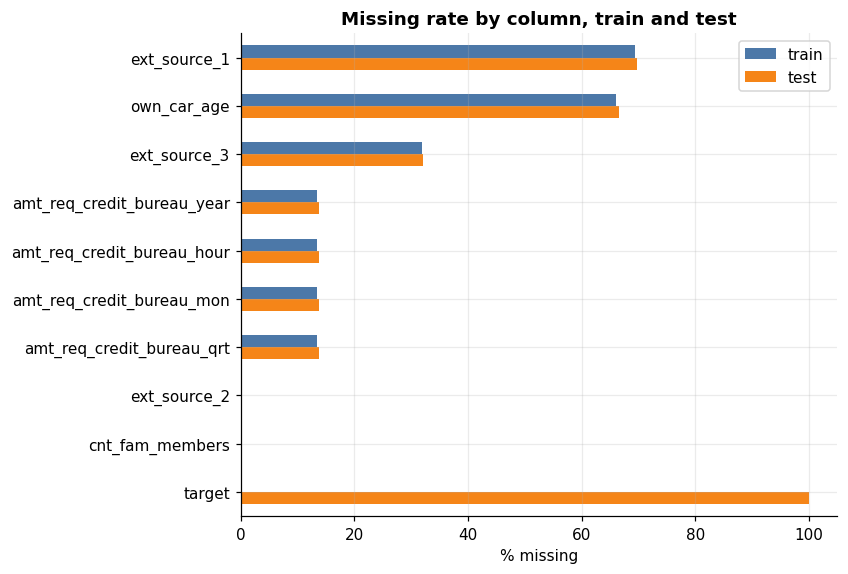

In [3]:
miss = pd.DataFrame({"train": train.isna().mean() * 100, "test": test.reindex(columns=train.columns).isna().mean() * 100})
miss = miss[(miss["train"] > 0) | (miss["test"] > 0)].sort_values("train", ascending=False)
display(miss)
ax = miss.plot.barh(figsize=(7, 0.45 * len(miss) + 1.2), color=["#4c78a8", "#f58518"])
ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing rate by column, train and test")
plt.show()

,n,share,rate,missing columns
pattern,,,,
110000000,53138,0.3104,0.0834,"ext_source_1, own_car_age"
100000000,27090,0.1582,0.0725,ext_source_1
010000000,22545,0.1317,0.0753,own_car_age
111000000,14596,0.0853,0.0824,"ext_source_1, own_car_age, ext_source_3"
000000000,13619,0.0795,0.0640,(no column in the list is missing)
111111100,11894,0.0695,0.1101,"ext_source_1, own_car_age, ext_source_3, amt_r..."
101000000,7219,0.0422,0.0716,"ext_source_1, ext_source_3"
011000000,6077,0.0355,0.0785,"own_car_age, ext_source_3"
101111100,4707,0.0275,0.0973,"ext_source_1, ext_source_3, amt_req_credit_bur..."


Column order in the pattern: ['ext_source_1', 'own_car_age', 'ext_source_3', 'amt_req_credit_bureau_year', 'amt_req_credit_bureau_hour', 'amt_req_credit_bureau_mon', 'amt_req_credit_bureau_qrt', 'ext_source_2', 'cnt_fam_members']


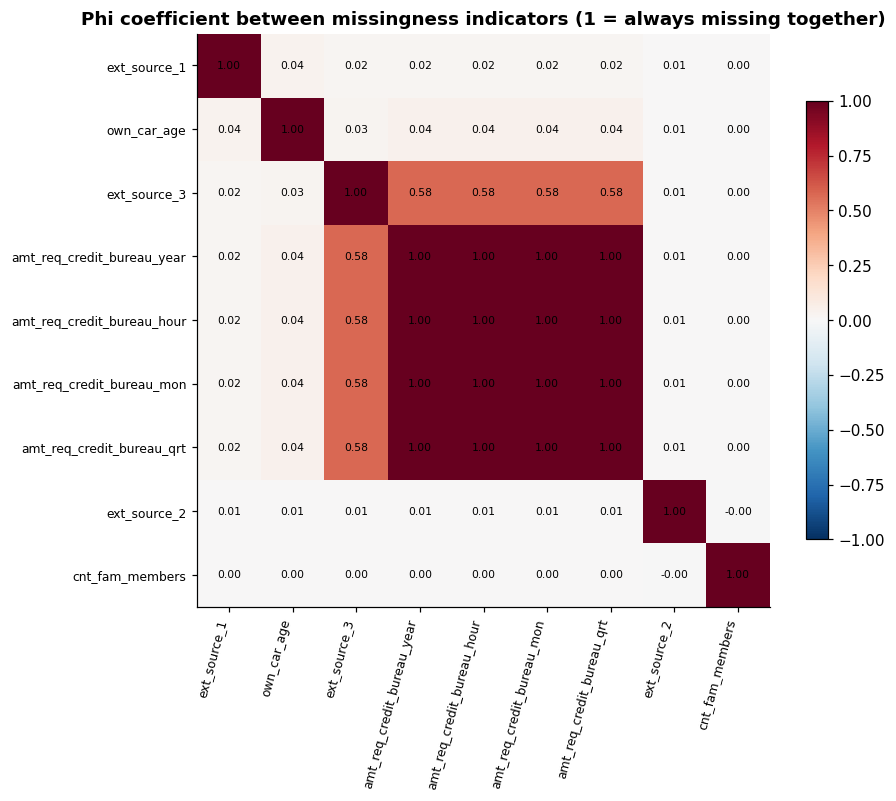

In [4]:
na_cols = [c for c in miss.index if c != TARGET]
na_ind = tr[na_cols].isna()
# (b) joint missingness patterns
pat = na_ind.astype(int).astype(str).agg("".join, axis=1)
pt = pd.DataFrame({"pattern": pat, "y": y}).groupby("pattern")["y"].agg(n="size", rate="mean").sort_values("n", ascending=False)
pt["share"] = pt["n"] / len(tr)
pt["missing columns"] = [", ".join(c for c, b in zip(na_cols, p) if b == "1") or "(no column in the list is missing)" for p in pt.index]
display(pt.head(12)[["n", "share", "rate", "missing columns"]])
print("Column order in the pattern:", na_cols)

# phi coefficient between missingness indicators
phi = na_ind.astype(float).corr()
fig, ax = plt.subplots(figsize=(0.6 * len(na_cols) + 3, 0.6 * len(na_cols) + 2))
im = ax.imshow(phi, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(na_cols))); ax.set_xticklabels(na_cols, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(na_cols))); ax.set_yticklabels(na_cols, fontsize=8)
ax.grid(False); ax.set_title("Phi coefficient between missingness indicators (1 = always missing together)")
for i in range(len(na_cols)):
    for j in range(len(na_cols)):
        ax.text(j, i, f"{phi.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=0.7); plt.show()

In [5]:
# (c) is missingness related to the label: default rate when missing vs present, two-proportion z test
rows = []
for c in na_cols:
    m = tr[c].isna().to_numpy()
    k1, n1, k0, n0 = y[m].sum(), m.sum(), y[~m].sum(), (~m).sum()
    p1, p0, pp = k1 / n1, k0 / n0, (k1 + k0) / (n1 + n0)
    z = (p1 - p0) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n0))
    rows.append({"column": c, "n missing": n1, "default rate if missing": p1, "default rate if present": p0, "difference (pp)": 100 * (p1 - p0), "z": z, "p": 2 * stats.norm.sf(abs(z))})
mt = pd.DataFrame(rows).set_index("column").sort_values("z", key=np.abs, ascending=False)
display(mt)
note("2. missingness vs label", f"{int((mt['p'] < 0.01).sum())}/{len(mt)} columns have a significantly different default rate (p<0.01) between the missing and non-missing groups",
     "; ".join(f"{c}: {r['difference (pp)']:+.1f}pp" for c, r in mt.head(4).iterrows()))

,n missing,default rate if missing,default rate if present,difference (pp),z,p
column,,,,,,
amt_req_credit_bureau_hour,23116,0.1038,0.0771,2.6650,13.8331,0.0000
amt_req_credit_bureau_qrt,23116,0.1038,0.0771,2.6650,13.8331,0.0000
amt_req_credit_bureau_year,23116,0.1038,0.0771,2.6650,13.8331,0.0000
amt_req_credit_bureau_mon,23116,0.1038,0.0771,2.6650,13.8331,0.0000
own_car_age,112992,0.0850,0.0725,1.2448,8.9567,0.0000
ext_source_3,54586,0.0886,0.0771,1.1520,8.1538,0.0000
ext_source_1,118928,0.0833,0.0749,0.8428,5.8953,0.0000
cnt_fam_members,2,0.0000,0.0807,-8.0730,-0.4191,0.6751
ext_source_2,369,0.0786,0.0807,-0.2143,-0.1510,0.8800


[2. missingness vs label] 7/9 columns have a significantly different default rate (p<0.01) between the missing and non-missing groups
    amt_req_credit_bureau_hour: +2.7pp; amt_req_credit_bureau_qrt: +2.7pp; amt_req_credit_bureau_year: +2.7pp; amt_req_credit_bureau_mon: +2.7pp


## 3. Unusual values

Three kinds are scanned automatically: (a) **spikes**: a value repeated unusually often compared with its neighbouring values (a sign of a sentinel such as 365243), (b) **strings that look like "missing"** (`XNA`, `Unknown`...), (c) **logic violations** between columns (age, employment duration, household size...).

In [6]:
MAGIC = {365243, 99999, 9999, 999, -1, -999, 999999, 1900, 65535, 9999999}
rows = []
for c in NUM:
    s = tr[c].dropna()
    if s.nunique() < 12:
        continue
    vc = s.value_counts()
    top_v, top_n = vc.index[0], vc.iloc[0]
    ratio = top_n / max(vc.iloc[1:21].mean(), 1)
    magic = [v for v in vc.head(10).index if v in MAGIC]
    if (ratio >= 5 and top_n >= 0.005 * len(s)) or magic:
        rows.append({"column": c, "most frequent value": top_v, "row count": top_n, "% train": 100 * top_n / len(tr), "times the mean count of the next 20 values": ratio,
                     "matches a known 'magic' value": magic or ""})
spike = pd.DataFrame(rows).set_index("column") if rows else pd.DataFrame()
print("Numeric columns with a spike or a magic value:")
display(spike if len(spike) else "none")

# strings that look like missing
sus = ["XNA", "Unknown", "unknown", "nan", "NaN", "None", "", "?", "N/A", "n/a"]
rows = []
for c in CAT:
    vc = tr[c].value_counts(dropna=False)
    for v in vc.index:
        if str(v) in sus:
            rows.append({"column": c, "value": v, "row count": vc[v], "% train": 100 * vc[v] / len(tr), "default rate": y[(tr[c] == v).to_numpy()].mean()})
print("Strings that look like 'missing' in categorical columns:")
display(pd.DataFrame(rows).set_index("column") if rows else "none")

Numeric columns with a spike or a magic value:


,most frequent value,row count,% train,times the mean count of the next 20 values,matches a known 'magic' value
column,,,,,
cnt_children,0.0000,119950,70.0634,28.0848,
days_employed,"365,243.0000",30898,18.0477,382.6378,[365243]
days_registration,-1.0000,64,0.0374,1.4318,[-1.0]
cnt_fam_members,2.0000,88165,51.4976,14.8649,
days_last_phone_change,0.0000,20971,12.2493,58.6683,[-1.0]
amt_req_credit_bureau_mon,0.0000,123733,72.2731,101.6162,
amt_req_credit_bureau_year,0.0000,39868,23.2871,7.3682,


Strings that look like 'missing' in categorical columns:


,value,row count,% train,default rate
column,,,,
code_gender,XNA,4,0.0023,0.0000
name_family_status,Unknown,2,0.0012,0.0000
organization_type,XNA,30898,18.0477,0.0542


In [7]:
# logic violations: one rule per entry, count the violating rows (train and test)
d = full.copy()
d["age_years"] = -d["days_birth"] / 365.25
d["emp_years_raw"] = np.where(d["days_employed"] == 365243, np.nan, -d["days_employed"] / 365.25)
d["reg_years"] = -d["days_registration"] / 365.25
d["id_years"] = -d["days_id_publish"] / 365.25
rules = {
    "age < 18 or > 80": (d["age_years"] < 18) | (d["age_years"] > 80),
    "days_employed > 0 but ≠ 365243": (d["days_employed"] > 0) & (d["days_employed"] != 365243),
    "employment duration > age - 14": d["emp_years_raw"] > d["age_years"] - 14,
    "registration duration > age": d["reg_years"] > d["age_years"],
    "ID document issued before age 14": d["id_years"] > d["age_years"] - 14,
    "days_last_phone_change > 0": d["days_last_phone_change"] > 0,
    "family members < children + 1": d["cnt_fam_members"] < d["cnt_children"] + 1,
    "income ≤ 0": d["income"] <= 0,
    "income > 10 million": d["income"] > 1e7,
    "loan amount ≤ 0": d["credit_amount"] <= 0,
    "annuity ≤ 0": d["annuity"] <= 0,
    "goods price > 1.5 × loan amount": d["amt_goods_price"] > 1.5 * d["credit_amount"],
    "children ≥ 10": d["cnt_children"] >= 10,
    "ext_source outside [0,1]": ((d[["ext_source_1", "ext_source_2", "ext_source_3"]] < 0) | (d[["ext_source_1", "ext_source_2", "ext_source_3"]] > 1)).any(axis=1),
    "bureau: requests in 1 hour ≥ 5": d["amt_req_credit_bureau_hour"] >= 5,
    "bureau: requests in 3 months ≥ 20": d["amt_req_credit_bureau_qrt"] >= 20,
    "own_car_age ≥ 60": d["own_car_age"] >= 60,
}
rv = pd.DataFrame({"train": {k: int(v[d["_set"] == "train"].sum()) for k, v in rules.items()},
                   "test": {k: int(v[d["_set"] == "test"].sum()) for k, v in rules.items()}})
rv["% train"] = 100 * rv["train"] / len(tr)
rv["default rate when violated"] = [np.nan if r == 0 else y[rules[k][d["_set"] == "train"].to_numpy()].mean() for k, r in rv["train"].items()]
display(rv)

,train,test,% train,default rate when violated
age < 18 or > 80,0,0,0.0000,NaN
days_employed > 0 but ≠ 365243,0,0,0.0000,NaN
employment duration > age - 14,0,0,0.0000,NaN
registration duration > age,1,0,0.0006,0.0000
ID document issued before age 14,0,0,0.0000,NaN
days_last_phone_change > 0,0,0,0.0000,NaN
family members < children + 1,0,0,0.0000,NaN
income ≤ 0,0,0,0.0000,NaN
income > 10 million,1,2,0.0006,0.0000
loan amount ≤ 0,0,0,0.0000,NaN


## 4. Testing hypotheses about missing and unusual values

Each hypothesis follows the same framework: **statement → measure the coverage and precision of the explanation → try alternative explanations (education, age, organization...) → conditional conclusion**. The original column is always kept as is; `365243` is not replaced by NaN before the testing.

### H1. Is `days_employed = 365243` "not working"?

In [8]:
S = tr["days_employed"].eq(365243)
print(f"365243: {S.sum():,} rows ({S.mean():.2%} of train; test {te['days_employed'].eq(365243).mean():.2%}); default rate {y[S].mean():.2%} vs {y[~S].mean():.2%} in the rest")

# (1) by income type
g = tr.assign(S=S).groupby("name_income_type").agg(n=("S", "size"), has_365243=("S", "sum"))
g["% with 365243"] = 100 * g["has_365243"] / g["n"]
g["default rate"] = pd.Series(y).groupby(tr["name_income_type"]).mean()
display(g.sort_values("% with 365243", ascending=False))
core = list(g.index[g["% with 365243"] >= 90])
prec = float(S[tr["name_income_type"].isin(core)].mean()) if core else np.nan
rec = float(tr.loc[S, "name_income_type"].isin(core).mean()) if S.any() else np.nan
print(f"Rule 'income type ∈ {core}': precision (within that group, % with 365243) = {prec:.1%}, coverage (among the 365243 rows, % in that group) = {rec:.1%}")

365243: 30,898 rows (18.05% of train; test 17.18%); default rate 5.42% vs 8.66% in the rest


,n,has_365243,% with 365243,default rate
name_income_type,,,,
Unemployed,10,10,100.0000,0.2000
Pensioner,30895,30888,99.9773,0.0542
Commercial associate,40007,0,0.0000,0.0752
Businessman,3,0,0.0000,0.0000
Maternity leave,3,0,0.0000,0.3333
State servant,12007,0,0.0000,0.0589
Student,9,0,0.0000,0.0000
Working,88268,0,0.0000,0.0955


Rule 'income type ∈ ['Pensioner', 'Unemployed']': precision (within that group, % with 365243) = 100.0%, coverage (among the 365243 rows, % in that group) = 100.0%


In [9]:
# (2) 365243 rows that are NOT in the core group, and the reverse: core group rows without 365243
out = tr[S & ~tr["name_income_type"].isin(core)]
inn = tr[~S & tr["name_income_type"].isin(core)]
print(f"365243 outside the core group: {len(out):,} rows | core group without 365243: {len(inn):,} rows")
if len(out):
    print("Income type of the rows outside the core:"); display(out["name_income_type"].value_counts().to_frame("n"))
if len(inn):
    print("Core group rows with a normal days_employed (examples):"); display(inn[["name_income_type", "days_employed", "days_birth", "organization_type"]].head(5))

# (3) compare the 365243 group with the others on 'life situation' columns
prof = pd.DataFrame({
    "365243": [S.sum(), -tr.loc[S, "days_birth"].median() / 365.25, tr.loc[S, "flag_emp_phone"].eq(0).mean() if "flag_emp_phone" in tr else np.nan,
               tr.loc[S, "organization_type"].eq("XNA").mean(), tr.loc[S, "occupation_type"].isna().mean(), tr.loc[S, "income"].median(), y[S].mean()],
    "rest": [(~S).sum(), -tr.loc[~S, "days_birth"].median() / 365.25, tr.loc[~S, "flag_emp_phone"].eq(0).mean() if "flag_emp_phone" in tr else np.nan,
                tr.loc[~S, "organization_type"].eq("XNA").mean(), tr.loc[~S, "occupation_type"].isna().mean(), tr.loc[~S, "income"].median(), y[~S].mean()],
}, index=["rows", "median age", "% flag_emp_phone = 0", "% organization_type = XNA", "% missing occupation_type", "median income", "default rate"])
display(prof)

365243 outside the core group: 0 rows | core group without 365243: 7 rows
Core group rows with a normal days_employed (examples):


,name_income_type,days_employed,days_birth,organization_type
35241,Pensioner,-11194,-21634,Business Entity Type 3
75171,Pensioner,-1895,-20811,Business Entity Type 3
94541,Pensioner,-1669,-18551,School
104189,Pensioner,-5111,-18442,Industry: type 9
115041,Pensioner,-2341,-22105,Business Entity Type 3


,365243,rest
rows,"30,898.0000","140,304.0000"
median age,60.3723,39.9316
% flag_emp_phone = 0,1.0000,0.0000
% organization_type = XNA,1.0000,0.0000
% missing occupation_type,0.0000,0.0000
median income,"117,000.0000","157,500.0000"
default rate,0.0542,0.0866


In [10]:
# (4) Do EDUCATION and the other columns explain anything more?
# If education is associated with 365243 only BECAUSE it is associated with income type, then within each income type education is no longer associated.
edu = tr["name_education_type"]
v_all = cramers_v(edu.to_numpy(), S.to_numpy())
inc = tr["name_income_type"]
rows = [{"scope": "all rows", "n": len(tr), "Cramer's V (education ~ has 365243)": v_all}]
for t_ in g.sort_values("n", ascending=False).index[:6]:
    m = (inc == t_).to_numpy()
    if S[m].nunique() > 1:
        rows.append({"scope": f"within '{t_}'", "n": int(m.sum()), "Cramer's V (education ~ has 365243)": cramers_v(edu[m].to_numpy(), S[m].to_numpy())})
    else:
        rows.append({"scope": f"within '{t_}'", "n": int(m.sum()), "Cramer's V (education ~ has 365243)": np.nan})
display(pd.DataFrame(rows))
ct = pd.crosstab(edu, S, normalize="index").rename(columns={True: "% with 365243", False: "% without"}) * 100
display(ct)

# education × income type together: share with 365243
display((tr.assign(S=S).pivot_table(index="name_education_type", columns="name_income_type", values="S", aggfunc="mean") * 100).round(1))

# (5) how strongly every column is associated with 365243 (including numeric columns such as age)
at = assoc_table(S.to_numpy(), tr, exclude=("days_employed",), top=12)
display(at)
auc_all, imp = predict_mask_auc(S.to_numpy(), tr, exclude=("days_employed",))
auc_inc, _ = predict_mask_auc(S.to_numpy(), tr[["name_income_type"]].assign(days_employed=tr["days_employed"]), exclude=("days_employed",))
print(f"AUC predicting '365243' from all other columns = {auc_all:.4f}; from income type only = {auc_inc:.4f}")
display(imp.to_frame("gain share"))

if not S.any():
    note("H1: 365243", "NO 365243 values in train", "there are no rows to test")
elif core and rec >= 0.95 and prec >= 0.90:
    note("H1: 365243", f"CONFIRMED: 365243 marks the non-working group ({', '.join(core)})",
         f"coverage {rec:.1%}, precision {prec:.1%}; V(education) overall {v_all:.2f}; AUC from income type {auc_inc:.3f}")
else:
    note("H1: 365243", "ONLY PARTLY TRUE or unclear", f"coverage {rec:.1%}, precision {prec:.1%} (thresholds 95%/90%); see the tables above")

,scope,n,Cramer's V (education ~ has 365243)
0,all rows,171202,0.1420
1,within 'Working',88268,NaN
2,within 'Commercial associate',40007,NaN
3,within 'Pensioner',30895,0.0072
4,within 'State servant',12007,NaN
5,within 'Unemployed',10,NaN
6,within 'Student',9,NaN


days_employed,% without,% with 365243
name_education_type,,
Academic degree,82.1782,17.8218
Higher education,89.1343,10.8657
Incomplete higher,95.0622,4.9378
Lower secondary,59.1655,40.8345
Secondary / secondary special,79.2767,20.7233


name_income_type,Businessman,Commercial associate,Maternity leave,Pensioner,State servant,Student,Unemployed,Working
name_education_type,,,,,,,,
Academic degree,NaN,0.0000,NaN,100.0000,0.0000,NaN,NaN,0.0000
Higher education,0.0000,0.0000,0.0000,100.0000,0.0000,0.0000,100.0000,0.0000
Incomplete higher,NaN,0.0000,NaN,100.0000,0.0000,0.0000,100.0000,0.0000
Lower secondary,NaN,0.0000,NaN,100.0000,0.0000,NaN,NaN,0.0000
Secondary / secondary special,NaN,0.0000,0.0000,100.0000,0.0000,0.0000,100.0000,0.0000


,column,type,strength (0-1)
0,organization_type,categorical,1.0000
1,flag_emp_phone,categorical,0.9999
2,name_income_type,categorical,0.9999
3,days_birth,numeric,0.9010
4,occupation_type,categorical,0.6937
5,ext_source_1,numeric,0.5723
6,days_id_publish,numeric,0.4184
7,cnt_fam_members,numeric,0.3306
8,cnt_children,numeric,0.3237
9,income,numeric,0.2957


AUC predicting '365243' from all other columns = 1.0000; from income type only = 1.0000


,gain share
flag_emp_phone,0.9885
organization_type,0.0107
days_birth,0.0003
own_car_age,0.0001
ext_source_1,0.0001
ext_source_2,0.0001


[H1: 365243] CONFIRMED: 365243 marks the non-working group (Pensioner, Unemployed)
    coverage 100.0%, precision 100.0%; V(education) overall 0.14; AUC from income type 1.000


**How to read H1.** If coverage and precision are both high, then 365243 really means "no job" (retired, unemployed...) and is not random, and replacing it with NaN and creating a "not working" flag is reasonable. If education is only associated when we do not split by income type (high overall V, low V within each group), then education explains nothing extra; it simply follows income type (older people tend to have lower education).

### H2. Does a missing `own_car_age` mean "no car"?

own_car_age missing: 66.00%. The table has NO flag_own_car column, so this cannot be tested directly; only indirect evidence is available.
Car-related columns in the table: ['own_car_age']
Most common values of own_car_age: {7.0: np.int64(4074), 3.0: np.int64(3578), 6.0: np.int64(3522), 2.0: np.int64(3293), 8.0: np.int64(3282), 4.0: np.int64(3093), 1.0: np.int64(3044), 9.0: np.int64(2804)}
Car age distribution (when present): median 9, p95 30, max 91; ≥ 60 years: 3.14%


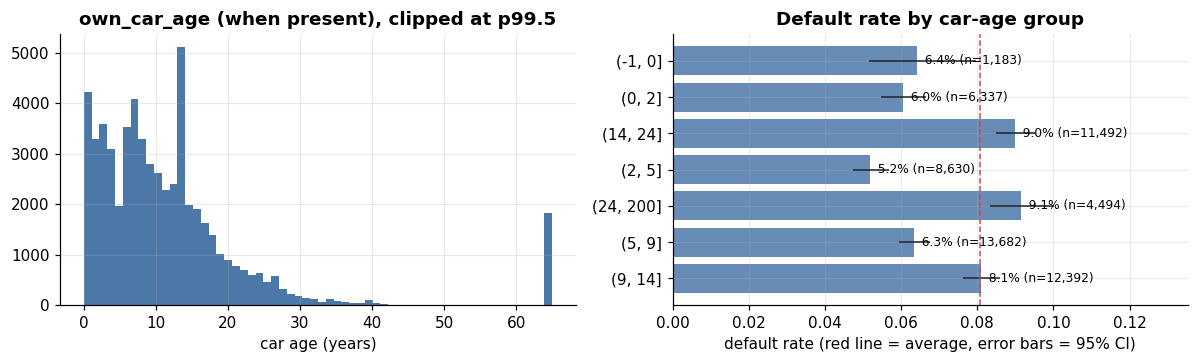

,has own_car_age,missing
median income,"180,000.0000","135,000.0000"
median loan amount,"549,441.0000","490,495.5000"
median age,40.6612,44.8761
mean region rating,2.0381,2.0618
n,"58,210.0000","112,992.0000"
default rate,0.0725,0.0850


,column,type,strength (0-1)
0,code_gender,categorical,0.3462
1,income,numeric,0.2762
2,occupation_type,categorical,0.2569
3,organization_type,categorical,0.2054
4,cnt_fam_members,numeric,0.1803
5,annuity,numeric,0.1720
6,name_family_status,categorical,0.1689
7,name_income_type,categorical,0.1583
8,flag_emp_phone,categorical,0.1562
9,days_birth,numeric,0.1560


AUC predicting 'own_car_age missing' from all other columns = 0.758 (0.5 = completely random, 1.0 = fully explained)
[H2: own_car_age] CANNOT BE TESTED DIRECTLY; missing is usually read as 'no car'
    missing 66%; AUC predicting from other columns 0.76; default-rate difference missing vs present +1.2 pp


In [11]:
car_na = tr["own_car_age"].isna()
print(f"own_car_age missing: {car_na.mean():.2%}. The table has NO flag_own_car column, so this cannot be tested directly; only indirect evidence is available.")
print("Car-related columns in the table:", [c for c in tr.columns if "car" in c or "own" in c])
obs = tr["own_car_age"].dropna()
vc = obs.value_counts().head(8)
print("Most common values of own_car_age:", dict(vc))
print(f"Car age distribution (when present): median {obs.median():.0f}, p95 {obs.quantile(.95):.0f}, max {obs.max():.0f}; ≥ 60 years: {(obs >= 60).mean():.2%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(obs.clip(upper=obs.quantile(.995)), bins=60, color="#4c78a8"); ax[0].set_title("own_car_age (when present), clipped at p99.5"); ax[0].set_xlabel("car age (years)")
rt = rate_table(pd.cut(obs, [-1, 0, 2, 5, 9, 14, 24, 200]).astype(str), tgt=y[~car_na.to_numpy()])
plot_rates(rt.sort_index(), "Default rate by car-age group", ax=ax[1], top=10)
plt.tight_layout(); plt.show()

# is missing consistent with "no car"? owning a car implies a certain income / circumstances
cmp = pd.DataFrame({
    "has own_car_age": [tr.loc[~car_na, "income"].median(), tr.loc[~car_na, "credit_amount"].median(), -tr.loc[~car_na, "days_birth"].median() / 365.25,
                       tr.loc[~car_na, "region_rating_client"].mean(), (~car_na).sum(), y[~car_na.to_numpy()].mean()],
    "missing": [tr.loc[car_na, "income"].median(), tr.loc[car_na, "credit_amount"].median(), -tr.loc[car_na, "days_birth"].median() / 365.25,
              tr.loc[car_na, "region_rating_client"].mean(), car_na.sum(), y[car_na.to_numpy()].mean()],
}, index=["median income", "median loan amount", "median age", "mean region rating", "n", "default rate"])
display(cmp)
display(assoc_table(car_na.to_numpy(), tr, exclude=("own_car_age",), top=10))
auc_c, imp_c = predict_mask_auc(car_na.to_numpy(), tr, exclude=("own_car_age",))
print(f"AUC predicting 'own_car_age missing' from all other columns = {auc_c:.3f} (0.5 = completely random, 1.0 = fully explained)")
note("H2: own_car_age", "CANNOT BE TESTED DIRECTLY; missing is usually read as 'no car'",
     f"missing {car_na.mean():.0%}; AUC predicting from other columns {auc_c:.2f}; default-rate difference missing vs present {100 * (y[car_na.to_numpy()].mean() - y[~car_na.to_numpy()].mean()):+.1f} pp")

### H3. The four bureau columns missing together

Columns: ['amt_req_credit_bureau_hour', 'amt_req_credit_bureau_mon', 'amt_req_credit_bureau_qrt', 'amt_req_credit_bureau_year']
Missing: {'amt_req_credit_bureau_hour': 0.135, 'amt_req_credit_bureau_mon': 0.135, 'amt_req_credit_bureau_qrt': 0.135, 'amt_req_credit_bureau_year': 0.135} | all 4 always missing together: True (share of rows missing at least one: 13.50%)


,column,type,strength (0-1)
0,ext_source_3 [is missing?],missing,0.5775
1,days_id_publish,numeric,0.1485
2,income,numeric,0.1431
3,days_last_phone_change,numeric,0.1202
4,ext_source_1,numeric,0.0990
5,days_employed,numeric,0.0941
6,amt_goods_price,numeric,0.0890
7,credit_amount,numeric,0.0847
8,days_birth,numeric,0.0773
9,own_car_age,numeric,0.0751


AUC predicting 'bureau missing' from all other columns = 0.920


,gain share
ext_source_3,0.7484
days_id_publish,0.0276
days_last_phone_change,0.0231
organization_type,0.0214
income,0.0188
annuity,0.0185


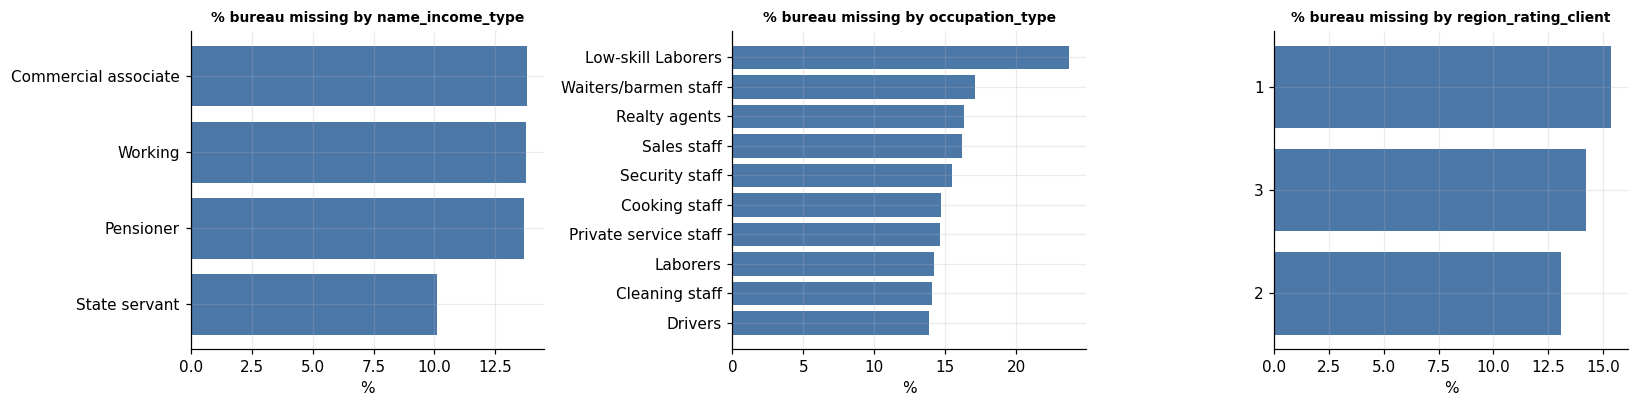

When present: quick statistics


,count,mean,50%,90%,99%,99.9%,max
amt_req_credit_bureau_hour,"148,086.0000",0.0067,0.0000,0.0000,0.0000,1.0000,4.0000
amt_req_credit_bureau_mon,"148,086.0000",0.2684,0.0000,1.0000,4.0000,12.0000,23.0000
amt_req_credit_bureau_qrt,"148,086.0000",0.2675,0.0000,1.0000,2.0000,4.0000,261.0000
amt_req_credit_bureau_year,"148,086.0000",1.9036,1.0000,4.0000,8.0000,9.0000,23.0000


Share equal to 0: {'amt_req_credit_bureau_hour': 0.994, 'amt_req_credit_bureau_mon': 0.836, 'amt_req_credit_bureau_qrt': 0.809, 'amt_req_credit_bureau_year': 0.269}
[H3: bureau] CONFIRMED: the 4 columns are missing together (a single flag)
    missing 13.5%; AUC predicting missingness from other columns 0.92; default rate 10.38% (missing) vs 7.71% (present)


In [12]:
BUR = [c for c in tr.columns if c.startswith("amt_req_credit_bureau")]
bm = tr[BUR].isna()
all_same = bool((bm.nunique(axis=1) == 1).all())
print(f"Columns: {BUR}")
print(f"Missing: {bm.mean().round(4).to_dict()} | all 4 always missing together: {all_same} (share of rows missing at least one: {bm.any(axis=1).mean():.2%})")
B = bm.any(axis=1)
display(assoc_table(B.to_numpy(), tr, exclude=BUR, top=10))
auc_b, imp_b = predict_mask_auc(B.to_numpy(), tr, exclude=BUR)
print(f"AUC predicting 'bureau missing' from all other columns = {auc_b:.3f}")
display(imp_b.to_frame("gain share"))

# missingness by group
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, ("name_income_type", "occupation_type", "region_rating_client")):
    gg = pd.DataFrame({"k": tr[c].astype(object).where(tr[c].notna(), "(missing)"), "m": B}).groupby("k")["m"].agg(["mean", "size"]).sort_values("mean")
    gg = gg[gg["size"] >= 50].tail(10)
    a.barh(gg.index.astype(str).str[:28], 100 * gg["mean"], color="#4c78a8"); a.set_title(f"% bureau missing by {c}", fontsize=9); a.set_xlabel("%")
plt.tight_layout(); plt.show()

# values when present: mostly zero? any outliers?
print("When present: quick statistics")
display(tr[BUR].describe(percentiles=[.5, .9, .99, .999]).T[["count", "mean", "50%", "90%", "99%", "99.9%", "max"]])
print("Share equal to 0:", (tr[BUR] == 0).sum().div(tr[BUR].notna().sum()).round(3).to_dict())
yb = y[B.to_numpy()].mean(); yn = y[~B.to_numpy()].mean()
note("H3: bureau", ("CONFIRMED: the 4 columns are missing together (a single flag)" if all_same else "the 4 columns are NOT always missing together"),
     f"missing {B.mean():.1%}; AUC predicting missingness from other columns {auc_b:.2f}; default rate {yb:.2%} (missing) vs {yn:.2%} (present)")

### H4. `ext_source_1/2/3` missing: random or for a reason?

,% missing,AUC from all other columns,AUC without any ext_source columns,default rate if missing,default rate if present,top explaining columns
column,,,,,,
ext_source_1,69.4665,0.6524,0.6506,0.0833,0.0749,"days_birth, organization_type, days_last_phone..."
ext_source_2,0.2155,0.6598,0.6610,0.0786,0.0807,"days_id_publish, credit_amount, ext_source_3"
ext_source_3,31.8840,0.7219,0.7248,0.0886,0.0771,"amt_req_credit_bureau_qrt, amt_req_credit_bure..."


Missing together (row counts by missingness combination):


,n
pattern (1 = missing: ext1 ext2 ext3),
100,80229
101,38417
000,36164
001,16023
110,165
111,117
010,58
011,29


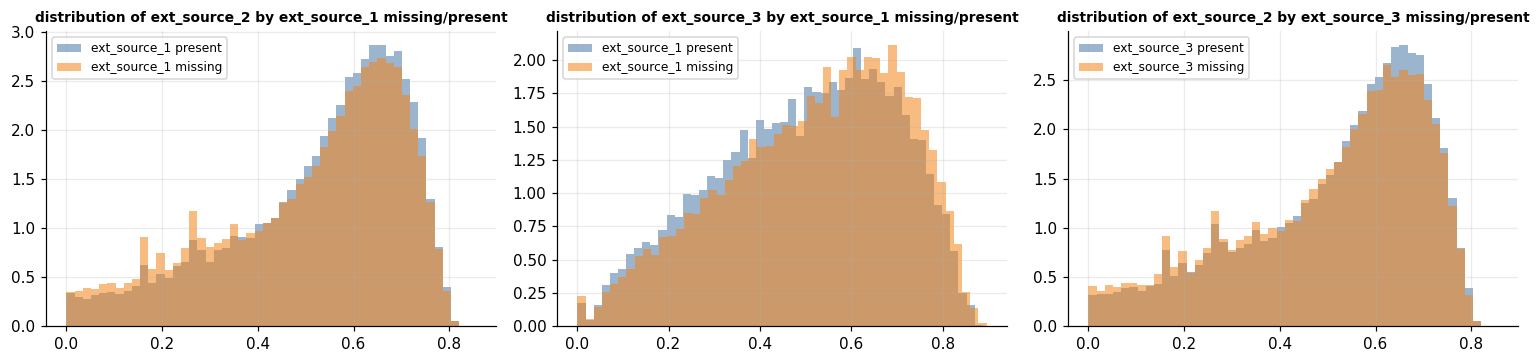

KS of ext_source_2 between the ext_source_1-missing and ext_source_1-present groups: D = 0.042, p = 1.9e-55
KS of ext_source_3 between the ext_source_1-missing and ext_source_1-present groups: D = 0.046, p = 6.4e-47
KS of ext_source_2 between the ext_source_3-missing and ext_source_3-present groups: D = 0.031, p = 4.6e-32
[H4: ext_source] STRUCTURED MISSINGNESS (explainable from other columns)
    ext_source_1: missing 69.5%, AUC 0.65; ext_source_2: missing 0.2%, AUC 0.66; ext_source_3: missing 31.9%, AUC 0.72


In [13]:
EXT = ["ext_source_1", "ext_source_2", "ext_source_3"]
rows = []
for c in EXT:
    m = tr[c].isna().to_numpy()
    others = [e for e in EXT if e != c]
    auc_all_, imp_ = predict_mask_auc(m, tr, exclude=(c,))
    auc_noext, _ = predict_mask_auc(m, tr, exclude=tuple(EXT))
    rows.append({"column": c, "% missing": 100 * m.mean(), "AUC from all other columns": auc_all_, "AUC without any ext_source columns": auc_noext,
                 "default rate if missing": y[m].mean() if m.any() else np.nan, "default rate if present": y[~m].mean(),
                 "top explaining columns": ", ".join(imp_.index[:3]) if len(imp_) else ""})
et = pd.DataFrame(rows).set_index("column")
display(et)
print("Missing together (row counts by missingness combination):")
display(tr[EXT].isna().astype(int).astype(str).agg("".join, axis=1).value_counts().rename_axis("pattern (1 = missing: ext1 ext2 ext3)").to_frame("n"))

# Hint of MNAR (missing not at random): distribution of ext_2 and ext_3 when ext_1 is missing vs present
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, (c, o) in zip(ax, (("ext_source_1", "ext_source_2"), ("ext_source_1", "ext_source_3"), ("ext_source_3", "ext_source_2"))):
    m = tr[c].isna()
    a.hist(tr.loc[~m, o].dropna(), bins=50, alpha=0.55, density=True, label=f"{c} present", color="#4c78a8")
    a.hist(tr.loc[m, o].dropna(), bins=50, alpha=0.55, density=True, label=f"{c} missing", color="#f58518")
    a.set_title(f"distribution of {o} by {c} missing/present", fontsize=9); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# KS test between the two groups
for c, o in (("ext_source_1", "ext_source_2"), ("ext_source_1", "ext_source_3"), ("ext_source_3", "ext_source_2")):
    m = tr[c].isna()
    ks = stats.ks_2samp(tr.loc[~m, o].dropna(), tr.loc[m, o].dropna())
    print(f"KS of {o} between the {c}-missing and {c}-present groups: D = {ks.statistic:.3f}, p = {ks.pvalue:.2g}")
best = et["AUC from all other columns"].max()
note("H4: ext_source", ("STRUCTURED MISSINGNESS (explainable from other columns)" if best >= 0.7 else "MISSINGNESS NEARLY RANDOM relative to the other columns" if best < 0.6 else "MISSINGNESS MODERATELY ASSOCIATED"),
     "; ".join(f"{c}: missing {r['% missing']:.1f}%, AUC {r['AUC from all other columns']:.2f}" for c, r in et.iterrows()))

### H5. `occupation_type` missing

In [14]:
occ_na = tr["occupation_type"].isna()
print(f"occupation_type missing: {occ_na.mean():.2%}; default rate when missing {y[occ_na.to_numpy()].mean():.2%} vs {y[~occ_na.to_numpy()].mean():.2%}")
g5 = tr.assign(m=occ_na).groupby("name_income_type")["m"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "% missing occupation"})
g5["% missing occupation"] *= 100
display(g5.sort_values("% missing occupation", ascending=False))
print(f"Overlap with 365243: {(occ_na & S).sum():,} rows are both missing occupation and 365243 ({(occ_na & S).sum() / max(occ_na.sum(), 1):.1%} of the rows missing occupation)")
print("Split by 365243:")
display(pd.crosstab(occ_na.rename("occupation missing"), S.rename("365243"), normalize="columns").mul(100).round(1))
display(assoc_table(occ_na.to_numpy(), tr, exclude=("occupation_type",), top=10))
auc_o, imp_o = predict_mask_auc(occ_na.to_numpy(), tr, exclude=("occupation_type",))
only_S = float((occ_na & ~S).sum() / max(occ_na.sum(), 1))
print(f"AUC predicting 'occupation missing' from all other columns = {auc_o:.3f}; share of missing occupation NOT in the 365243 group: {only_S:.1%}")
note("H5: occupation_type", "STRUCTURED MISSINGNESS" if auc_o >= 0.7 else "fairly random missingness", f"missing {occ_na.mean():.1%}; AUC from other columns {auc_o:.2f}; {only_S:.0%} of missing rows are outside the 365243 group")

occupation_type missing: 0.00%; default rate when missing nan% vs 8.07%


,n,% missing occupation
name_income_type,,
Businessman,3,0.0000
Commercial associate,40007,0.0000
Maternity leave,3,0.0000
Pensioner,30895,0.0000
State servant,12007,0.0000
Student,9,0.0000
Unemployed,10,0.0000
Working,88268,0.0000


Overlap with 365243: 0 rows are both missing occupation and 365243 (0.0% of the rows missing occupation)
Split by 365243:


365243,False,True
occupation missing,,
False,100.0000,100.0000


,column,type,strength (0-1)


AUC predicting 'occupation missing' from all other columns = nan; share of missing occupation NOT in the 365243 group: 0.0%
[H5: occupation_type] fairly random missingness
    missing 0.0%; AUC from other columns nan; 0% of missing rows are outside the 365243 group


### H6. Testing ALL columns that have NaN (not only the ones above)

The same framework for every column with missing values: (1) how well the other columns explain the missingness (AUC), (2) the best simple rule "column X = value v implies missing" (precision and coverage), (3) which column it is missing together with, (4) the default rate when missing. It also scans columns that are *not* missing but contain values that look like missing (sentinels, `XNA`).

In [15]:
def best_rule(mask, df, exclude, min_n=30):
    # the rule 'column = v  =>  missing' with the highest F1
    m = np.asarray(mask, bool)
    best = (0, None, None, 0, 0)
    for c in df.columns:
        if c in exclude or c in (ID_COL, TARGET, "_set"):
            continue
        s_ = df[c]
        if s_.nunique(dropna=False) <= 1 or not (is_cat(s_) or s_.nunique(dropna=False) <= 30):
            continue
        k = s_.astype(object).where(s_.notna(), "(NaN)")
        g_ = pd.DataFrame({"k": k, "m": m}).groupby("k")["m"].agg(["sum", "size"])
        g_ = g_[g_["size"] >= min_n]
        if g_.empty or m.sum() == 0:
            continue
        prec_, rec_ = g_["sum"] / g_["size"], g_["sum"] / m.sum()
        f1 = 2 * prec_ * rec_ / (prec_ + rec_ + 1e-12)
        f1 = f1.where(prec_ >= 1.3 * m.mean(), 0)   # the rule's precision must exceed the base rate by at least 30%
        v = f1.idxmax()
        if f1[v] > best[0] and f1[v] > 0:
            best = (float(f1[v]), c, v, float(prec_[v]), float(rec_[v]))
    return best


rows = []
for c in [c for c in na_cols if c != TARGET]:
    m = tr[c].isna().to_numpy()
    auc_, imp_ = predict_mask_auc(m, tr, exclude=(c,))
    f1, rc, rv_, pr, rcl = best_rule(m, tr, exclude=(c,))
    co = na_ind.drop(columns=c).corrwith(pd.Series(m, index=na_ind.index).astype(float)).sort_values(key=np.abs, ascending=False)
    rows.append({"column": c, "% missing train": 100 * m.mean(), "% missing test": 100 * te[c].isna().mean(),
                 "AUC from other columns": auc_, "best single rule": f"{rc} = {rv_}" if rc else "", "precision": pr, "coverage": rcl,
                 "missing together with": (f"{co.index[0]} (phi {co.iloc[0]:.2f})" if len(co) and abs(co.iloc[0]) >= 0.3 else "—"),
                 "default rate (missing)": y[m].mean(), "default rate (present)": y[~m].mean()})
allna = pd.DataFrame(rows).set_index("column")
def _verdict(r):
    if r["AUC from other columns"] >= 0.9 or (r["precision"] >= 0.9 and r["coverage"] >= 0.9):
        return "CLEAR STRUCTURE (derivable from other columns)"
    if r["missing together with"] != "—":
        return "missing in a cluster with other columns"
    if r["AUC from other columns"] >= 0.65:
        return "moderate association"
    return "nearly random relative to the other columns"
allna["verdict"] = allna.apply(_verdict, axis=1)
display(allna.sort_values("% missing train", ascending=False))
for c, r in allna.iterrows():
    note(f"H6: {c}", r["verdict"], f"missing {r['% missing train']:.1f}%; AUC {r['AUC from other columns']:.2f}; rule {r['best single rule'] or '—'} (precision {r['precision']:.0%}, coverage {r['coverage']:.0%})")

# columns that are NOT missing but contain values that look like missing (sentinel / XNA): checked with the same framework
print()
sus_rows = []
for c in RAW:
    if c in na_cols:
        continue
    s_ = tr[c]
    cand = []
    if is_cat(s_):
        cand = [v for v in s_.dropna().unique() if str(v).strip() in {"XNA", "Unknown", "unknown", "", "?", "N/A"}]
    else:
        vc_ = s_.value_counts()
        cand = [v for v in vc_.head(5).index if v in MAGIC and vc_[v] >= 30]
    for v in cand:
        m = (s_ == v).to_numpy()
        auc_, _ = predict_mask_auc(m, tr, exclude=(c,))
        f1, rc, rv_, pr, rcl = best_rule(m, tr, exclude=(c,))
        sus_rows.append({"column": c, "value": v, "% train": 100 * m.mean(), "AUC from other columns": auc_, "best single rule": f"{rc} = {rv_}" if rc else "",
                         "precision": pr, "coverage": rcl, "default rate": y[m].mean()})
if sus_rows:
    sus_t = pd.DataFrame(sus_rows).set_index("column")
    display(sus_t)
    for c, r in sus_t.iterrows():
        note(f"H6: {c}={r['value']}", "value that looks like missing: " + ("CLEAR STRUCTURE" if r["AUC from other columns"] >= 0.9 else "not yet explained"), f"{r['% train']:.1f}% of rows; AUC {r['AUC from other columns']:.2f}; rule {r['best single rule']}")
else:
    print("No column outside the NaN list has a value that looks like missing.")

,% missing train,% missing test,AUC from other columns,best single rule,precision,coverage,missing together with,default rate (missing),default rate (present),verdict
column,,,,,,,,,,
ext_source_1,69.4665,69.7756,0.6524,,0.0000,0.0000,—,0.0833,0.0749,moderate association
own_car_age,65.9992,66.5187,0.7582,name_family_status = Widow,0.8948,0.0709,—,0.0850,0.0725,moderate association
ext_source_3,31.8840,32.0163,0.7219,amt_req_credit_bureau_hour = (NaN),1.0000,0.4235,amt_req_credit_bureau_hour (phi 0.58),0.0886,0.0771,missing in a cluster with other columns
amt_req_credit_bureau_year,13.5022,13.8423,1.0000,amt_req_credit_bureau_hour = (NaN),1.0000,1.0000,amt_req_credit_bureau_hour (phi 1.00),0.1038,0.0771,CLEAR STRUCTURE (derivable from other columns)
amt_req_credit_bureau_hour,13.5022,13.8423,1.0000,amt_req_credit_bureau_mon = (NaN),1.0000,1.0000,amt_req_credit_bureau_year (phi 1.00),0.1038,0.0771,CLEAR STRUCTURE (derivable from other columns)
amt_req_credit_bureau_mon,13.5022,13.8423,1.0000,amt_req_credit_bureau_hour = (NaN),1.0000,1.0000,amt_req_credit_bureau_year (phi 1.00),0.1038,0.0771,CLEAR STRUCTURE (derivable from other columns)
amt_req_credit_bureau_qrt,13.5022,13.8423,1.0000,amt_req_credit_bureau_hour = (NaN),1.0000,1.0000,amt_req_credit_bureau_year (phi 1.00),0.1038,0.0771,CLEAR STRUCTURE (derivable from other columns)
ext_source_2,0.2155,0.2114,0.6598,organization_type = Trade: type 3,0.0053,0.0271,—,0.0786,0.0807,moderate association
cnt_fam_members,0.0012,0.0000,NaN,organization_type = Insurance,0.0032,0.5000,—,0.0000,0.0807,nearly random relative to the other columns


[H6: ext_source_1] moderate association
    missing 69.5%; AUC 0.65; rule — (precision 0%, coverage 0%)
[H6: own_car_age] moderate association
    missing 66.0%; AUC 0.76; rule name_family_status = Widow (precision 89%, coverage 7%)
[H6: ext_source_3] missing in a cluster with other columns
    missing 31.9%; AUC 0.72; rule amt_req_credit_bureau_hour = (NaN) (precision 100%, coverage 42%)
[H6: amt_req_credit_bureau_year] CLEAR STRUCTURE (derivable from other columns)
    missing 13.5%; AUC 1.00; rule amt_req_credit_bureau_hour = (NaN) (precision 100%, coverage 100%)
[H6: amt_req_credit_bureau_hour] CLEAR STRUCTURE (derivable from other columns)
    missing 13.5%; AUC 1.00; rule amt_req_credit_bureau_mon = (NaN) (precision 100%, coverage 100%)
[H6: amt_req_credit_bureau_mon] CLEAR STRUCTURE (derivable from other columns)
    missing 13.5%; AUC 1.00; rule amt_req_credit_bureau_hour = (NaN) (precision 100%, coverage 100%)
[H6: amt_req_credit_bureau_qrt] CLEAR STRUCTURE (derivable from oth

,value,% train,AUC from other columns,best single rule,precision,coverage,default rate
column,,,,,,,
code_gender,XNA,0.0023,NaN,amt_req_credit_bureau_mon = 3.0,0.0009,0.2500,0.0000
name_family_status,Unknown,0.0012,NaN,organization_type = Insurance,0.0032,0.5000,0.0000
days_employed,365243,18.0477,1.0000,organization_type = XNA,1.0000,1.0000,0.0542
days_registration,-1.0000,0.0374,0.4944,name_education_type = Academic degree,0.0099,0.0156,0.1719
organization_type,XNA,18.0477,1.0000,flag_emp_phone = 0,0.9998,1.0000,0.0542
days_last_phone_change,-1.0000,0.9083,0.6993,amt_req_credit_bureau_year = 0.0,0.0225,0.5768,0.0817


[H6: code_gender=XNA] value that looks like missing: not yet explained
    0.0% of rows; AUC nan; rule amt_req_credit_bureau_mon = 3.0
[H6: name_family_status=Unknown] value that looks like missing: not yet explained
    0.0% of rows; AUC nan; rule organization_type = Insurance
[H6: days_employed=365243] value that looks like missing: CLEAR STRUCTURE
    18.0% of rows; AUC 1.00; rule organization_type = XNA
[H6: days_registration=-1.0] value that looks like missing: not yet explained
    0.0% of rows; AUC 0.49; rule name_education_type = Academic degree
[H6: organization_type=XNA] value that looks like missing: CLEAR STRUCTURE
    18.0% of rows; AUC 1.00; rule flag_emp_phone = 0
[H6: days_last_phone_change=-1.0] value that looks like missing: not yet explained
    0.9% of rows; AUC 0.70; rule amt_req_credit_bureau_year = 0.0


## 5. Per-column profile: meaning, hypothesis, statistics, distribution, transform, relationship with the label

Each column gets a "card" with: **(1) business meaning**, **(2) hypothesis** (the expected direction of the effect on default, taken from business knowledge, not from the data), **(3) descriptive statistics** (quantiles, skewness, kurtosis, % outliers, % zeros...), **(4) distribution** (by label), **(5) whether to transform** (skewness before/after log, sqrt, Yeo-Johnson) and **(6) relationship with the label** (Mann-Whitney / χ² tests, shape of the default-rate curve by quantile, and the conclusion on whether the hypothesis holds).

Important conventions:
- The `days_*` columns are converted to **years** (positive) for readability; `days_employed = 365243` is set apart (tested in section 4) and excluded from the statistics of `years_employed`.
- Decision trees are **invariant to monotonic transforms**, so the "transform" recommendation only matters for linear models, neural networks (TabM) and ratio features.
- The "hypothesis" is a business expectation; the conclusion at the bottom of the card is what the data says.

ext_source_3   |   univariate AUC 0.680 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Credit score from external source 3.
Hypothesis: High score -> fewer defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"116,616.0000",31.8840,784.0000,0.5112,0.1948,0.0005,0.0638,0.1547,0.3706,0.5371,0.6691,0.7863,0.8328,0.8960,-0.4123,-0.6574,0.0000,0.0000,0.0000


Mann-Whitney: AUC=0.3204, Cliff's δ=-0.359, p=0 | χ² by decile p=0 | median label0=0.548, label1=0.383
Transform : none needed: already roughly symmetric; only z-score standardization is needed for linear models/NN | Pearson correlation with label: original -0.1783, after transform -0.1783 | skewness of the options: original -0.41, log1p -0.66, sqrt -1.04, Yeo-Johnson -0.10
When missing: default rate 8.86% (n=54,586) vs 7.71% when present.


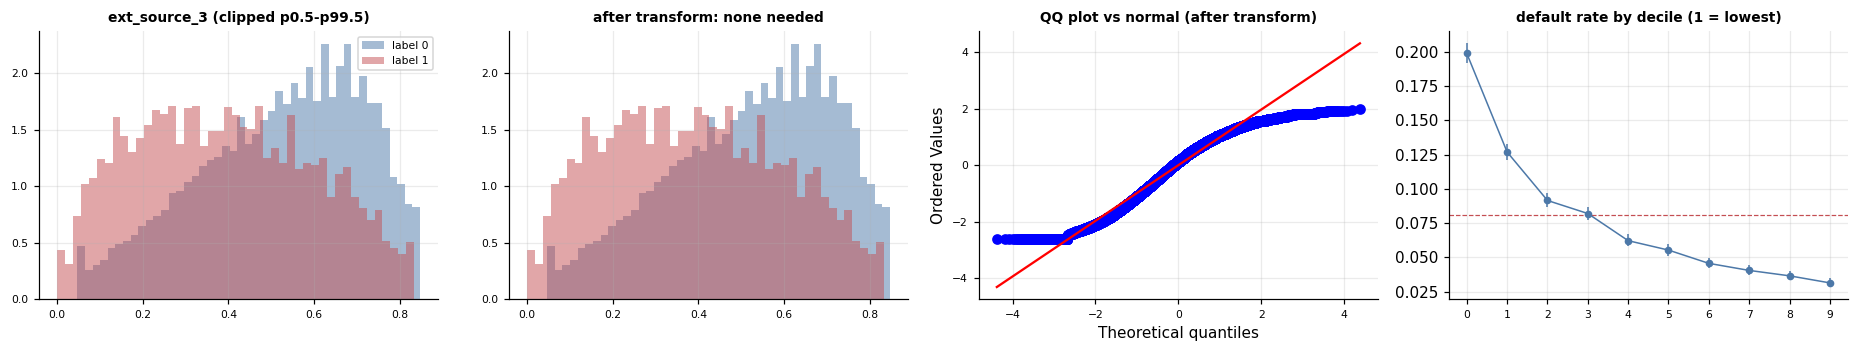

ext_source_1   |   univariate AUC 0.665 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Credit score from external source 1 (0-1, high = good).
Hypothesis: High score -> fewer defaults (the strongest signal).


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"52,274.0000",69.4665,"49,131.0000",0.5017,0.2110,0.0171,0.0846,0.1575,0.3334,0.5059,0.6746,0.8315,0.8894,0.9476,-0.0708,-0.9651,0.0000,0.0000,0.0000


Mann-Whitney: AUC=0.3353, Cliff's δ=-0.329, p=2.6e-258 | χ² by decile p=2.9e-279 | median label0=0.517, label1=0.362
Transform : none needed: already roughly symmetric; only z-score standardization is needed for linear models/NN | Pearson correlation with label: original -0.1540, after transform -0.1540 | skewness of the options: original -0.07, log1p -0.30, sqrt -0.52, Yeo-Johnson -0.05
When missing: default rate 8.33% (n=118,928) vs 7.49% when present.


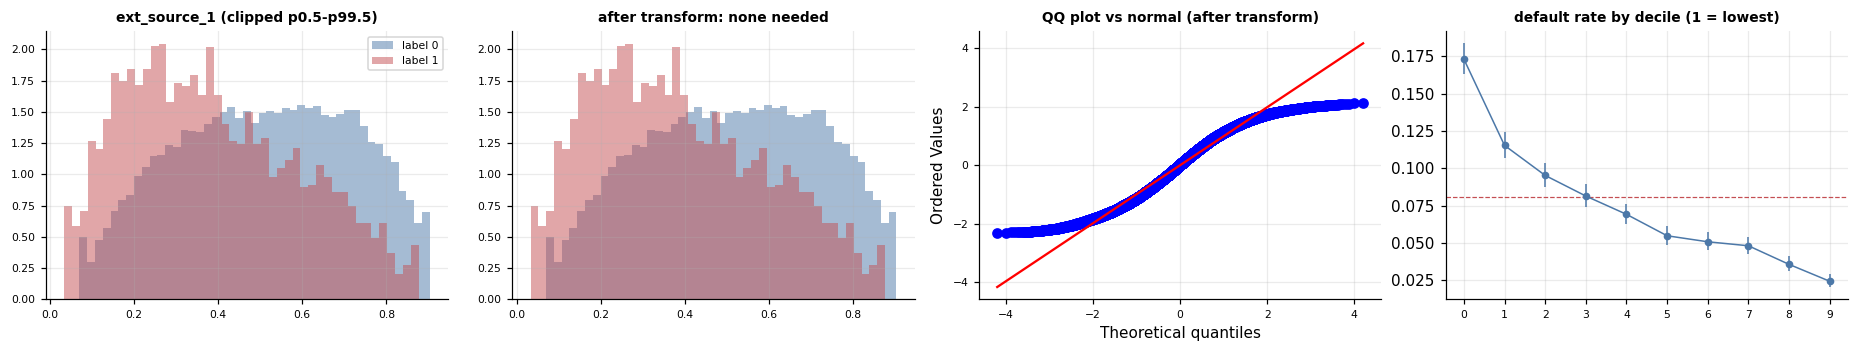

ext_source_2   |   univariate AUC 0.658 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Credit score from external source 2.
Hypothesis: High score -> fewer defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"170,833.0000",0.2155,"90,952.0000",0.5145,0.1913,0.0000,0.0295,0.1335,0.3921,0.5663,0.6642,0.7478,0.7824,0.8550,-0.7921,-0.2768,0.0000,0.0000,0.0000


Mann-Whitney: AUC=0.3418, Cliff's δ=-0.316, p=0 | χ² by decile p=0 | median label0=0.574, label1=0.438
Transform : Yeo-Johnson: skewness -0.79 -> -0.21 after Yeo-Johnson | Pearson correlation with label: original -0.1626, after transform -0.1542 | skewness of the options: original -0.79, log1p -1.03, sqrt -1.41, Yeo-Johnson -0.21
When missing: default rate 7.86% (n=369) vs 8.07% when present.


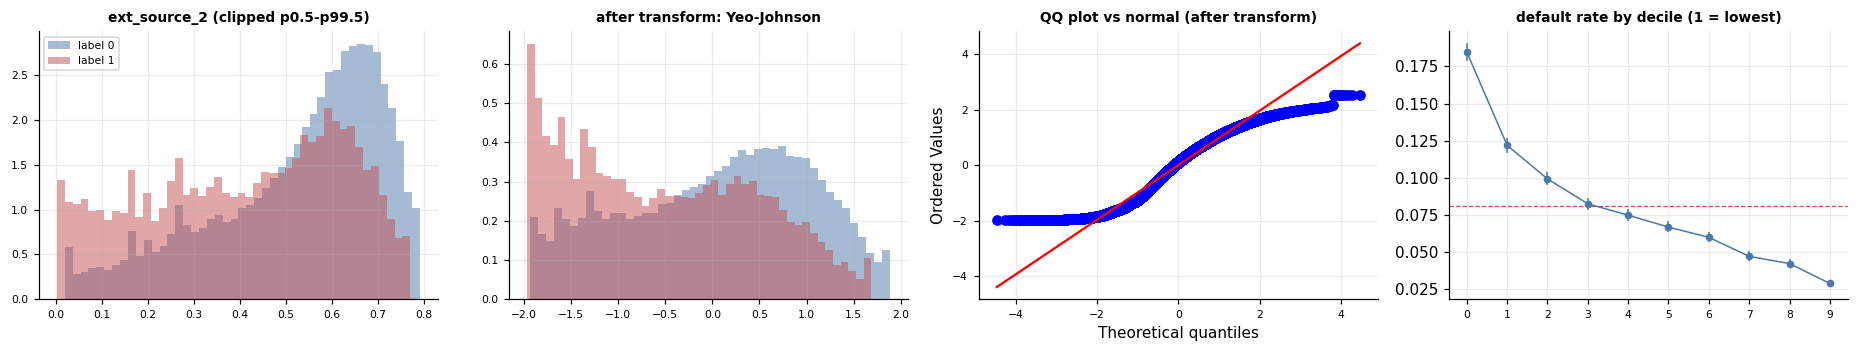

age_years   |   univariate AUC 0.584 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Age (years), from -days_birth/365.25.
Hypothesis: Younger people default more, monotonically decreasing with age.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"17,298.0000",43.9297,11.9474,21.0075,22.6037,25.7385,34.0041,43.1978,53.8973,63.5346,66.8145,69.0732,0.1113,-1.0491,0.0000,0.0000,0.0000


Mann-Whitney: AUC=0.4156, Cliff's δ=-0.169, p=4.7e-238 | χ² by decile p=2.7e-227 | median label0=43.5, label1=39.1
Transform : none needed: already roughly symmetric; only z-score standardization is needed for linear models/NN | Pearson correlation with label: original -0.0795, after transform -0.0795 | skewness of the options: original +0.11, log1p -0.29, sqrt -0.09, Yeo-Johnson -0.06


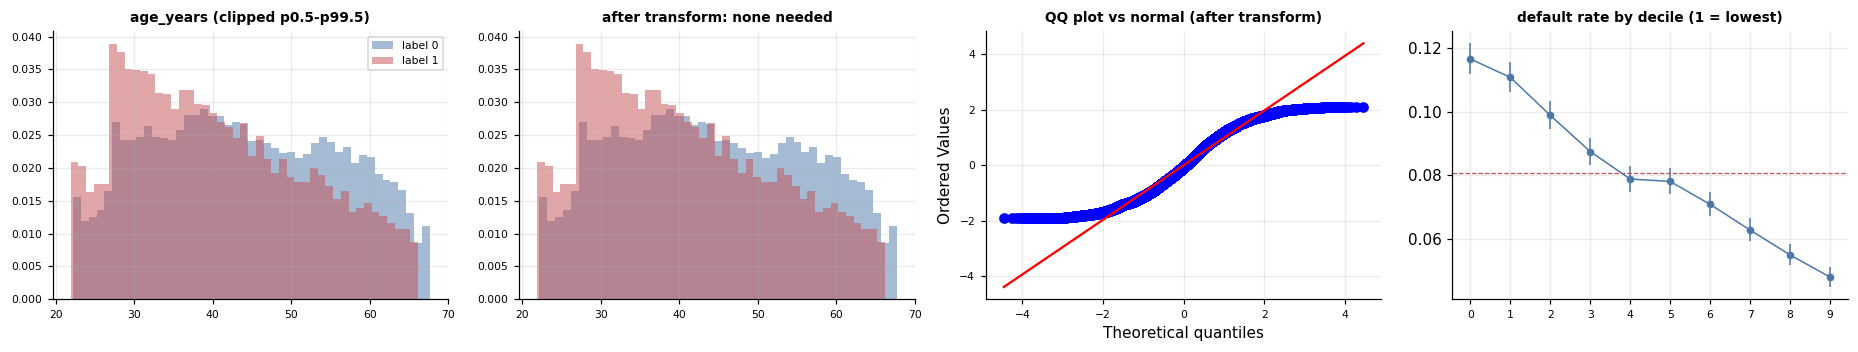

years_employed   |   univariate AUC 0.581 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Years in the current job (365243 = not working, excluded).
Hypothesis: Longer employment -> stability -> fewer defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"140,304.0000",18.0477,"11,177.0000",6.5396,6.3972,0.0027,0.3039,0.5640,2.1109,4.5175,8.7392,19.9781,30.9157,49.0404,1.9561,4.7057,0.0000,5.9678,1.4547


Mann-Whitney: AUC=0.4193, Cliff's δ=-0.161, p=9.7e-191 | χ² by decile p=6e-190 | median label0=4.63, label1=3.38
Transform : log1p: skewness +1.96 -> +0.12 after log1p | Pearson correlation with label: original -0.0736, after transform -0.0776 | skewness of the options: original +1.96, log1p +0.12, sqrt +0.78, Yeo-Johnson +0.01
When missing: default rate 5.42% (n=30,898) vs 8.66% when present. Group 365243 (not working): default rate 5.42% (n=30,898).


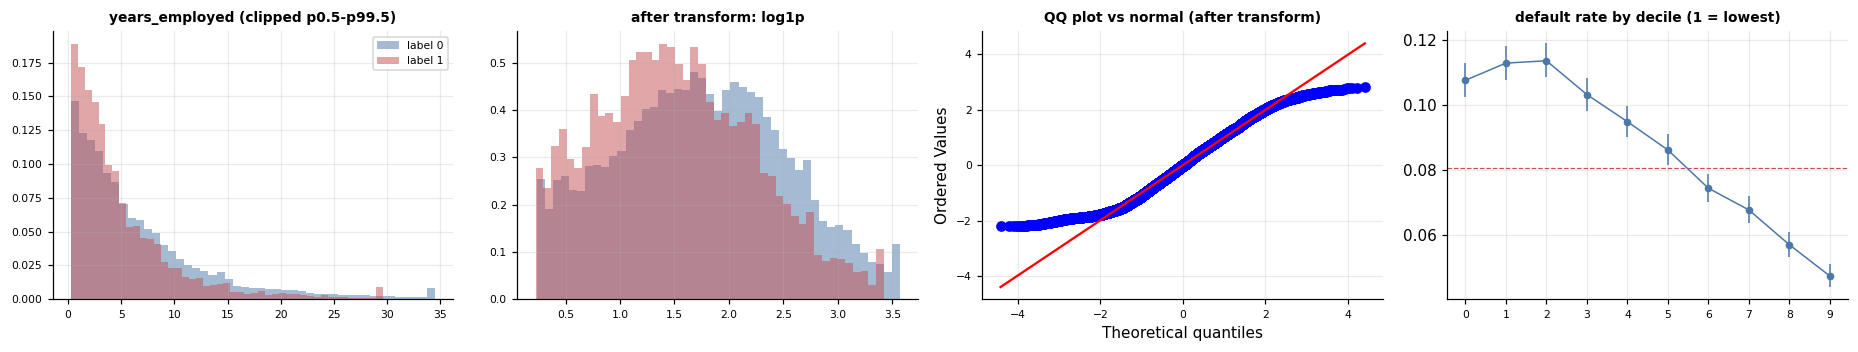

own_car_age   |   univariate AUC 0.559 (increase -> more defaults)   |   the hypothesis has no expected direction   |   shape: monotonic increasing
Meaning   : Age of the borrower's car (NaN = no car, according to hypothesis H2).
Hypothesis: Direction unclear; a very new car may indicate a better-off person.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"58,210.0000",65.9992,54.0000,12.0244,11.8950,0.0000,0.0000,1.0000,5.0000,9.0000,15.0000,30.0000,64.0000,91.0000,2.7405,9.2432,2.0323,4.6899,3.1610


Mann-Whitney: AUC=0.5595, Cliff's δ=+0.119, p=5.1e-38 | χ² by decile p=3.1e-37 | median label0=9, label1=11
Transform : Yeo-Johnson: skewness +2.74 -> +0.01 after Yeo-Johnson | Pearson correlation with label: original +0.0400, after transform +0.0475 | skewness of the options: original +2.74, log1p -0.30, sqrt +0.91, Yeo-Johnson +0.01
When missing: default rate 8.50% (n=112,992) vs 7.25% when present.


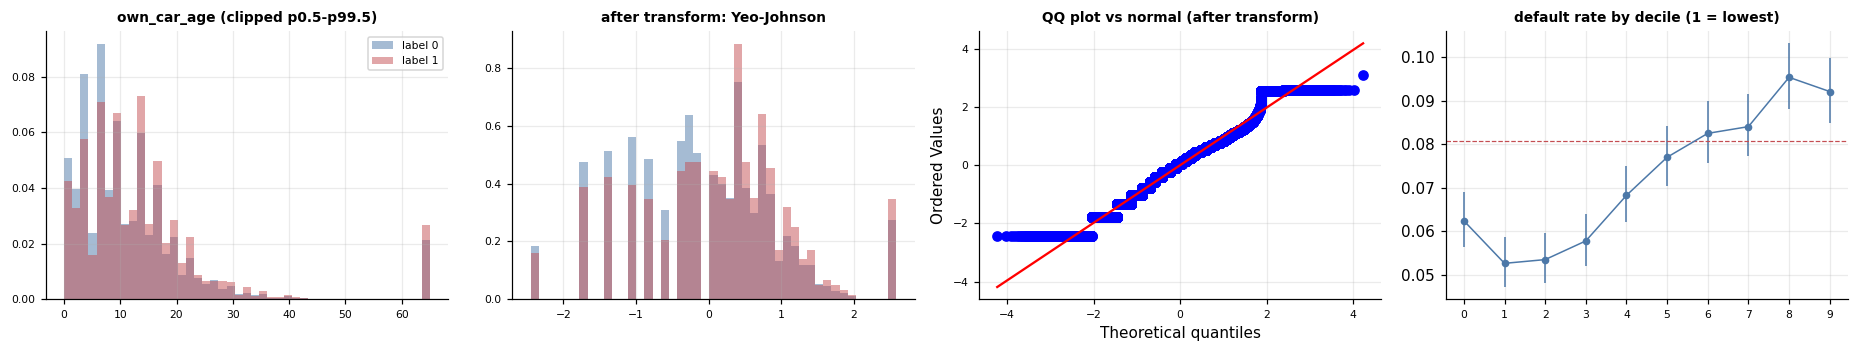

years_id_publish   |   univariate AUC 0.557 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Years since the last change of identity document.
Hypothesis: Recent document change (few years) -> more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"6,077.0000",8.1875,4.1333,0.0000,0.1643,1.0267,4.6934,8.8898,11.7645,13.5359,14.8966,19.7043,-0.3455,-1.1108,0.0035,0.0000,0.0000


Mann-Whitney: AUC=0.4432, Cliff's δ=-0.114, p=6.6e-109 | χ² by decile p=2.2e-100 | median label0=9.01, label1=7.61
Transform : none needed: already roughly symmetric; only z-score standardization is needed for linear models/NN | Pearson correlation with label: original -0.0526, after transform -0.0526 | skewness of the options: original -0.35, log1p -1.23, sqrt -0.88, Yeo-Johnson -0.31


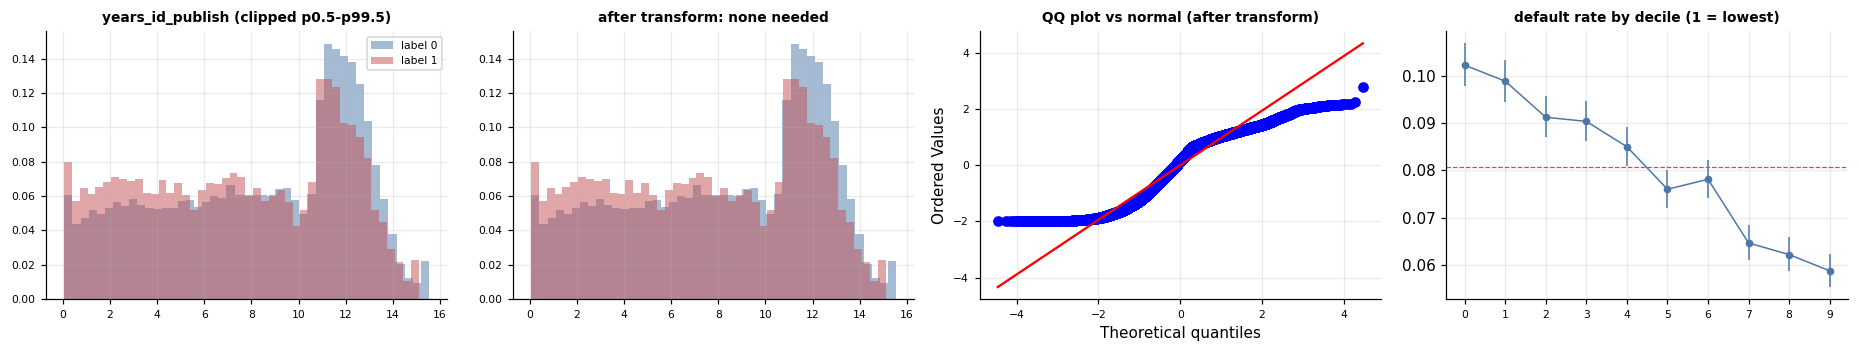

years_since_phone_change   |   univariate AUC 0.557 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Years since the last phone number change.
Hypothesis: Recent number change -> instability -> more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"3,676.0000",2.6349,2.2622,-0.0000,0.0000,0.0000,0.7502,2.0726,4.2930,6.9021,8.6434,11.4251,0.7168,-0.2967,12.2493,0.1478,0.0000


Mann-Whitney: AUC=0.4435, Cliff's δ=-0.113, p=6.3e-108 | χ² by decile p=5.9e-119 | median label0=2.12, label1=1.63
Transform : log1p: skewness +0.72 -> -0.20 after log1p | Pearson correlation with label: original -0.0552, after transform -0.0508 | skewness of the options: original +0.72, log1p -0.20, sqrt -0.24, Yeo-Johnson -0.05


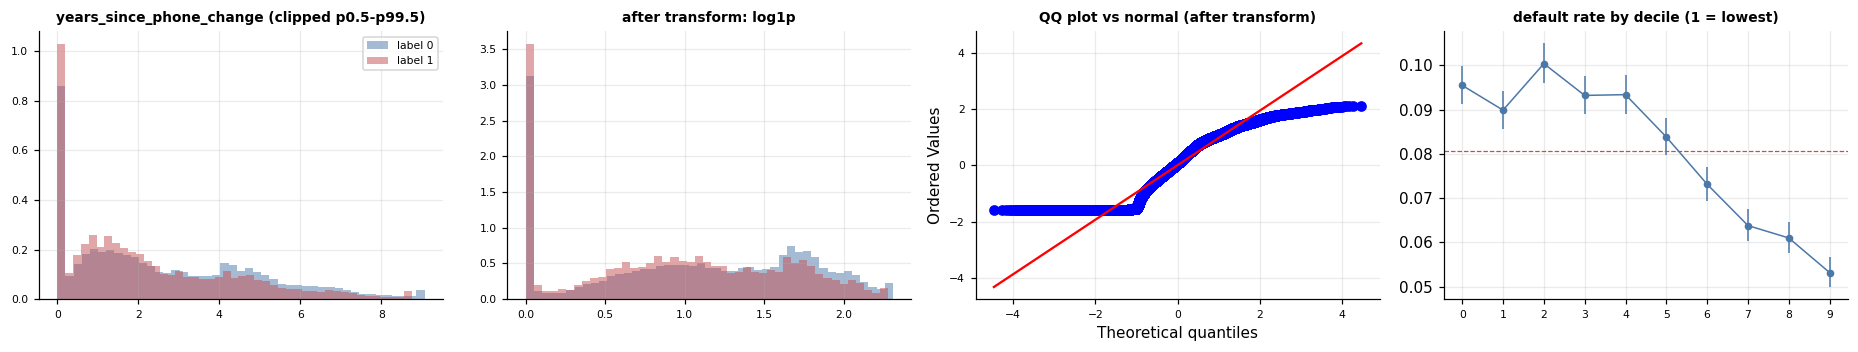

region_rating_client   |   univariate AUC 0.548 (increase -> more defaults)   |   CORRECT: direction matches the hypothesis   |   shape: few groups
Meaning   : Rating of the region where the borrower lives (1 best, 3 worst).
Hypothesis: The worse the rating (larger number), the more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,3.0000,2.0537,0.5087,1.0000,1.0000,1.0000,2.0000,2.0000,2.0000,3.0000,3.0000,3.0000,0.0901,0.8021,0.0000,0.0000,0.0000


Mann-Whitney: AUC=0.5481, Cliff's δ=+0.096, p=1.3e-78 | χ² by decile p=4.3e-130 | median label0=2, label1=2
Transform : none needed: already roughly symmetric; only z-score standardization is needed for linear models/NN | Pearson correlation with label: original +0.0590, after transform +0.0590 | skewness of the options: original +0.09, log1p -0.66, sqrt -0.49, Yeo-Johnson +0.04


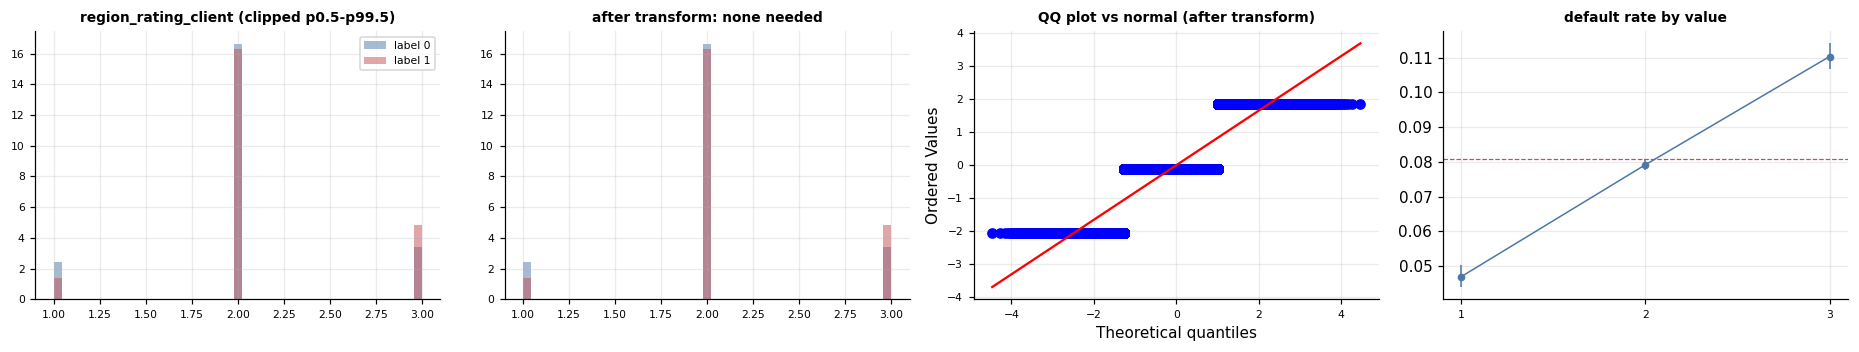

years_registration   |   univariate AUC 0.543 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic decreasing
Meaning   : Years since the last change of residence registration.
Hypothesis: Recent registration change (few years) -> instability -> more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"14,909.0000",13.6755,9.6530,-0.0000,0.1369,0.9117,5.4976,12.3614,20.5065,31.3154,38.0396,67.5483,0.5877,-0.3283,0.0222,0.2039,0.0006


Mann-Whitney: AUC=0.4574, Cliff's δ=-0.085, p=2.9e-62 | χ² by decile p=4.1e-61 | median label0=12.5, label1=11.1
Transform : Yeo-Johnson: skewness +0.59 -> -0.12 after Yeo-Johnson | Pearson correlation with label: original -0.0417, after transform -0.0402 | skewness of the options: original +0.59, log1p -0.79, sqrt -0.18, Yeo-Johnson -0.12


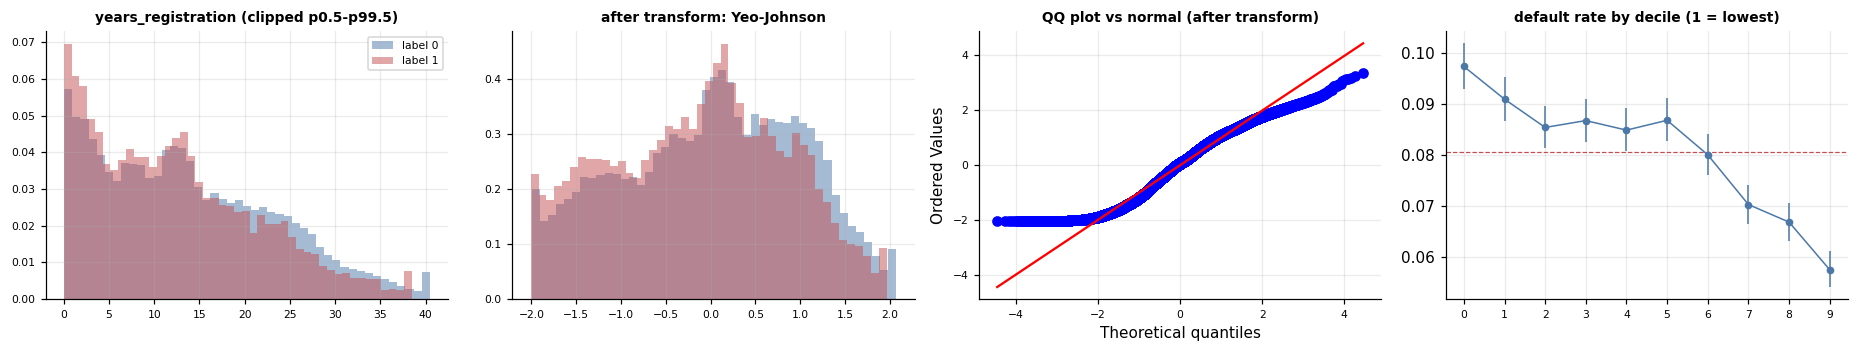

amt_goods_price   |   univariate AUC 0.536 (increase -> fewer defaults)   |   the hypothesis has no expected direction   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Price of the goods the loan is used to buy.
Hypothesis: Almost identical to the loan amount (credit ≈ goods); little separate information.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,904.0000,"538,056.8967","368,572.7342","45,000.0000","67,500.0000","135,000.0000","238,500.0000","450,000.0000","679,500.0000","1,305,000.0000","1,800,000.0000","2,254,500.0000",1.3098,2.0252,0.0000,4.7879,0.3633


Mann-Whitney: AUC=0.4641, Cliff's δ=-0.072, p=1.4e-44 | χ² by decile p=1.6e-224 | median label0=4.5e+05, label1=4.5e+05
Transform : Yeo-Johnson: skewness +1.31 -> -0.02 after Yeo-Johnson | Pearson correlation with label: original -0.0420, after transform -0.0281 | skewness of the options: original +1.31, log1p -0.29, sqrt +0.51, Yeo-Johnson -0.02


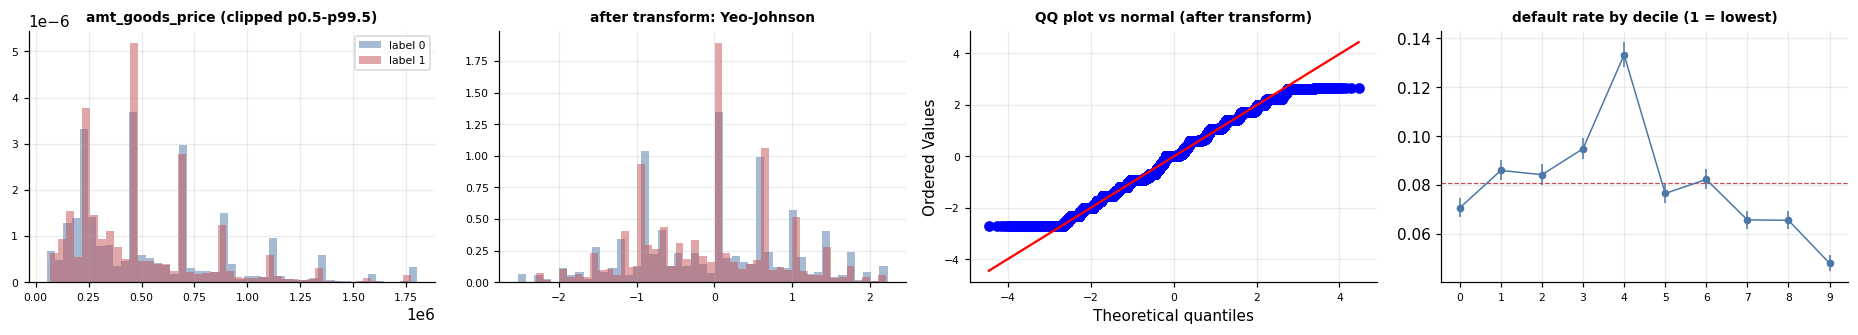

region_population_relative   |   univariate AUC 0.535 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: non-monotonic / noisy
Meaning   : Relative population density of the region (normalized).
Hypothesis: Densely populated (urban) regions have fewer defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,81.0000,0.0208,0.0138,0.0003,0.0021,0.0050,0.0100,0.0188,0.0287,0.0462,0.0725,0.0725,1.4846,3.2576,0.0000,2.7009,0.0000


Mann-Whitney: AUC=0.4650, Cliff's δ=-0.070, p=1.5e-42 | χ² by decile p=9.6e-72 | median label0=0.0188, label1=0.0186
Transform : Yeo-Johnson: skewness +1.48 -> +0.10 after Yeo-Johnson | Pearson correlation with label: original -0.0383, after transform -0.0340 | skewness of the options: original +1.48, log1p +1.42, sqrt +0.44, Yeo-Johnson +0.10


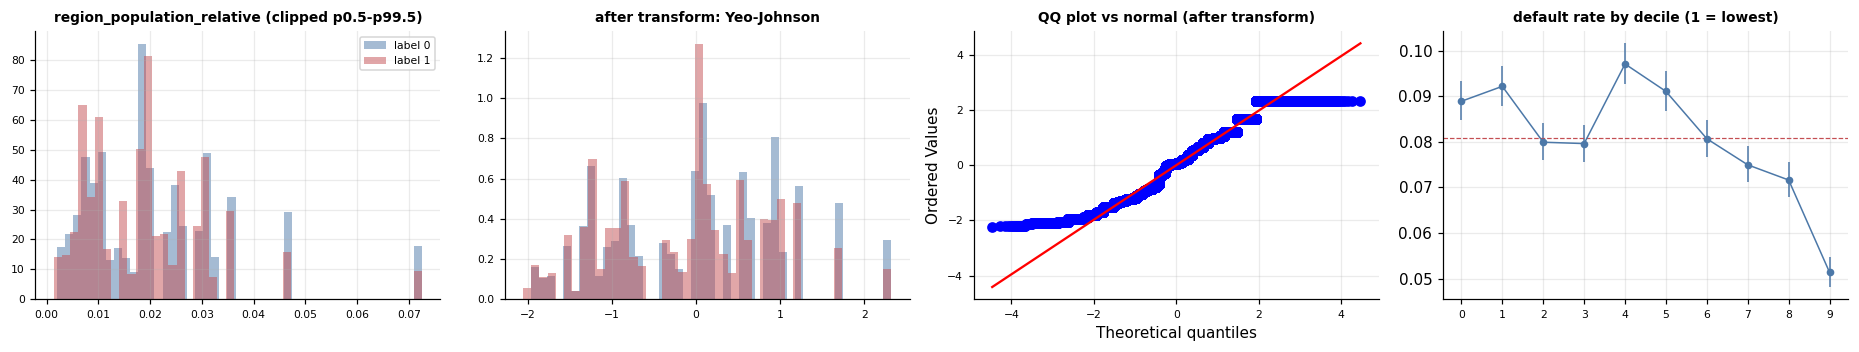

flag_emp_phone   |   univariate AUC 0.532 (increase -> more defaults)   |   OPPOSITE: direction contradicts the hypothesis   |   shape: few groups
Meaning   : Has a work phone number.
Hypothesis: Having a work number = currently employed -> lower risk.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,2.0000,0.8195,0.3846,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,-1.6614,0.7602,18.0506,0.0000,0.0000


Mann-Whitney: AUC=0.5322, Cliff's δ=+0.064, p=2.7e-36 | χ² by decile p=1.8e-79 | median label0=1, label1=1
Transform : log1p: skewness -1.66 -> -1.66 after log1p | Pearson correlation with label: original +0.0456, after transform +0.0456 | skewness of the options: original -1.66, log1p -1.66, sqrt -1.66, Yeo-Johnson -1.66


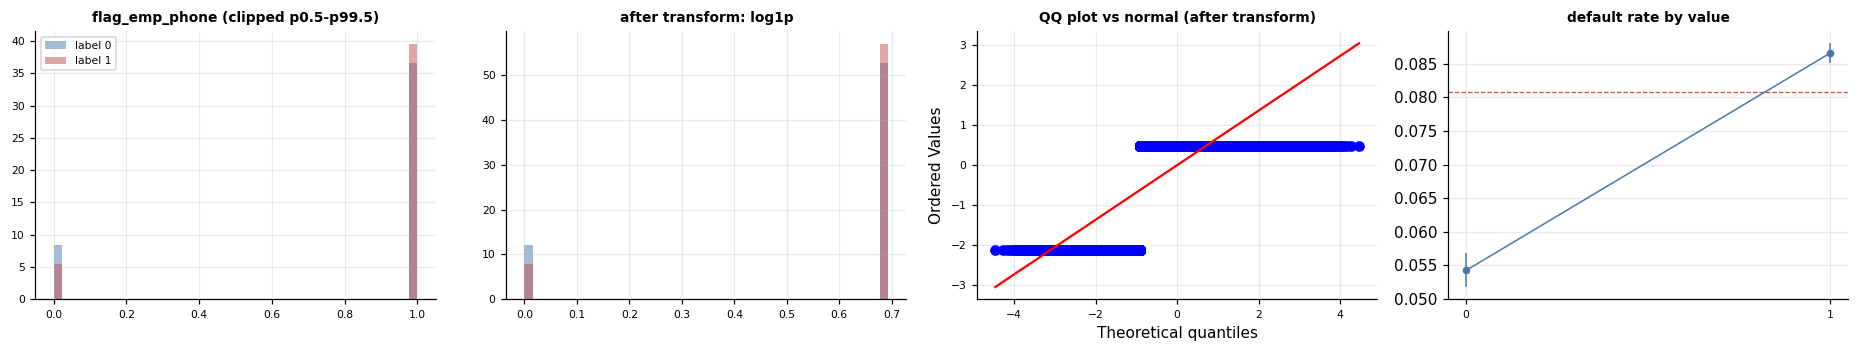

flag_work_phone   |   univariate AUC 0.521 (increase -> more defaults)   |   the hypothesis has no expected direction   |   shape: few groups
Meaning   : Has a workplace phone number (separate).
Hypothesis: Direction unclear.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,2.0000,0.1997,0.3998,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,1.5022,0.2565,80.0277,0.0000,0.0000


Mann-Whitney: AUC=0.5214, Cliff's δ=+0.043, p=7.5e-17 | χ² by decile p=2.5e-33 | median label0=0, label1=0
Transform : log1p: skewness +1.50 -> +1.50 after log1p | Pearson correlation with label: original +0.0291, after transform +0.0291 | skewness of the options: original +1.50, log1p +1.50, sqrt +1.50, Yeo-Johnson +1.50


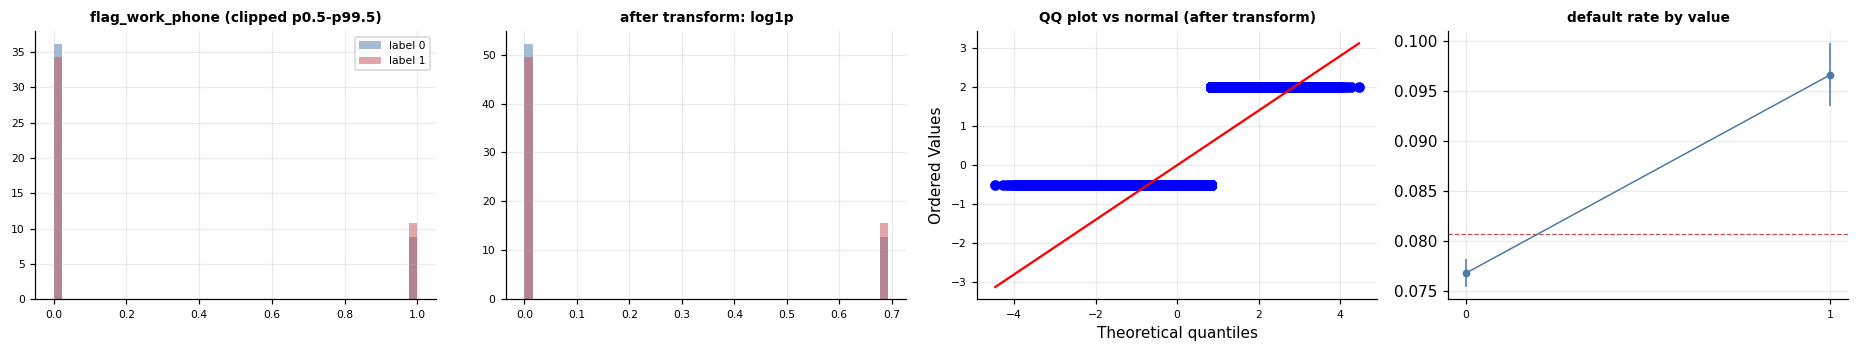

credit_amount   |   univariate AUC 0.521 (increase -> fewer defaults)   |   the hypothesis has no expected direction   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Loan amount.
Hypothesis: Direction unclear: large loans go with high income but also with a large debt burden.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"4,796.0000","599,129.3095","402,816.9969","45,000.0000","76,410.0000","135,000.0000","270,000.0000","514,602.0000","808,650.0000","1,350,000.0000","1,868,801.7600","4,050,000.0000",1.2384,1.9685,0.0000,2.1203,0.1530


Mann-Whitney: AUC=0.4788, Cliff's δ=-0.042, p=1.2e-16 | χ² by decile p=7.7e-130 | median label0=5.19e+05, label1=4.95e+05
Transform : Yeo-Johnson: skewness +1.24 -> -0.02 after Yeo-Johnson | Pearson correlation with label: original -0.0327, after transform -0.0185 | skewness of the options: original +1.24, log1p -0.34, sqrt +0.45, Yeo-Johnson -0.02


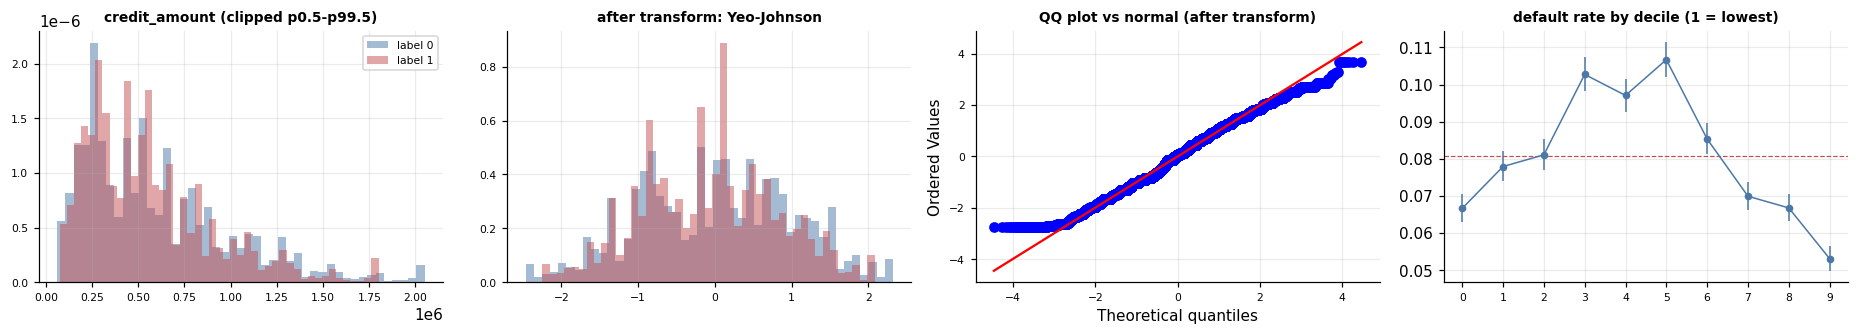

amt_req_credit_bureau_year   |   univariate AUC 0.521 (increase -> more defaults)   |   CORRECT: direction matches the hypothesis   |   shape: monotonic increasing
Meaning   : Number of credit bureau queries in 1 year.
Hypothesis: Many -> riskier.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"148,086.0000",13.5022,23.0000,1.9036,1.8722,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,6.0000,8.0000,23.0000,1.2429,1.9407,26.9222,1.2547,0.0230


Mann-Whitney: AUC=0.5205, Cliff's δ=+0.041, p=2.9e-13 | χ² by decile p=4.6e-13 | median label0=1, label1=2
Transform : log1p: skewness +1.24 -> +0.03 after log1p | Pearson correlation with label: original +0.0197, after transform +0.0195 | skewness of the options: original +1.24, log1p +0.03, sqrt -0.08, Yeo-Johnson +0.01
When missing: default rate 10.38% (n=23,116) vs 7.71% when present.


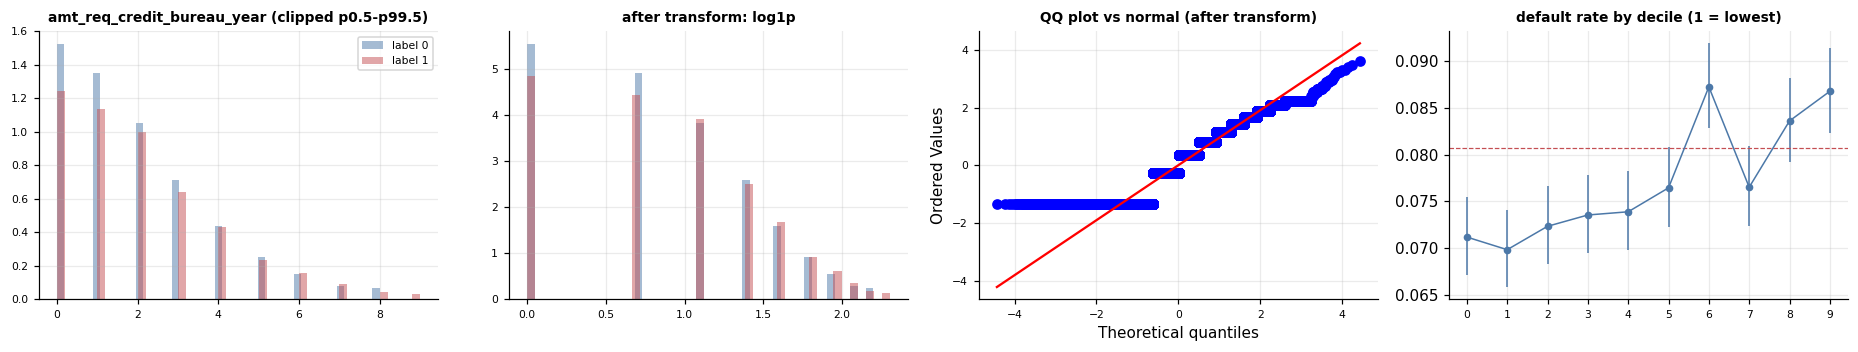

income   |   univariate AUC 0.518 (increase -> fewer defaults)   |   CORRECT: direction matches the hypothesis   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Total annual income.
Hypothesis: Higher income -> fewer defaults but a weak effect; heavily right-skewed distribution (needs log).


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"1,641.0000","168,371.2137","107,234.7935","26,100.0000","45,000.0000","67,500.0000","112,500.0000","146,250.0000","202,500.0000","337,500.0000","463,500.0000","13,500,000.0000",20.1179,"1,831.0028",0.0000,4.5467,0.9725


Mann-Whitney: AUC=0.4818, Cliff's δ=-0.036, p=1.3e-12 | χ² by decile p=1.4e-25 | median label0=1.48e+05, label1=1.35e+05
Transform : log1p: skewness +20.12 -> +0.16 after log1p | Pearson correlation with label: original -0.0216, after transform -0.0186 | skewness of the options: original +20.12, log1p +0.16, sqrt +1.70, Yeo-Johnson -0.01


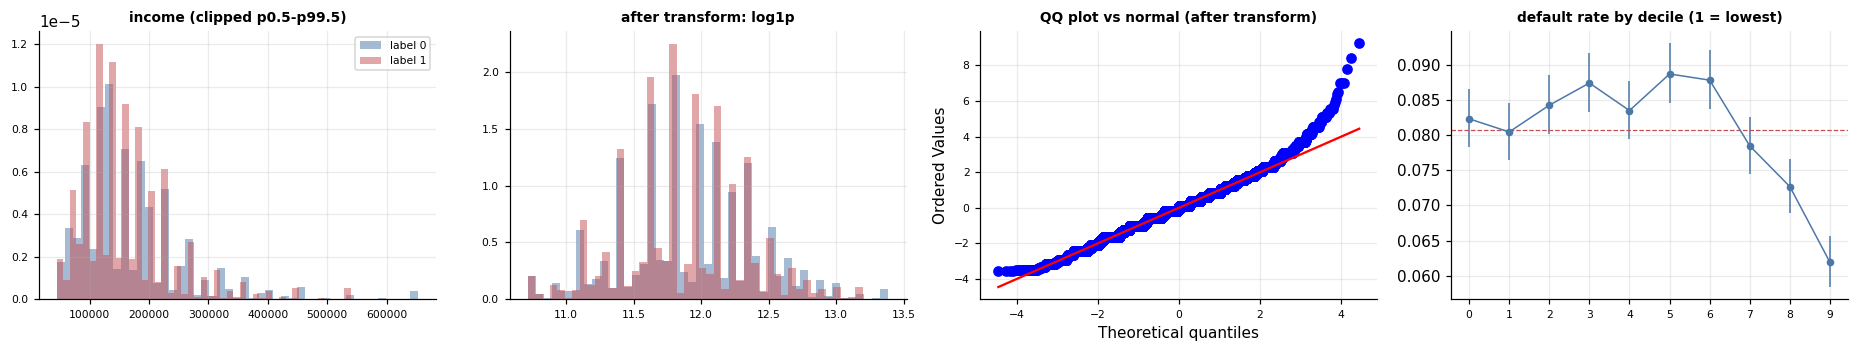

cnt_children   |   univariate AUC 0.517 (increase -> more defaults)   |   CORRECT: direction matches the hypothesis   |   shape: non-monotonic / noisy
Meaning   : Number of children.
Hypothesis: More children -> heavier spending burden -> more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,13.0000,0.4165,0.7201,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,14.0000,1.8872,5.3689,70.0634,1.3697,0.0386


Mann-Whitney: AUC=0.5167, Cliff's δ=+0.033, p=6.4e-11 | χ² by decile p=1.6e-12 | median label0=0, label1=0
Transform : Yeo-Johnson: skewness +1.89 -> +0.89 after Yeo-Johnson | Pearson correlation with label: original +0.0180, after transform +0.0200 | skewness of the options: original +1.89, log1p +1.21, sqrt +1.08, Yeo-Johnson +0.89


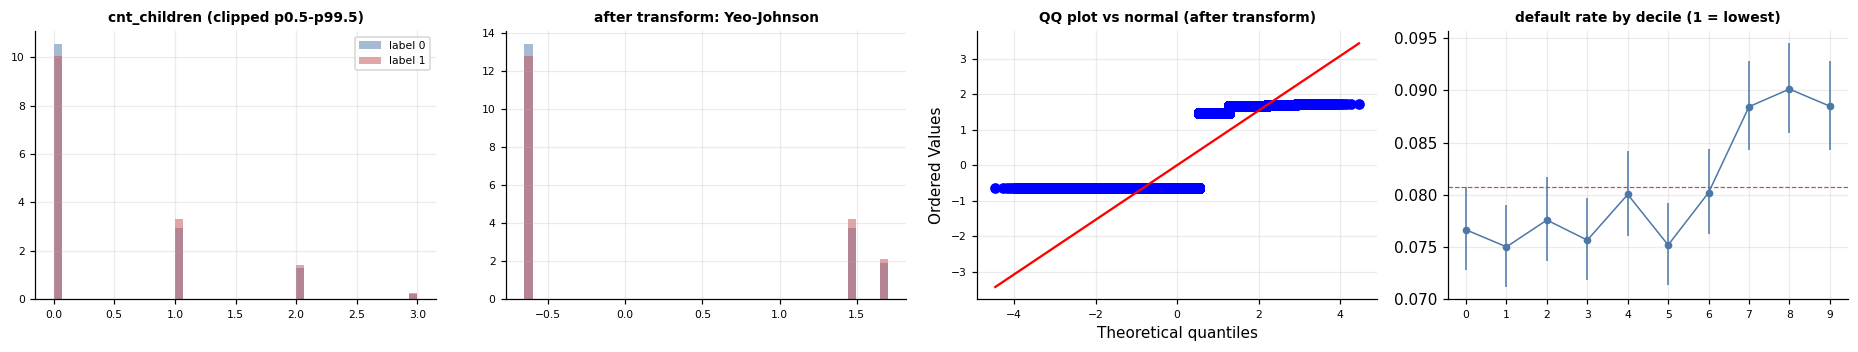

amt_req_credit_bureau_qrt   |   univariate AUC 0.507 (increase -> fewer defaults)   |   NO EVIDENCE of a direction (p > 0.01)   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Number of credit bureau queries in 1 quarter.
Hypothesis: Many -> riskier.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"148,086.0000",13.5022,11.0000,0.2675,0.9145,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,2.0000,261.0000,157.3369,"44,614.9374",80.9077,0.0000,0.0000


Mann-Whitney: AUC=0.4930, Cliff's δ=-0.014, p=0.012 | χ² by decile p=4.5e-09 | median label0=0, label1=0
Transform : Yeo-Johnson: skewness +157.34 -> +1.57 after Yeo-Johnson | Pearson correlation with label: original -0.0031, after transform -0.0106 | skewness of the options: original +157.34, log1p +1.96, sqrt +2.04, Yeo-Johnson +1.57
When missing: default rate 10.38% (n=23,116) vs 7.71% when present.


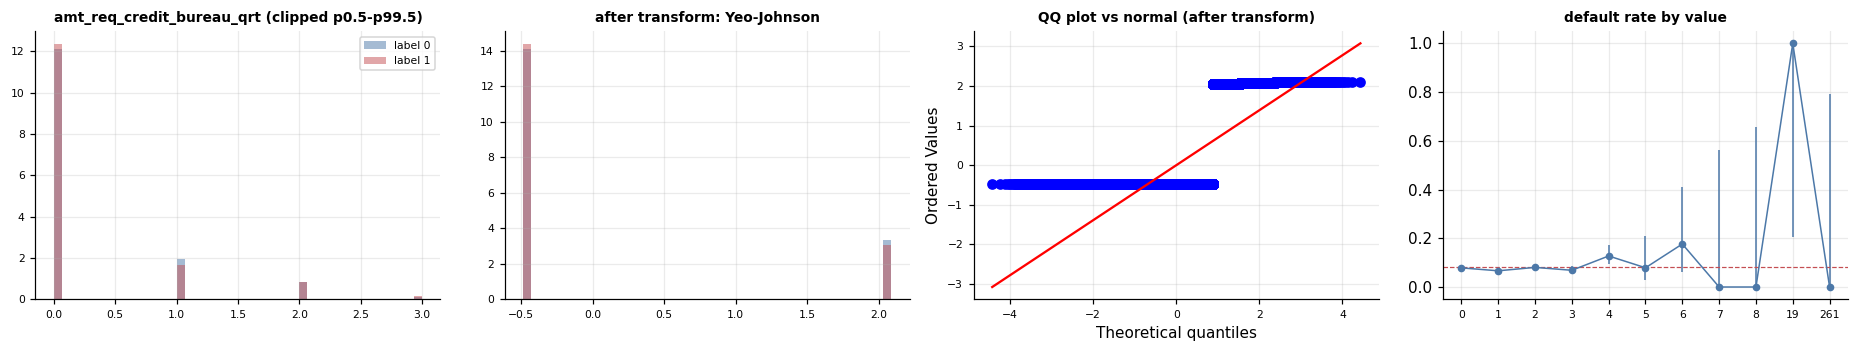

cnt_fam_members   |   univariate AUC 0.506 (increase -> more defaults)   |   NO EVIDENCE of a direction (p > 0.01)   |   shape: U-shaped (minimum in the middle)
Meaning   : Number of household members.
Hypothesis: Larger household -> heavier burden -> more defaults (reinforces cnt_children).


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,200.0000",0.0012,15.0000,2.1523,0.9088,1.0000,1.0000,1.0000,2.0000,2.0000,3.0000,4.0000,5.0000,16.0000,0.9435,1.9320,0.0000,1.2757,0.0356


Mann-Whitney: AUC=0.5062, Cliff's δ=+0.012, p=0.015 | χ² by decile p=7.5e-07 | median label0=2, label1=2
Transform : log1p: skewness +0.94 -> +0.12 after log1p | Pearson correlation with label: original +0.0080, after transform +0.0058 | skewness of the options: original +0.94, log1p +0.12, sqrt +0.32, Yeo-Johnson +0.01
When missing: default rate 0.00% (n=2) vs 8.07% when present.


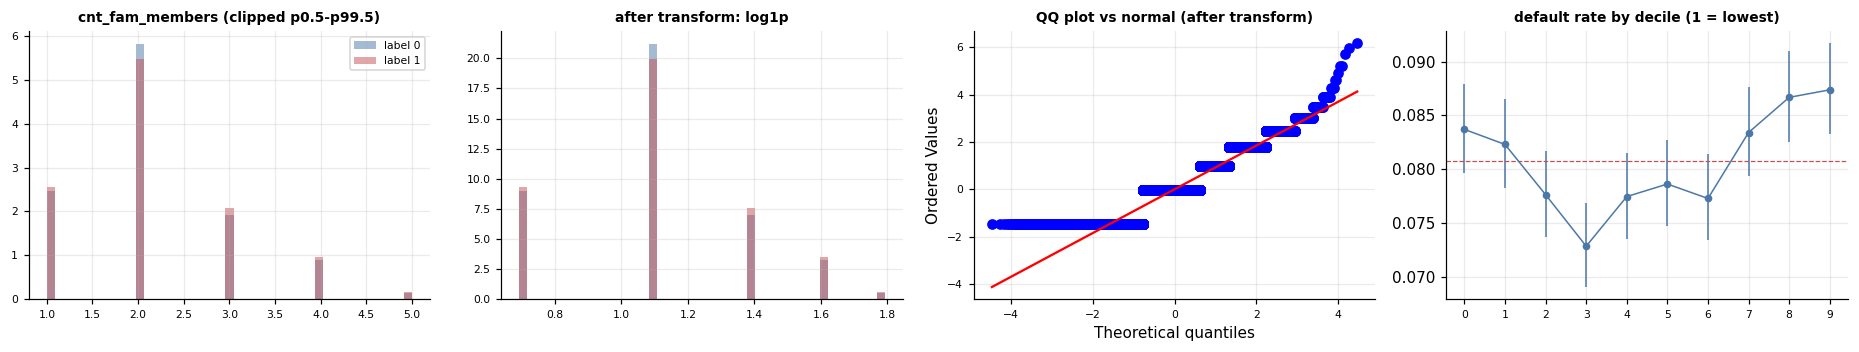

amt_req_credit_bureau_mon   |   univariate AUC 0.506 (increase -> fewer defaults)   |   NO EVIDENCE of a direction (p > 0.01)   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Number of credit bureau queries in 1 month.
Hypothesis: Many -> riskier.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"148,086.0000",13.5022,21.0000,0.2684,0.9210,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,4.0000,23.0000,7.6733,85.2539,83.5548,0.0000,0.0000


Mann-Whitney: AUC=0.4940, Cliff's δ=-0.012, p=0.033 | χ² by decile p=0.068 | median label0=0, label1=0
Transform : Yeo-Johnson: skewness +7.67 -> +1.81 after Yeo-Johnson | Pearson correlation with label: original -0.0142, after transform -0.0078 | skewness of the options: original +7.67, log1p +2.94, sqrt +2.73, Yeo-Johnson +1.81
When missing: default rate 10.38% (n=23,116) vs 7.71% when present.


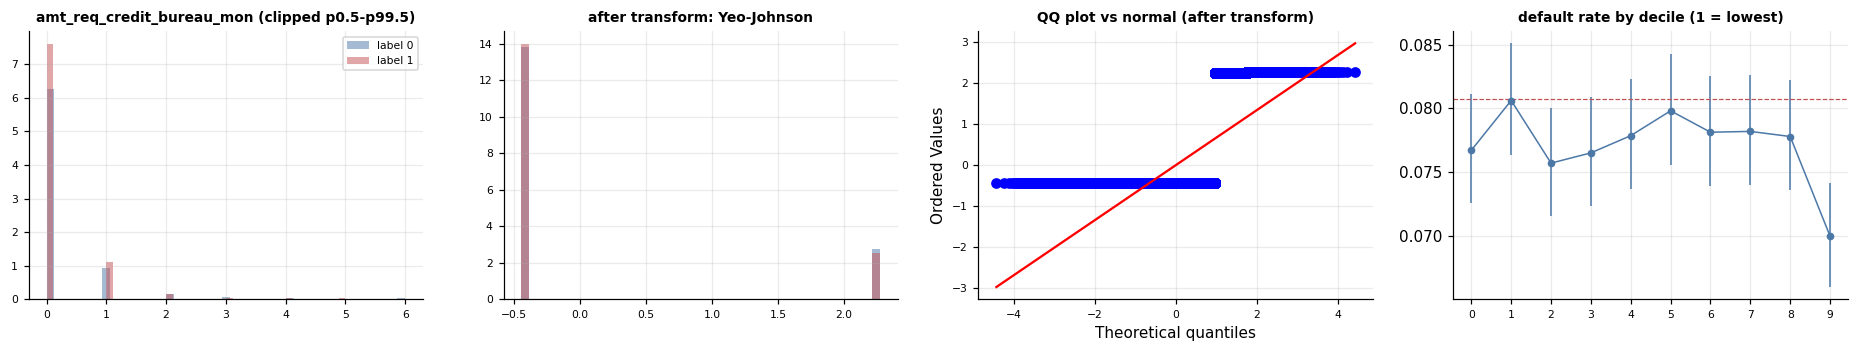

annuity   |   univariate AUC 0.502 (increase -> fewer defaults)   |   NO EVIDENCE of a direction (p > 0.01)   |   shape: bell-shaped ∩ (peak in the middle)
Meaning   : Installment amount per period.
Hypothesis: High installment -> cash-flow pressure -> more defaults.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,"12,241.0000","27,120.0660","14,450.2527","1,980.0000","6,187.5000","9,000.0000","16,546.5000","24,916.5000","34,600.5000","53,329.5000","70,132.3650","170,986.5000",1.4414,5.1905,0.0000,2.4410,0.3394


Mann-Whitney: AUC=0.4977, Cliff's δ=-0.005, p=0.36 | χ² by decile p=6.4e-67 | median label0=2.49e+04, label1=2.52e+04
Transform : Yeo-Johnson: skewness +1.44 -> -0.01 after Yeo-Johnson | Pearson correlation with label: original -0.0146, after transform -0.0042 | skewness of the options: original +1.44, log1p -0.35, sqrt +0.44, Yeo-Johnson -0.01


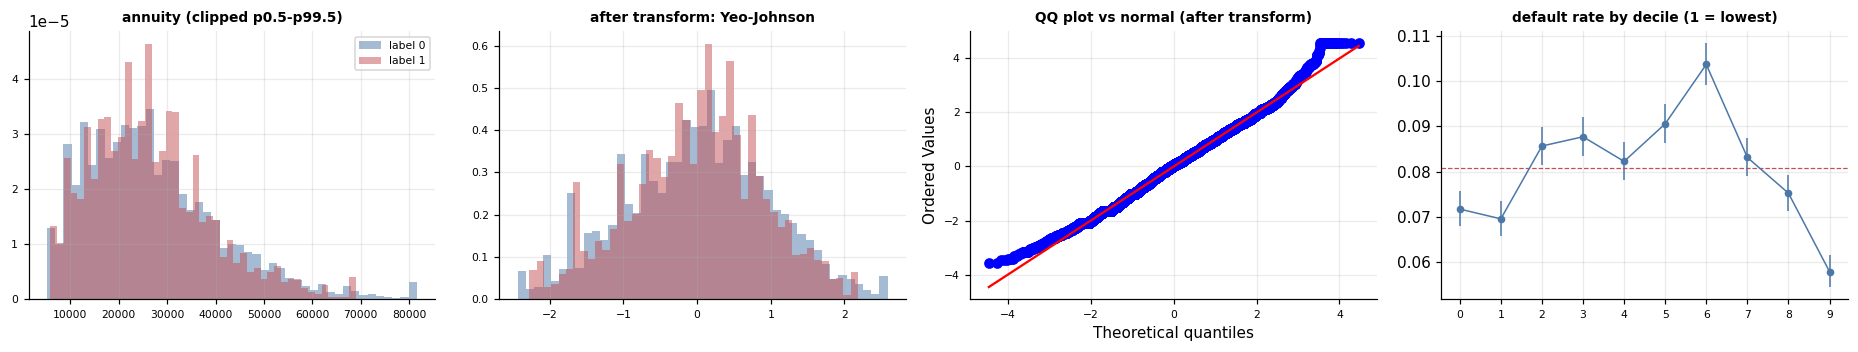

amt_req_credit_bureau_hour   |   univariate AUC 0.500 (increase -> more defaults)   |   NO EVIDENCE of a direction (p > 0.01)   |   shape: non-monotonic / noisy
Meaning   : Number of credit bureau queries in the 1 hour before the application.
Hypothesis: A burst of queries -> applying in many places -> more defaults (very rare).


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"148,086.0000",13.5022,5.0000,0.0067,0.0862,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000,14.6421,264.2856,99.3700,0.0000,0.0000


Mann-Whitney: AUC=0.5001, Cliff's δ=+0.000, p=0.96 | χ² by decile p=0.94 | median label0=0, label1=0
Transform : Yeo-Johnson: skewness +14.64 -> +12.48 after Yeo-Johnson | Pearson correlation with label: original +0.0006, after transform +0.0010 | skewness of the options: original +14.64, log1p +13.01, sqrt +12.74, Yeo-Johnson +12.48
When missing: default rate 10.38% (n=23,116) vs 7.71% when present.


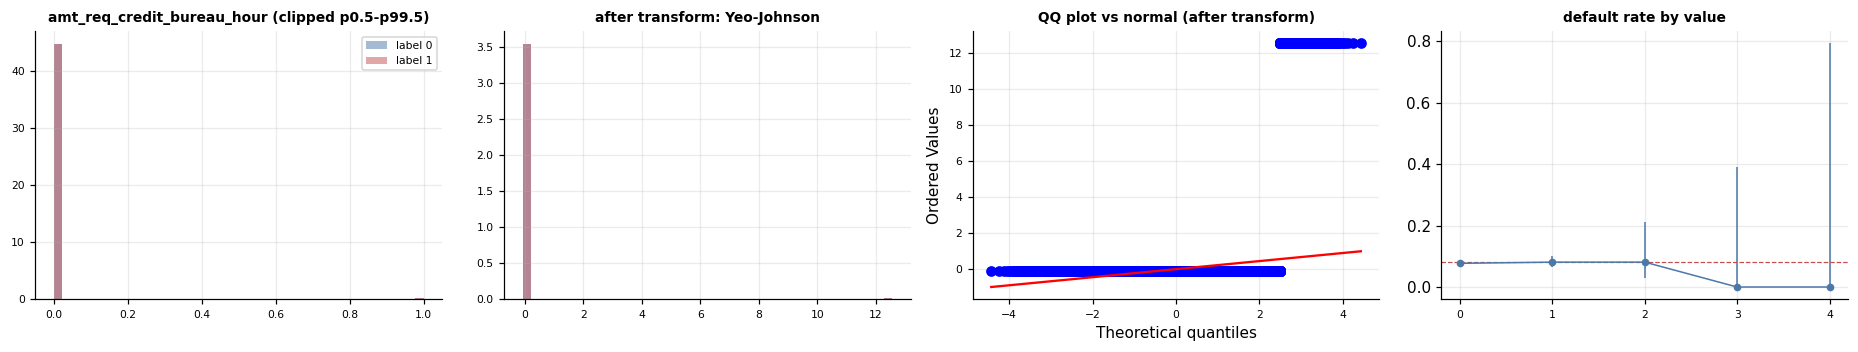

flag_mobil   |   univariate AUC 0.500 (increase -> more defaults)   |   the hypothesis has no expected direction   |   shape: few groups
Meaning   : Provided a mobile phone number (constant column).
Hypothesis: Constant, carries no information.


,n non-missing,% missing,unique values,mean,std dev,min,p1,p5,p25,median,p75,p95,p99,max,skewness,kurtosis,% zero,% Tukey outliers (1.5×IQR),% extreme outliers (3×IQR)
0,"171,202.0000",0.0000,2.0000,1.0000,0.0024,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,-413.7620,"171,197.0000",0.0006,0.0000,0.0000


Mann-Whitney: AUC=0.5000, Cliff's δ=+0.000, p=1 | χ² by decile p=1 | median label0=1, label1=1
Transform : sqrt: skewness -413.76 -> -413.76 after sqrt | Pearson correlation with label: original +0.0007, after transform +0.0007 | skewness of the options: original -413.76, log1p -413.76, sqrt -413.76, Yeo-Johnson -413.76


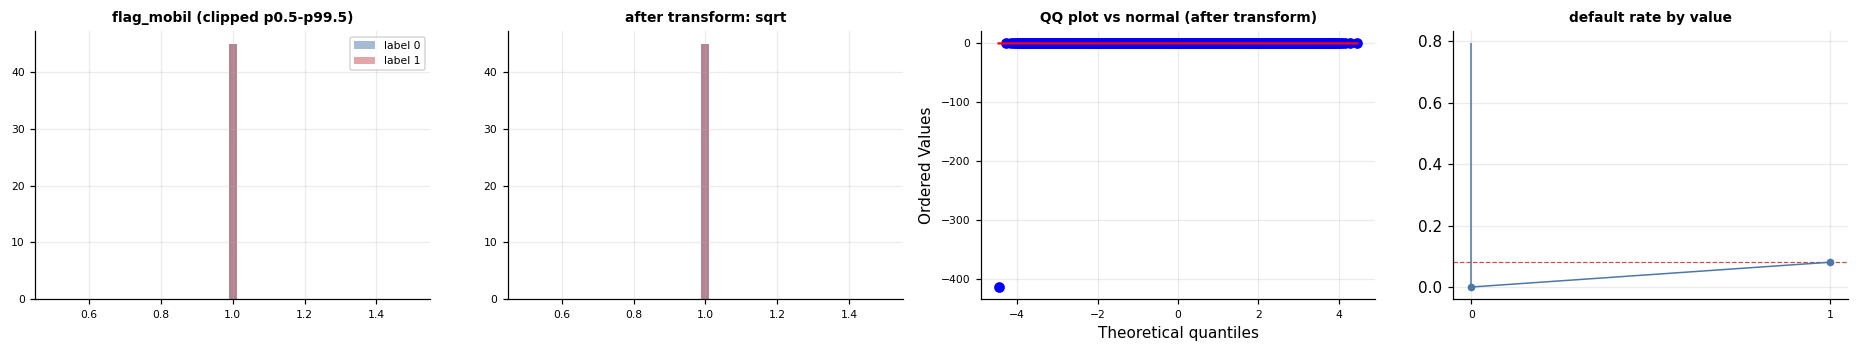

In [16]:
# ---------------- data dictionary: meaning + hypothesis ----------------
# direction: +1 increase -> more defaults, -1 increase -> fewer, 0 no clear expectation
DICT = {
    "name_contract_type": ("Contract type: cash loan (Cash) or card / revolving credit line (Revolving).", "Cash loans are riskier than Revolving (large loans, fixed installments).", ["Cash loans"]),
    "code_gender": ("Borrower's gender (XNA = unknown).", "Men default more than women; XNA is too rare to conclude anything.", ["M"]),
    "cnt_children": ("Number of children.", "More children -> heavier spending burden -> more defaults.", +1),
    "income": ("Total annual income.", "Higher income -> fewer defaults but a weak effect; heavily right-skewed distribution (needs log).", -1),
    "credit_amount": ("Loan amount.", "Direction unclear: large loans go with high income but also with a large debt burden.", 0),
    "annuity": ("Installment amount per period.", "High installment -> cash-flow pressure -> more defaults.", +1),
    "amt_goods_price": ("Price of the goods the loan is used to buy.", "Almost identical to the loan amount (credit ≈ goods); little separate information.", 0),
    "name_income_type": ("Source of income (Working, Pensioner, Commercial associate...).", "Pensioner/State servant are low risk; Unemployed, Maternity leave are the riskiest.", ["Unemployed", "Maternity leave", "Working"]),
    "name_education_type": ("Education level.", "Lower education -> more defaults (natural order: Lower secondary > Secondary > Incomplete higher > Higher > Academic).", ["Lower secondary", "Secondary / secondary special"]),
    "name_family_status": ("Marital status.", "Single / civil marriage are riskier than married.", ["Single / not married", "Civil marriage", "Separated"]),
    "name_housing_type": ("Type of housing.", "Living with parents or renting is riskier than owning a home.", ["With parents", "Rented apartment"]),
    "region_population_relative": ("Relative population density of the region (normalized).", "Densely populated (urban) regions have fewer defaults.", -1),
    "age_years": ("Age (years), from -days_birth/365.25.", "Younger people default more, monotonically decreasing with age.", -1),
    "years_employed": ("Years in the current job (365243 = not working, excluded).", "Longer employment -> stability -> fewer defaults.", -1),
    "years_registration": ("Years since the last change of residence registration.", "Recent registration change (few years) -> instability -> more defaults.", -1),
    "years_id_publish": ("Years since the last change of identity document.", "Recent document change (few years) -> more defaults.", -1),
    "own_car_age": ("Age of the borrower's car (NaN = no car, according to hypothesis H2).", "Direction unclear; a very new car may indicate a better-off person.", 0),
    "flag_mobil": ("Provided a mobile phone number (constant column).", "Constant, carries no information.", 0),
    "flag_emp_phone": ("Has a work phone number.", "Having a work number = currently employed -> lower risk.", -1),
    "flag_work_phone": ("Has a workplace phone number (separate).", "Direction unclear.", 0),
    "occupation_type": ("Occupation (NaN = not working, according to H5).", "Manual labor / drivers are riskier than office staff / managers.", ["Laborers", "Drivers", "Low-skill Laborers", "Sales staff", "Cooking staff"]),
    "cnt_fam_members": ("Number of household members.", "Larger household -> heavier burden -> more defaults (reinforces cnt_children).", +1),
    "region_rating_client": ("Rating of the region where the borrower lives (1 best, 3 worst).", "The worse the rating (larger number), the more defaults.", +1),
    "organization_type": ("Type of organization where the borrower works (many levels).", "Some industries (construction, transport, self-employed) are riskier; XNA = not working.", ["Transport: type 3", "Construction", "Self-employed"]),
    "ext_source_1": ("Credit score from external source 1 (0-1, high = good).", "High score -> fewer defaults (the strongest signal).", -1),
    "ext_source_2": ("Credit score from external source 2.", "High score -> fewer defaults.", -1),
    "ext_source_3": ("Credit score from external source 3.", "High score -> fewer defaults.", -1),
    "years_since_phone_change": ("Years since the last phone number change.", "Recent number change -> instability -> more defaults.", -1),
    "amt_req_credit_bureau_hour": ("Number of credit bureau queries in the 1 hour before the application.", "A burst of queries -> applying in many places -> more defaults (very rare).", +1),
    "amt_req_credit_bureau_mon": ("Number of credit bureau queries in 1 month.", "Many -> riskier.", +1),
    "amt_req_credit_bureau_qrt": ("Number of credit bureau queries in 1 quarter.", "Many -> riskier.", +1),
    "amt_req_credit_bureau_year": ("Number of credit bureau queries in 1 year.", "Many -> riskier.", +1),
}
VIEW = {   # days_* column -> (new name, function)
    "days_birth": ("age_years", lambda s: -s / 365.25),
    "days_employed": ("years_employed", lambda s: -s.where(s != 365243) / 365.25),
    "days_registration": ("years_registration", lambda s: -s / 365.25),
    "days_id_publish": ("years_id_publish", lambda s: -s / 365.25),
    "days_last_phone_change": ("years_since_phone_change", lambda s: -s / 365.25),
}
V = tr.copy()
for src, (nm, fn) in VIEW.items():
    if src in V.columns:
        V[nm] = fn(V[src])
NUM_V = [VIEW[c][0] if c in VIEW else c for c in NUM]
NUM_V = [c for c in NUM_V if c in V.columns and V[c].nunique() > 1]
CAT_V = [c for c in CAT if V[c].nunique() > 1]
PROFILE = []


def hist_pair(ax, s, title, clip=True):
    for lab, col in ((0, "#4c78a8"), (1, "#c44e52")):
        v = s[y == lab].dropna()
        if clip and len(v) > 50:
            v = v.clip(v.quantile(0.005), v.quantile(0.995))
        ax.hist(v, bins=45, alpha=0.5, density=True, color=col, label=f"label {lab}")
    ax.set_title(title, fontsize=9); ax.tick_params(labelsize=7)


def bin_rates(s):
    # group by value (discrete column) or decile; NaN becomes its own group. Returns a table (n, bad, rate, ci) in value order
    if s.nunique(dropna=True) <= 12:
        key = s
    else:
        key = pd.qcut(s.rank(method="first"), 10, labels=False).where(s.notna())
        key = key.map(lambda q: np.nan if pd.isna(q) else q)
    g_ = pd.DataFrame({"k": key, "y": y}).dropna(subset=["k"]).groupby("k")["y"].agg(n="size", bad="sum")
    g_["rate"] = g_["bad"] / g_["n"]
    g_["lo"], g_["hi"] = wilson(g_["bad"], g_["n"])
    return g_


def shape_of(rate):
    r = np.asarray(rate, float)
    if len(r) < 4:
        return "few groups"
    rho = stats.spearmanr(np.arange(len(r)), r)[0]
    if rho >= 0.85:
        return "monotonic increasing"
    if rho <= -0.85:
        return "monotonic decreasing"
    am, an = int(np.argmax(r)), int(np.argmin(r))
    if 0 < am < len(r) - 1 and (r[am] - r[[0, -1]].max()) > 0.2 * (r.max() - r.min()):
        return "bell-shaped ∩ (peak in the middle)"
    if 0 < an < len(r) - 1 and (r[[0, -1]].min() - r[an]) > 0.2 * (r.max() - r.min()):
        return "U-shaped (minimum in the middle)"
    return "non-monotonic / noisy"


def suggest_transform(x):
    # returns (name, transformed array, description, skew table)
    from sklearn.preprocessing import PowerTransformer
    x = x.dropna().to_numpy(float)
    sk = {"original": stats.skew(x)}
    cand = {}
    if x.min() >= 0:
        cand["log1p"] = np.log1p(x); cand["sqrt"] = np.sqrt(x)
    else:
        cand["signed log"] = np.sign(x) * np.log1p(np.abs(x))
    try:
        cand["Yeo-Johnson"] = PowerTransformer(method="yeo-johnson").fit_transform(x.reshape(-1, 1)).ravel()
    except Exception:
        pass
    for k, v in cand.items():
        sk[k] = stats.skew(v)
    if abs(sk["original"]) < 0.5:
        return "none needed", x, "already roughly symmetric; only z-score standardization is needed for linear models/NN", sk
    name = min(cand, key=lambda k: abs(sk[k]))
    simple = [k for k in ("log1p", "signed log") if k in cand]
    if simple and abs(sk[simple[0]]) <= abs(sk[name]) + 0.25 and abs(sk[simple[0]]) < 0.75:
        name = simple[0]
    return name, cand[name], f"skewness {sk['original']:+.2f} -> {sk[name]:+.2f} after {name}", sk


def num_card(c):
    s = V[c]
    meaning, hyp, exp = DICT.get(c, ("(no description yet)", "(no hypothesis yet)", 0))
    x = s.dropna()
    q = x.quantile([.01, .05, .25, .5, .75, .95, .99])
    iqr = q[.75] - q[.25]
    st = pd.Series({
        "n non-missing": len(x), "% missing": 100 * s.isna().mean(), "unique values": x.nunique(), "mean": x.mean(), "std dev": x.std(),
        "min": x.min(), "p1": q[.01], "p5": q[.05], "p25": q[.25], "median": q[.5], "p75": q[.75], "p95": q[.95], "p99": q[.99], "max": x.max(),
        "skewness": stats.skew(x), "kurtosis": stats.kurtosis(x), "% zero": 100 * (x == 0).mean(),
        "% Tukey outliers (1.5×IQR)": 100 * ((x < q[.25] - 1.5 * iqr) | (x > q[.75] + 1.5 * iqr)).mean() if iqr > 0 else 0.0,
        "% extreme outliers (3×IQR)": 100 * ((x < q[.25] - 3 * iqr) | (x > q[.75] + 3 * iqr)).mean() if iqr > 0 else 0.0,
    })
    # relationship with the label
    ok = s.notna().to_numpy()
    yy = y[ok]
    n1, n0 = yy.sum(), (1 - yy).sum()
    auc_ = roc_auc_score(yy, s[ok]) if n1 and n0 else np.nan
    z = (auc_ - 0.5) / np.sqrt((n1 + n0 + 1) / (12 * n1 * n0)) if n1 and n0 else np.nan
    pval = 2 * stats.norm.sf(abs(z))
    dirn = "increase -> more defaults" if auc_ > 0.5 else "increase -> fewer defaults"
    if exp == 0:
        verdict = "the hypothesis has no expected direction"
    elif pval > 0.01:
        verdict = "NO EVIDENCE of a direction (p > 0.01)"
    elif (auc_ > 0.5) == (exp > 0):
        verdict = "CORRECT: direction matches the hypothesis"
    else:
        verdict = "OPPOSITE: direction contradicts the hypothesis"
    br = bin_rates(s)
    sh = shape_of(br["rate"])
    ct = pd.crosstab(pd.qcut(s.rank(method="first"), 10, labels=False) if x.nunique() > 12 else s, y)
    chi_p = stats.chi2_contingency(ct)[1] if ct.shape[0] > 1 else np.nan
    # transform
    tname, xt, tdesc, sk = suggest_transform(s)
    pear_raw = np.corrcoef(x.to_numpy(float), yy)[0, 1]
    pear_tr = np.corrcoef(xt, yy)[0, 1] if tname != "none needed" else pear_raw
    # missing
    miss_line = ""
    if s.isna().any():
        m = s.isna().to_numpy()
        miss_line = f"When missing: default rate {y[m].mean():.2%} (n={m.sum():,}) vs {y[~m].mean():.2%} when present."
    if c == "years_employed":
        m365 = V["days_employed"].eq(365243).to_numpy()
        miss_line += f" Group 365243 (not working): default rate {y[m365].mean():.2%} (n={m365.sum():,})."

    print("=" * 110)
    print(f"{c}   |   univariate AUC {max(auc_, 1 - auc_):.3f} ({dirn})   |   {verdict}   |   shape: {sh}")
    print(f"Meaning   : {meaning}")
    print(f"Hypothesis: {hyp}")
    display(st.to_frame().T)
    print(f"Mann-Whitney: AUC={auc_:.4f}, Cliff's δ={2 * auc_ - 1:+.3f}, p={pval:.2g} | χ² by decile p={chi_p:.2g} | median label0={x[yy == 0].median():.3g}, label1={x[yy == 1].median():.3g}")
    print(f"Transform : {tname}: {tdesc} | Pearson correlation with label: original {pear_raw:+.4f}, after transform {pear_tr:+.4f} | skewness of the options: " + ", ".join(f"{k} {v:+.2f}" for k, v in sk.items()))
    if miss_line:
        print(miss_line)
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.3))
    hist_pair(ax[0], s, f"{c} (clipped p0.5-p99.5)"); ax[0].legend(fontsize=7)
    xs = pd.Series(xt)
    hist_pair(ax[1], pd.Series(xt, index=x.index).reindex(s.index), f"after transform: {tname}")
    stats.probplot((xs - xs.mean()) / (xs.std() + 1e-12), dist="norm", plot=ax[2]); ax[2].set_title("QQ plot vs normal (after transform)", fontsize=9); ax[2].tick_params(labelsize=7)
    xx = np.arange(len(br)); ax[3].errorbar(xx, br["rate"], yerr=[br["rate"] - br["lo"], br["hi"] - br["rate"]], fmt="-o", color="#4c78a8", ms=4, lw=1)
    ax[3].axhline(BASE, color="#c44e52", ls="--", lw=0.8)
    ax[3].set_xticks(xx); ax[3].set_xticklabels([f"{v:g}" for v in br.index], fontsize=7)
    ax[3].set_title("default rate by " + ("value" if x.nunique() <= 12 else "decile (1 = lowest)"), fontsize=9)
    plt.tight_layout(); plt.show()
    PROFILE.append({"column": c, "type": "numeric", "% missing": 100 * s.isna().mean(), "univariate AUC": max(auc_, 1 - auc_), "direction": dirn, "hypothesis": verdict, "shape": sh,
                    "skew": sk["original"], "recommended transform": tname, "meaning": meaning})


for _c in sorted(NUM_V, key=lambda c: -abs(roc_auc_score(y[V[c].notna().to_numpy()], V[c].dropna()) - 0.5) if V[c].notna().sum() > 200 and y[V[c].notna().to_numpy()].std() > 0 else 0):
    num_card(_c)

occupation_type   |   19 levels, 0.0% missing   |   Cramer's V=0.080, χ² p=2.5e-222   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Laborers', 'Drivers', 'Low-skill Laborers']
Meaning   : Occupation (NaN = not working, according to H5).
Hypothesis: Manual labor / drivers are riskier than office staff / managers.
Recommended encoding: many levels: target encoding inside CV (prevents leakage) or CatBoost categorical; merge rare levels into 'Other'; 7 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Low-skill Laborers,1158,0.0068,0.1623,0.1422,0.1847,2.0110,10.2625,True,True
Waiters/barmen staff,747,0.0044,0.1285,0.1064,0.1544,1.5919,4.8104,True,True
Drivers,10353,0.0605,0.1174,0.1113,0.1237,1.4537,14.3066,True,False
Security staff,3752,0.0219,0.1095,0.0999,0.1199,1.3569,6.5747,True,False
Laborers,30723,0.1795,0.1040,0.1006,0.1075,1.2882,17.0246,True,False
Cooking staff,3353,0.0196,0.1038,0.0939,0.1146,1.2856,4.9629,True,False
Sales staff,17793,0.1039,0.0964,0.0921,0.1008,1.1939,8.1835,True,False
Cleaning staff,2567,0.0150,0.0947,0.0839,0.1066,1.1726,2.6143,False,False
Secretaries,762,0.0045,0.0827,0.0652,0.1044,1.0241,0.1978,False,True


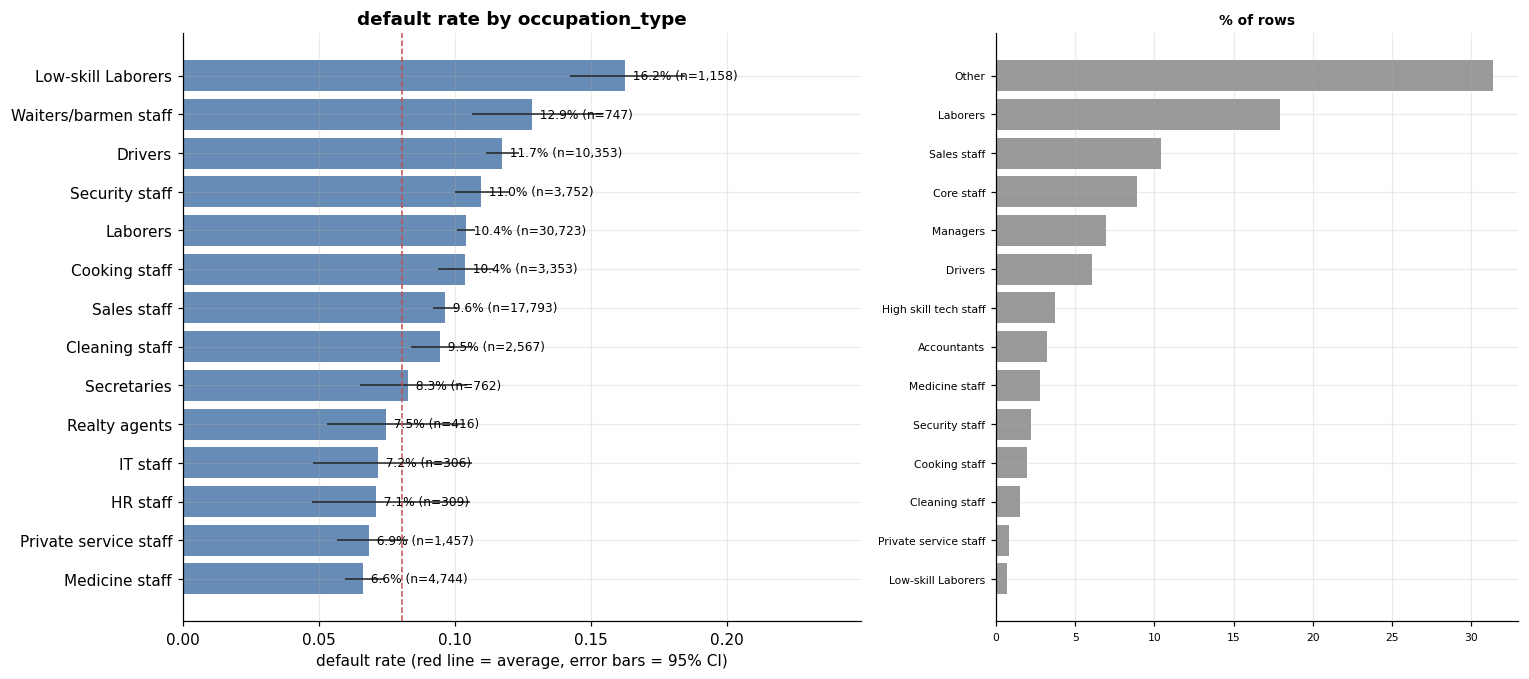

organization_type   |   58 levels, 0.0% missing   |   Cramer's V=0.071, χ² p=8.2e-147   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Transport: type 3']
Meaning   : Type of organization where the borrower works (many levels).
Hypothesis: Some industries (construction, transport, self-employed) are riskier; XNA = not working.
Recommended encoding: many levels: target encoding inside CV (prevents leakage) or CatBoost categorical; merge rare levels into 'Other'; 41 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Transport: type 3,662,0.0039,0.1616,0.1356,0.1916,2.0021,7.6695,True,True
Industry: type 8,8,0.0000,0.1250,0.0224,0.4709,1.5484,0.4597,False,True
Realtor,242,0.0014,0.1240,0.0882,0.1715,1.5356,2.4717,False,True
Restaurant,1018,0.0059,0.1179,0.0995,0.1391,1.4602,4.3694,True,True
Cleaning,146,0.0009,0.1096,0.0686,0.1706,1.3575,1.2808,False,True
Construction,3700,0.0216,0.1086,0.0990,0.1191,1.3458,6.3246,True,False
Industry: type 3,1833,0.0107,0.1053,0.0921,0.1202,1.3043,3.8870,True,False
Security,1816,0.0106,0.1046,0.0914,0.1195,1.2960,3.7636,True,False
Agriculture,1338,0.0078,0.1024,0.0873,0.1198,1.2683,2.9229,False,True


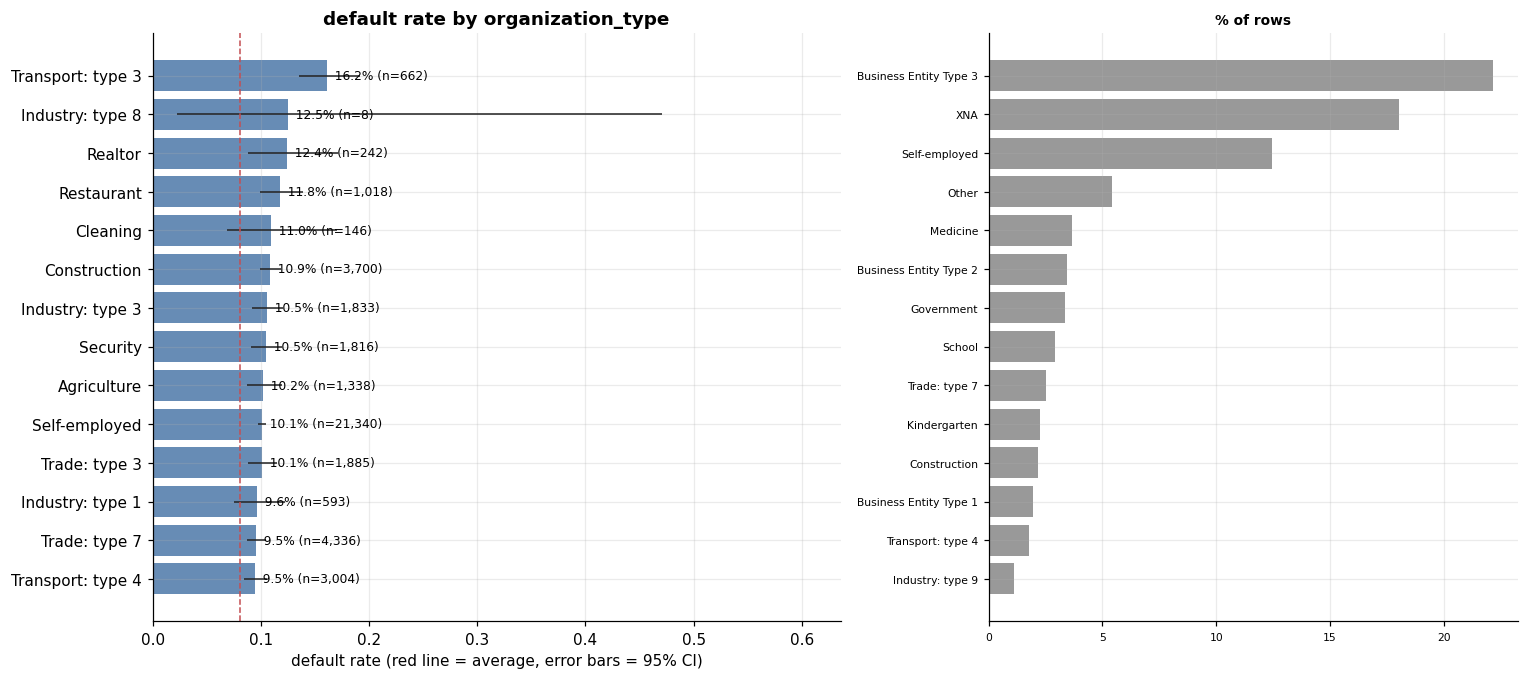

name_income_type   |   8 levels, 0.0% missing   |   Cramer's V=0.062, χ² p=2.1e-136   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Unemployed', 'Maternity leave', 'Working']
Meaning   : Source of income (Working, Pensioner, Commercial associate...).
Hypothesis: Pensioner/State servant are low risk; Unemployed, Maternity leave are the riskiest.
Recommended encoding: native categorical (LightGBM/CatBoost); consider merging rare levels; 4 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Maternity leave,3,0.0000,0.3333,0.0615,0.7923,4.1290,1.6061,False,True
Unemployed,10,0.0001,0.2000,0.0567,0.5098,2.4774,1.3846,False,True
Working,88268,0.5156,0.0955,0.0936,0.0974,1.1827,25.5396,True,False
Commercial associate,40007,0.2337,0.0752,0.0727,0.0778,0.9317,-4.5843,True,False
State servant,12007,0.0701,0.0589,0.0548,0.0632,0.7294,-9.0295,True,False
Pensioner,30895,0.1805,0.0542,0.0517,0.0568,0.6712,-18.3283,True,False
Businessman,3,0.0000,0.0000,0.0000,0.5615,0.0000,-0.5133,False,True
Student,9,0.0001,0.0000,0.0000,0.2992,0.0000,-0.8890,False,True


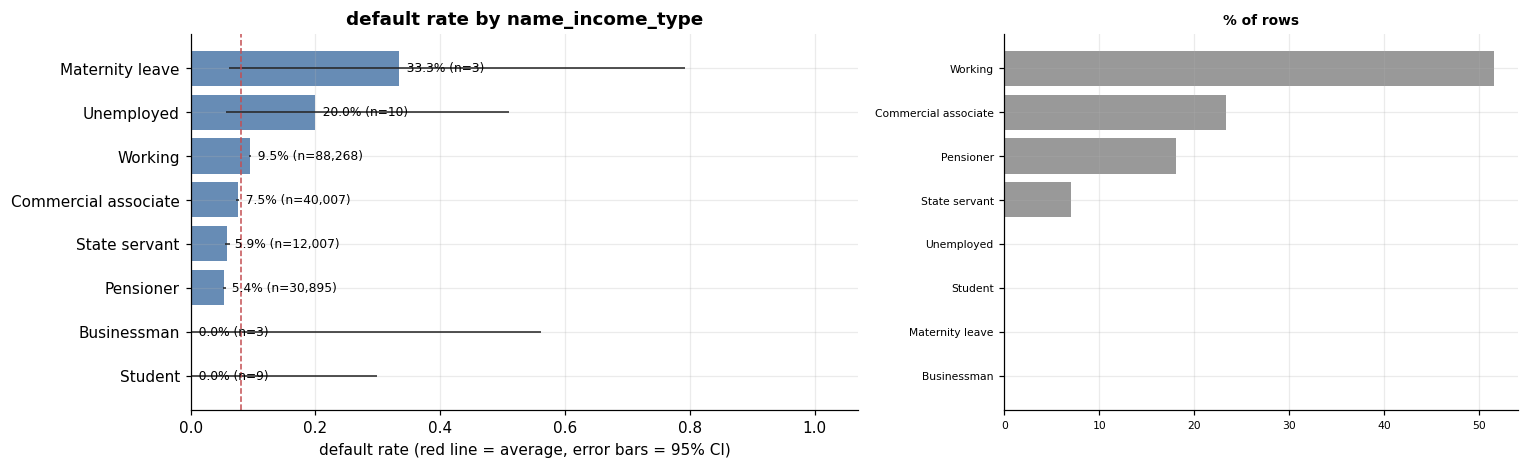

name_education_type   |   5 levels, 0.0% missing   |   Cramer's V=0.057, χ² p=9.2e-121   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Lower secondary', 'Secondary / secondary special']
Meaning   : Education level.
Hypothesis: Lower education -> more defaults (natural order: Lower secondary > Secondary > Incomplete higher > Higher > Academic).
Recommended encoding: natural order (ordinal); the ranking is already clear; 1 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Lower secondary,2133,0.0125,0.1106,0.0980,0.1247,1.3705,5.1141,True,False
Secondary / secondary special,121612,0.7103,0.0892,0.0876,0.0908,1.1052,23.1773,True,False
Incomplete higher,5711,0.0334,0.0872,0.0802,0.0948,1.0802,1.8281,False,False
Higher education,41645,0.2433,0.0537,0.0516,0.0559,0.6651,-22.2276,True,False
Academic degree,101,0.0006,0.0099,0.0017,0.0540,0.1226,-2.6131,True,True


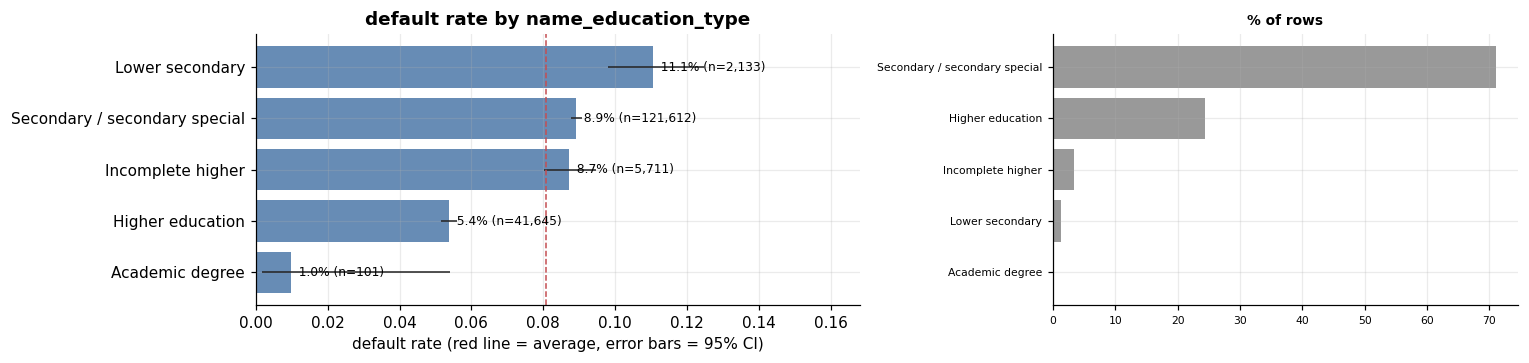

code_gender   |   3 levels, 0.0% missing   |   Cramer's V=0.054, χ² p=4.9e-111   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['M']
Meaning   : Borrower's gender (XNA = unknown).
Hypothesis: Men default more than women; XNA is too rare to conclude anything.
Recommended encoding: one-hot or native categorical; few levels so it is safe; 1 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
M,58649,0.3426,0.1013,0.0989,0.1037,1.2546,24.0545,True,False
F,112549,0.6574,0.0700,0.0685,0.0715,0.8674,-20.3404,True,False
XNA,4,0.0000,0.0000,0.0000,0.4899,0.0000,-0.5927,False,True


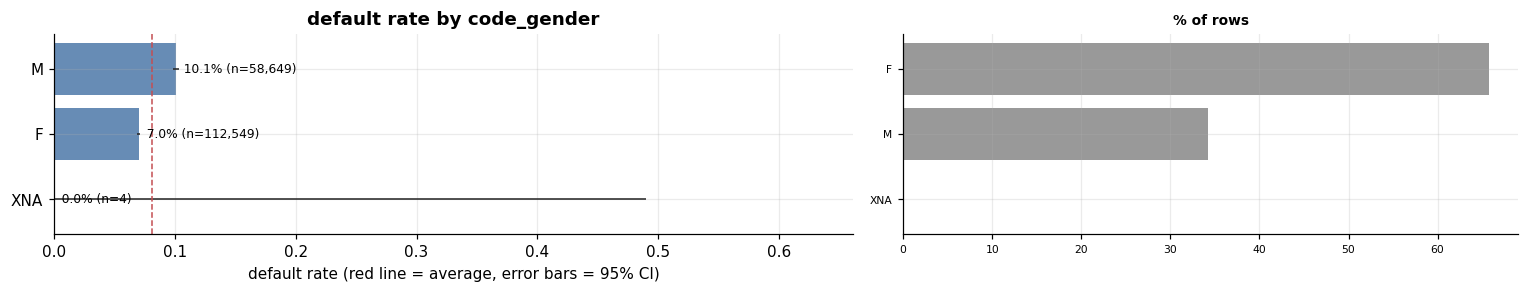

name_family_status   |   6 levels, 0.0% missing   |   Cramer's V=0.041, χ² p=1.1e-59   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Single / not married', 'Civil marriage', 'Separated']
Meaning   : Marital status.
Hypothesis: Single / civil marriage are riskier than married.
Recommended encoding: one-hot or native categorical; few levels so it is safe; 1 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Civil marriage,16652,0.0973,0.0987,0.0943,0.1034,1.2229,9.0731,True,False
Single / not married,25285,0.1477,0.0986,0.0949,0.1023,1.2208,11.4743,True,False
Separated,10988,0.0642,0.0827,0.0777,0.0880,1.0247,0.7951,False,False
Married,109323,0.6386,0.0756,0.0740,0.0771,0.9360,-9.9315,True,False
Widow,8952,0.0523,0.0575,0.0529,0.0625,0.7126,-8.2179,True,False
Unknown,2,0.0000,0.0000,0.0000,0.6576,0.0000,-0.4191,False,True


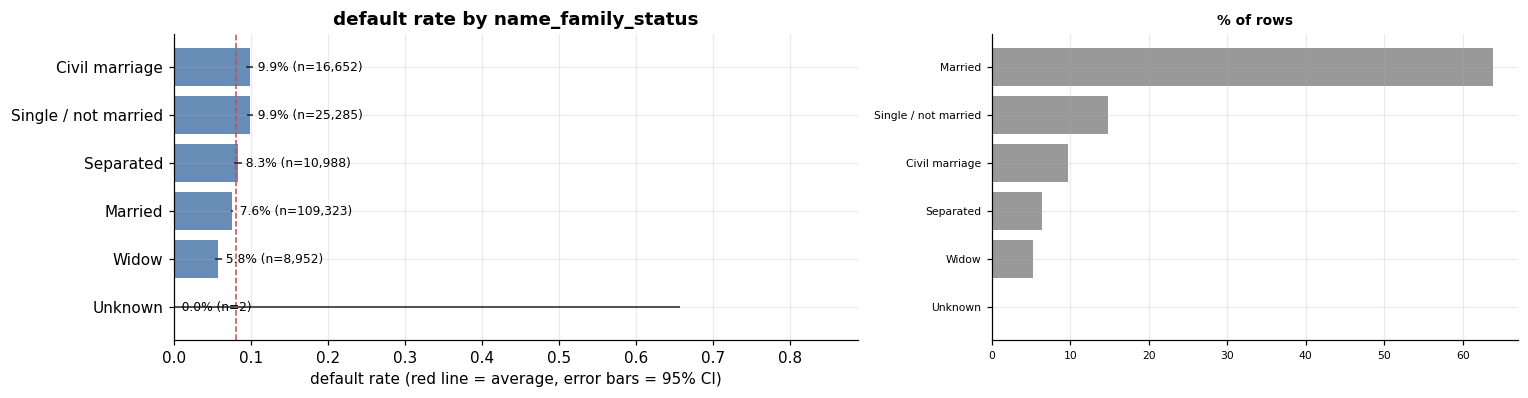

name_housing_type   |   6 levels, 0.0% missing   |   Cramer's V=0.039, χ² p=3.5e-55   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['With parents', 'Rented apartment']
Meaning   : Type of housing.
Hypothesis: Living with parents or renting is riskier than owning a home.
Recommended encoding: one-hot or native categorical; few levels so it is safe; 2 rare levels (<1%) should be merged


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Rented apartment,2734,0.0160,0.1295,0.1174,0.1426,1.6039,9.4754,True,False
With parents,8263,0.0483,0.1180,0.1112,0.1251,1.4616,12.8852,True,False
Co-op apartment,620,0.0036,0.0855,0.0659,0.1101,1.0589,0.4354,False,True
Municipal apartment,6225,0.0364,0.0835,0.0769,0.0907,1.0347,0.8281,False,False
House / apartment,151916,0.8873,0.0778,0.0765,0.0792,0.9642,-11.0184,True,False
Office apartment,1444,0.0084,0.0651,0.0535,0.0790,0.8064,-2.1882,False,True


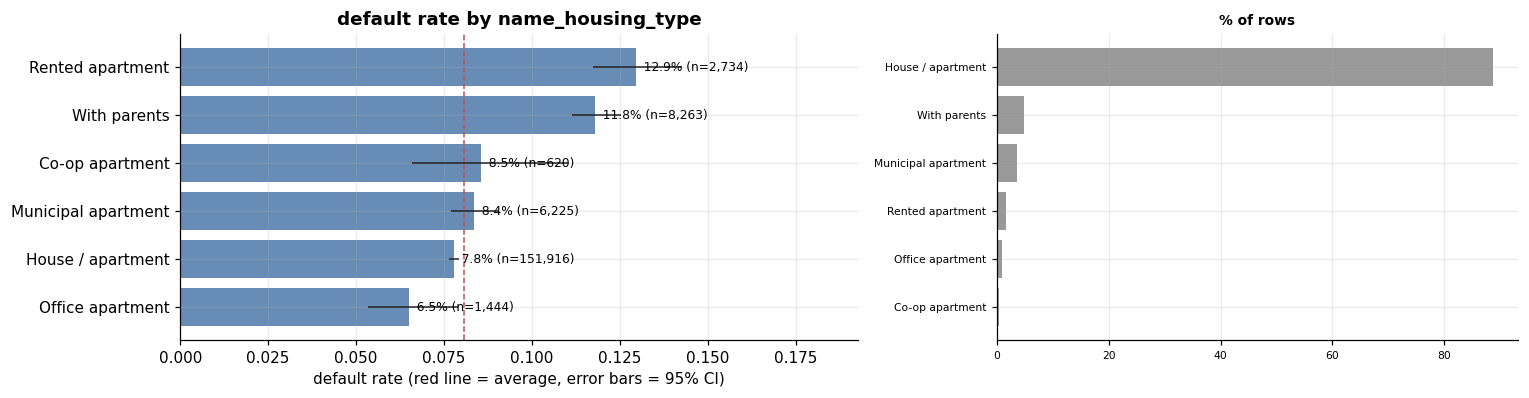

name_contract_type   |   2 levels, 0.0% missing   |   Cramer's V=0.030, χ² p=3.6e-35   |   CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: ['Cash loans']
Meaning   : Contract type: cash loan (Cash) or card / revolving credit line (Revolving).
Hypothesis: Cash loans are riskier than Revolving (large loans, fixed installments).
Recommended encoding: one-hot or native categorical; few levels so it is safe


,n,share,rate,ci_lo,ci_hi,lift,z vs the rest,significant (Bonferroni),rare (<1%)
k,,,,,,,,,
Cash loans,154988,0.9053,0.0834,0.0820,0.0848,1.0327,14.7417,True,False
Revolving loans,16214,0.0947,0.0555,0.0521,0.0591,0.6876,-12.2103,True,False


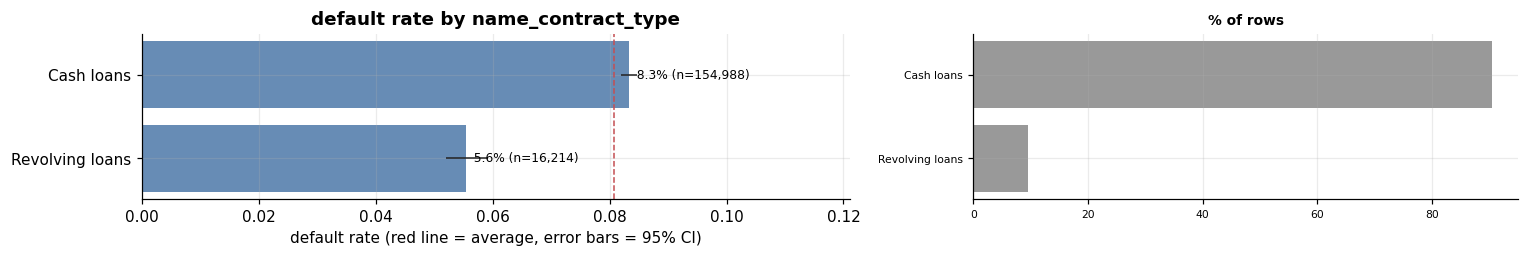

In [17]:
# ---------------- categorical columns ----------------
ORDER = {"name_education_type": ["Lower secondary", "Secondary / secondary special", "Incomplete higher", "Higher education", "Academic degree"]}


def cat_card(c):
    s = V[c]
    meaning, hyp, exp_levels = DICT.get(c, ("(no description yet)", "(no hypothesis yet)", []))
    t = rate_table(s, min_n=1)
    k = t["bad"].sum()
    # per-level z vs the rest, Bonferroni
    nn, bb = t["n"].to_numpy(float), t["bad"].to_numpy(float)
    rest_p = (bb.sum() - bb) / np.maximum(nn.sum() - nn, 1)
    z = (t["rate"].to_numpy() - rest_p) / np.sqrt(np.maximum(rest_p * (1 - rest_p), 1e-12) * (1 / nn + 1 / np.maximum(nn.sum() - nn, 1)))
    t["z vs the rest"] = z
    t["significant (Bonferroni)"] = np.abs(z) > stats.norm.isf(0.025 / len(t))
    t["rare (<1%)"] = t["share"] < 0.01
    ct = pd.crosstab(s.astype(object).where(s.notna(), "(missing)"), y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))) if min(ct.shape) > 1 else np.nan
    top = list(t.index[:3])
    if exp_levels:
        hit = [lv for lv in exp_levels if lv in list(t.index[:max(3, len(exp_levels))])]
        verdict = (f"CORRECT (PARTLY OR FULLY): the levels expected to be risky are among the highest: {hit}" if hit else f"MISMATCH: the highest-risk levels are {top}, which do not match the expectation {exp_levels}")
    else:
        verdict = "no hypothesis about the levels"
    # encoding recommendation
    nlev = s.nunique(dropna=True)
    rare = int(t["rare (<1%)"].sum())
    if c in ORDER:
        enc = "natural order (ordinal); the ranking is already clear"
    elif nlev <= 7:
        enc = "one-hot or native categorical; few levels so it is safe"
    elif nlev <= 15:
        enc = "native categorical (LightGBM/CatBoost); consider merging rare levels"
    else:
        enc = "many levels: target encoding inside CV (prevents leakage) or CatBoost categorical; merge rare levels into 'Other'"
    if rare:
        enc += f"; {rare} rare levels (<1%) should be merged"
    print("=" * 110)
    print(f"{c}   |   {nlev} levels, {s.isna().mean():.1%} missing   |   Cramer's V={v:.3f}, χ² p={p:.2g}   |   {verdict}")
    print(f"Meaning   : {meaning}")
    print(f"Hypothesis: {hyp}")
    print(f"Recommended encoding: {enc}")
    display(t[["n", "share", "rate", "ci_lo", "ci_hi", "lift", "z vs the rest", "significant (Bonferroni)", "rare (<1%)"]].head(20))
    fig, ax = plt.subplots(1, 2, figsize=(14, 0.32 * min(len(t), 14) + 1.8), gridspec_kw={"width_ratios": [1.3, 1]})
    plot_rates(t, f"default rate by {c}", ax=ax[0], top=14)
    sh_ = t.sort_values("n", ascending=False).head(14).iloc[::-1]
    ax[1].barh([str(i)[:30] for i in sh_.index], 100 * sh_["share"], color="#999"); ax[1].set_title("% of rows", fontsize=9); ax[1].tick_params(labelsize=7)
    plt.tight_layout(); plt.show()
    PROFILE.append({"column": c, "type": "categorical", "% missing": 100 * s.isna().mean(), "univariate AUC": np.nan, "direction": f"V={v:.3f}", "hypothesis": verdict,
                    "shape": f"{nlev} levels", "skew": np.nan, "recommended transform": enc, "meaning": meaning})


_vs = {c: cramers_v(V[c].to_numpy(), y) for c in CAT_V}
for _c in sorted(CAT_V, key=lambda c: -np.nan_to_num(_vs[c])):
    cat_card(_c)

### 5.x Per-column summary table (meaning, hypothesis verdict, transform recommendation)

In [18]:
prof = pd.DataFrame(PROFILE).set_index("column")
prof = prof.sort_values("univariate AUC", ascending=False, na_position="last")
display(prof[["type", "% missing", "univariate AUC", "direction", "hypothesis", "shape", "skew", "recommended transform"]])
ok_h = prof["hypothesis"].str.startswith("CORRECT").sum(); bad_h = prof["hypothesis"].str.startswith(("OPPOSITE", "MISMATCH", "NO EVIDENCE")).sum()
note("5. hypotheses per column", f"{ok_h} columns match the hypothesis, {bad_h} columns opposite/mismatched/no evidence, out of {len(prof)} columns",
     "; ".join(f"{c}: {r['hypothesis'][:26]}" for c, r in prof[prof['hypothesis'].str.startswith(('OPPOSITE', 'MISMATCH'))].head(5).iterrows()) or "no column goes against its hypothesis")

,type,% missing,univariate AUC,direction,hypothesis,shape,skew,recommended transform
column,,,,,,,,
ext_source_3,numeric,31.8840,0.6796,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,-0.4123,none needed
ext_source_1,numeric,69.4665,0.6647,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,-0.0708,none needed
ext_source_2,numeric,0.2155,0.6582,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,-0.7921,Yeo-Johnson
age_years,numeric,0.0000,0.5844,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,0.1113,none needed
years_employed,numeric,18.0477,0.5807,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,1.9561,log1p
own_car_age,numeric,65.9992,0.5595,increase -> more defaults,the hypothesis has no expected direction,monotonic increasing,2.7405,Yeo-Johnson
years_id_publish,numeric,0.0000,0.5568,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,-0.3455,none needed
years_since_phone_change,numeric,0.0000,0.5565,increase -> fewer defaults,CORRECT: direction matches the hypothesis,monotonic decreasing,0.7168,log1p
region_rating_client,numeric,0.0000,0.5481,increase -> more defaults,CORRECT: direction matches the hypothesis,few groups,0.0901,none needed


[5. hypotheses per column] 21 columns match the hypothesis, 6 columns opposite/mismatched/no evidence, out of 32 columns
    flag_emp_phone: OPPOSITE: direction contra


## 5b. Bivariate relationships

Covers: (1) whether **ratios / derived variables** are worth creating, (2) relationships between pairs of numeric variables, (3) **default-rate heatmaps** for important pairs, (4) an **interaction** scan (does a two-variable model beat each variable alone?), (5) categorical × categorical, (6) categorical × numeric.

In [19]:
def cv_auc(cols, n=40000, folds=3, trees=120, df=None, return_oof=False):
    df = V if df is None else df
    X = df[cols].copy()
    for c in cols:
        if is_cat(X[c]):
            X[c] = X[c].astype("category")
    rs = np.random.RandomState(SEED); idx = rs.choice(len(X), min(n, len(X)), replace=False)
    Xs, ys = X.iloc[idx].reset_index(drop=True), y[idx]
    oof = np.zeros(len(ys))
    for a, b in StratifiedKFold(folds, shuffle=True, random_state=SEED).split(Xs, ys):
        m_ = lgb.LGBMClassifier(n_estimators=trees, learning_rate=0.06, num_leaves=8, max_depth=3, min_child_samples=100, subsample=0.8, subsample_freq=1,
                                colsample_bytree=1.0, verbose=-1, random_state=SEED)
        m_.fit(Xs.iloc[a], ys[a]); oof[b] = m_.predict_proba(Xs.iloc[b])[:, 1]
    return (roc_auc_score(ys, oof), oof, ys) if return_oof else roc_auc_score(ys, oof)


# derived variables
V["credit_to_income"] = V["credit_amount"] / V["income"].replace(0, np.nan)
V["annuity_to_income"] = V["annuity"] / V["income"].replace(0, np.nan)
V["credit_term"] = V["credit_amount"] / V["annuity"].replace(0, np.nan)
V["goods_to_credit"] = V["amt_goods_price"] / V["credit_amount"].replace(0, np.nan)
V["employed_to_age"] = V["years_employed"] / V["age_years"]
V["income_per_member"] = V["income"] / V["cnt_fam_members"].replace(0, np.nan)
V["ext_mean"] = V[["ext_source_1", "ext_source_2", "ext_source_3"]].mean(axis=1)
V["ext_min"] = V[["ext_source_1", "ext_source_2", "ext_source_3"]].min(axis=1)
V["ext_prod"] = V[["ext_source_1", "ext_source_2", "ext_source_3"]].prod(axis=1, min_count=2)
DER = {
    "credit_to_income": ["credit_amount", "income"], "annuity_to_income": ["annuity", "income"], "credit_term": ["credit_amount", "annuity"],
    "goods_to_credit": ["amt_goods_price", "credit_amount"], "employed_to_age": ["years_employed", "age_years"], "income_per_member": ["income", "cnt_fam_members"],
    "ext_mean": ["ext_source_1", "ext_source_2", "ext_source_3"], "ext_min": ["ext_source_1", "ext_source_2", "ext_source_3"], "ext_prod": ["ext_source_1", "ext_source_2", "ext_source_3"],
}
rows = []
for d_, parts in DER.items():
    parts = [p_ for p_ in parts if p_ in V.columns]
    if len(parts) < 2 or V[d_].notna().sum() < 500:
        continue
    def uni(c):
        ok = V[c].notna().to_numpy()
        a = roc_auc_score(y[ok], V[c][ok]); return max(a, 1 - a)
    a_d, a_p = uni(d_), max(uni(p_) for p_ in parts)
    c_parts = cv_auc(parts); c_both = cv_auc(parts + [d_])
    rows.append({"derived variable": d_, "built from": " , ".join(parts), "univariate AUC (derived)": a_d, "best univariate AUC of the components": a_p,
                 "CV AUC components only": c_parts, "CV AUC components + derived": c_both, "added gain": c_both - c_parts})
dd = pd.DataFrame(rows).set_index("derived variable").sort_values("added gain", ascending=False)
display(dd)
print("How to read: 'added gain' > 0.001 means the tree cannot build this ratio from its components by itself (worth adding as a feature); ≈ 0 means it is redundant.")
note("5b. derived variables", "worth creating: " + (", ".join(dd.index[dd["added gain"] > 0.001]) or "none"), "; ".join(f"{c}: {r['added gain']:+.4f}" for c, r in dd.head(4).iterrows()))

,built from,univariate AUC (derived),best univariate AUC of the components,CV AUC components only,CV AUC components + derived,added gain
derived variable,,,,,,
credit_term,"credit_amount , annuity",0.5336,0.5212,0.5995,0.6494,0.0499
goods_to_credit,"amt_goods_price , credit_amount",0.5681,0.5359,0.6092,0.6138,0.0046
ext_mean,"ext_source_1 , ext_source_2 , ext_source_3",0.7060,0.6796,0.7173,0.7169,-0.0003
annuity_to_income,"annuity , income",0.5167,0.5182,0.5607,0.5603,-0.0004
ext_min,"ext_source_1 , ext_source_2 , ext_source_3",0.6836,0.6796,0.7173,0.7162,-0.0010
income_per_member,"income , cnt_fam_members",0.5167,0.5182,0.5216,0.5204,-0.0013
ext_prod,"ext_source_1 , ext_source_2 , ext_source_3",0.7021,0.6796,0.7173,0.7157,-0.0016
employed_to_age,"years_employed , age_years",0.5673,0.5844,0.5992,0.5970,-0.0021
credit_to_income,"credit_amount , income",0.5045,0.5212,0.5808,0.5766,-0.0042


How to read: 'added gain' > 0.001 means the tree cannot build this ratio from its components by itself (worth adding as a feature); ≈ 0 means it is redundant.
[5b. derived variables] worth creating: credit_term, goods_to_credit
    credit_term: +0.0499; goods_to_credit: +0.0046; ext_mean: -0.0003; annuity_to_income: -0.0004


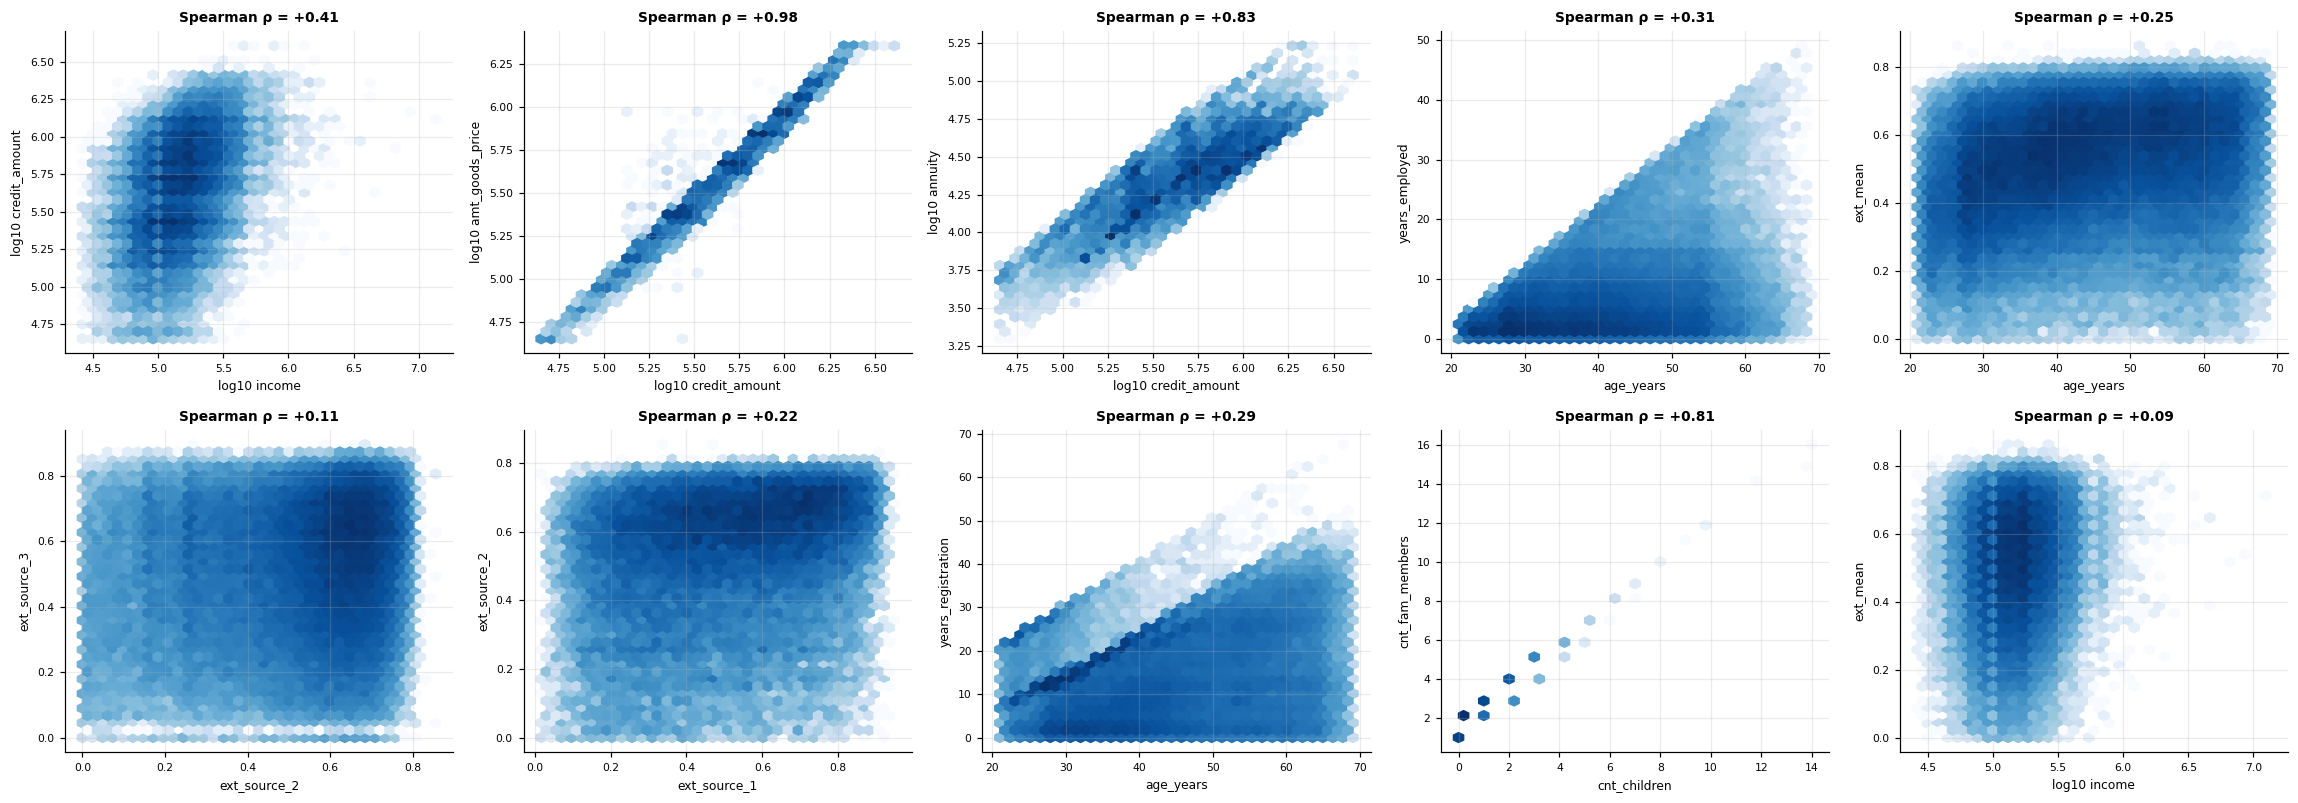

In [20]:
# relationships between important pairs of numeric variables (hexbin + Spearman)
pairs = [("income", "credit_amount"), ("credit_amount", "amt_goods_price"), ("credit_amount", "annuity"), ("age_years", "years_employed"),
         ("age_years", "ext_mean"), ("ext_source_2", "ext_source_3"), ("ext_source_1", "ext_source_2"), ("age_years", "years_registration"),
         ("cnt_children", "cnt_fam_members"), ("income", "ext_mean")]
pairs = [(a, b) for a, b in pairs if a in V.columns and b in V.columns]
fig, axes = plt.subplots(2, int(np.ceil(len(pairs) / 2)), figsize=(4.2 * int(np.ceil(len(pairs) / 2)), 7.4)); axes = axes.ravel()
for a_, (p1, p2) in zip(axes, pairs):
    d_ = V[[p1, p2]].dropna()
    rho = stats.spearmanr(d_[p1], d_[p2])[0]
    xx, yy_ = d_[p1], d_[p2]
    lx = p1 in ("income", "credit_amount", "amt_goods_price", "annuity"); ly = p2 in ("income", "credit_amount", "amt_goods_price", "annuity")
    a_.hexbin(np.log10(xx.clip(lower=1)) if lx else xx, np.log10(yy_.clip(lower=1)) if ly else yy_, gridsize=35, cmap="Blues", mincnt=1, bins="log")
    a_.set_xlabel(("log10 " if lx else "") + p1, fontsize=8); a_.set_ylabel(("log10 " if ly else "") + p2, fontsize=8); a_.tick_params(labelsize=7)
    a_.set_title(f"Spearman ρ = {rho:+.2f}", fontsize=9)
for a_ in axes[len(pairs):]:
    a_.axis("off")
plt.tight_layout(); plt.show()

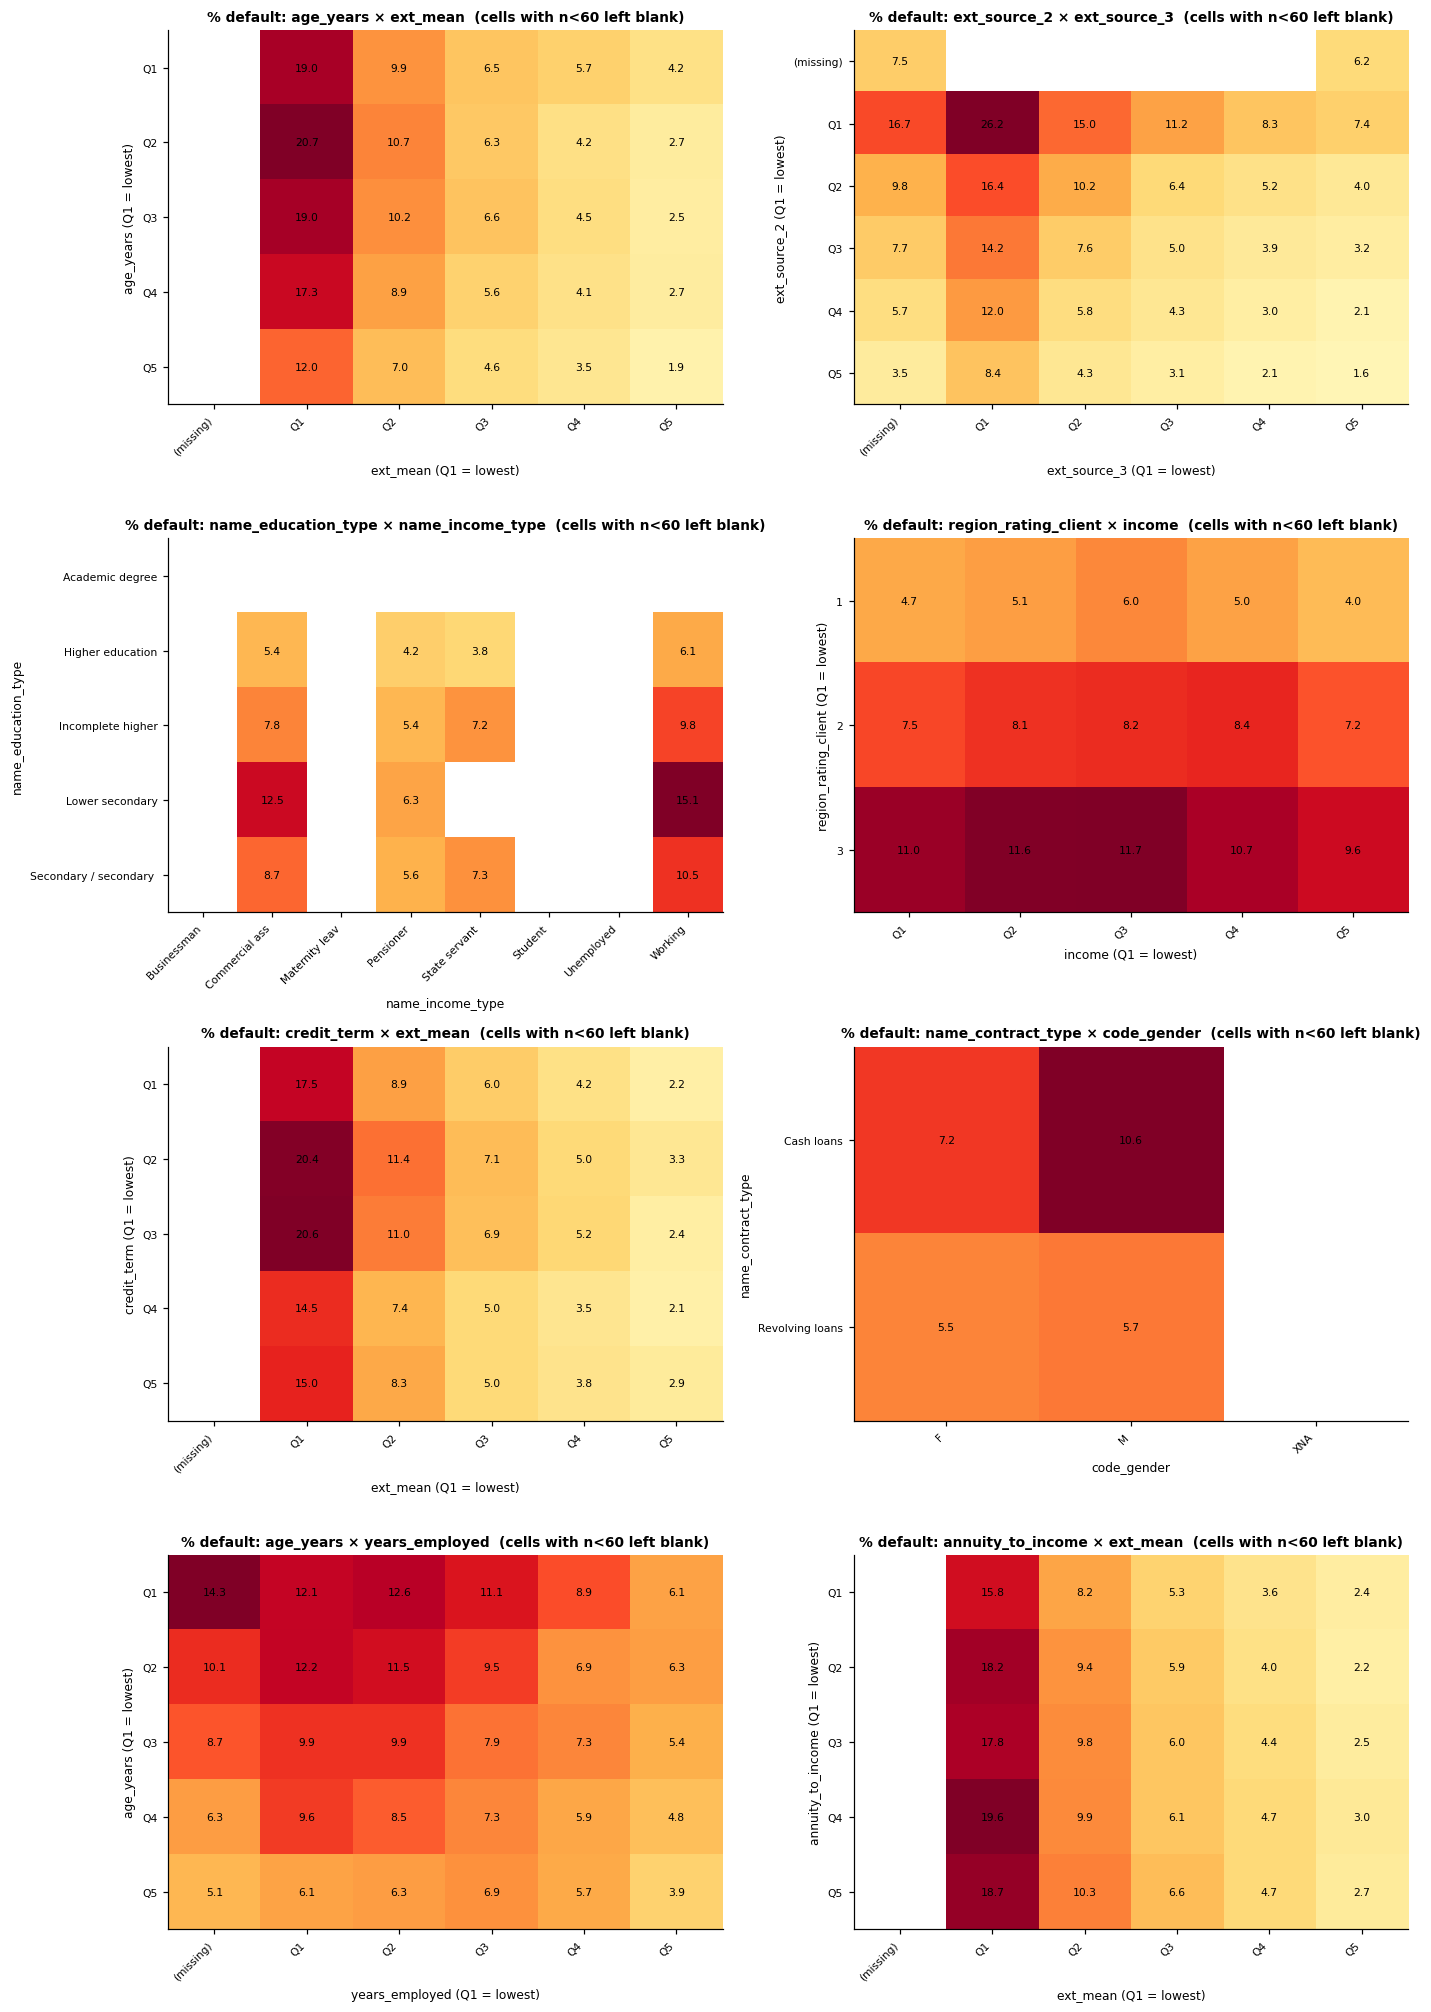

In [21]:
# default-rate heatmaps for important pairs (numeric x numeric via quantiles, categorical x categorical)
def qbin(s, q=5):
    s = s.copy()
    if s.nunique() <= q:
        return s.astype(object).where(s.notna(), "(missing)")
    b = pd.qcut(s.rank(method="first"), q, labels=[f"Q{i + 1}" for i in range(q)])
    return b.astype(object).where(s.notna(), "(missing)")


def heat(a, b, q=5, min_n=60, ax=None):
    A = qbin(V[a], q) if not is_cat(V[a]) else V[a].astype(object).where(V[a].notna(), "(missing)")
    B = qbin(V[b], q) if not is_cat(V[b]) else V[b].astype(object).where(V[b].notna(), "(missing)")
    d_ = pd.DataFrame({"a": A, "b": B, "y": y})
    r = d_.pivot_table(index="a", columns="b", values="y", aggfunc="mean")
    n = d_.pivot_table(index="a", columns="b", values="y", aggfunc="size")
    r = r.where(n >= min_n)
    if ax is None:
        ax = plt.subplots(figsize=(6.3, 4.5))[1]
    im = ax.imshow(r.values.astype(float), cmap="YlOrRd", aspect="auto", vmin=0, vmax=min(0.35, np.nanmax(r.values) if np.isfinite(np.nanmax(r.values)) else 0.3))
    ax.set_xticks(range(r.shape[1])); ax.set_xticklabels([str(c)[:14] for c in r.columns], rotation=45, ha="right", fontsize=7)
    ax.set_yticks(range(r.shape[0])); ax.set_yticklabels([str(i)[:22] for i in r.index], fontsize=7)
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            if np.isfinite(r.values[i, j]):
                ax.text(j, i, f"{100 * r.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.grid(False); ax.set_xlabel(b + (" (Q1 = lowest)" if not is_cat(V[b]) else ""), fontsize=8); ax.set_ylabel(a + (" (Q1 = lowest)" if not is_cat(V[a]) else ""), fontsize=8)
    ax.set_title(f"% default: {a} × {b}  (cells with n<{min_n} left blank)", fontsize=9)
    return r


HP = [("age_years", "ext_mean"), ("ext_source_2", "ext_source_3"), ("name_education_type", "name_income_type"), ("region_rating_client", "income"),
      ("credit_term", "ext_mean"), ("name_contract_type", "code_gender"), ("age_years", "years_employed"), ("annuity_to_income", "ext_mean")]
HP = [(a, b) for a, b in HP if a in V.columns and b in V.columns]
fig, axes = plt.subplots(int(np.ceil(len(HP) / 2)), 2, figsize=(13, 4.6 * int(np.ceil(len(HP) / 2)))); axes = axes.ravel()
for a_, (p1, p2) in zip(axes, HP):
    heat(p1, p2, ax=a_)
for a_ in axes[len(HP):]:
    a_.axis("off")
plt.tight_layout(); plt.show()

In [22]:
# interaction scan: does the pair (A, B) predict better than A and B separately?
cand = []
for c in NUM_V + CAT_V:
    if c in V.columns and V[c].nunique() > 1 and c not in ("flag_mobil",):
        cand.append(c)
single, oofs = {}, {}
for c in cand:
    try:
        a_, o_, ys_ = cv_auc([c], n=30000, folds=3, trees=80, return_oof=True)
        single[c], oofs[c] = a_, o_
    except Exception:
        pass
top = sorted(single, key=single.get, reverse=True)[:10]
print("Top 10 variables by single-variable CV AUC:", {c: round(single[c], 4) for c in top})
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
rows = []
from itertools import combinations
for a, b in combinations(top, 2):
    both = cv_auc([a, b], n=30000, folds=3, trees=80)
    additive = roc_auc_score(ys_, lg(oofs[a]) + lg(oofs[b]))     # sum of the two single-variable models, NO cross-interaction
    rows.append({"A": a, "B": b, "pair AUC (depth-3 trees)": both, "AUC of the two single models summed": additive, "TRUE INTERACTION = pair − sum": both - additive})
it = pd.DataFrame(rows).sort_values("TRUE INTERACTION = pair − sum", ascending=False)
display(it.head(12))
print("How to read: last column > 0.005 means this pair has signal that the two variables added together do not have (a true interaction). Near 0 means purely additive. Since the sample is the same small 40k, treat ±0.003 as noise.")

Top 10 variables by single-variable CV AUC: {'ext_source_2': np.float64(0.6583), 'ext_source_3': np.float64(0.6455), 'amt_goods_price': np.float64(0.5959), 'credit_amount': np.float64(0.5887), 'years_employed': np.float64(0.581), 'age_years': np.float64(0.5798), 'occupation_type': np.float64(0.5695), 'name_income_type': np.float64(0.5614), 'organization_type': np.float64(0.5602), 'region_population_relative': np.float64(0.5554)}


,A,B,pair AUC (depth-3 trees),AUC of the two single models summed,TRUE INTERACTION = pair − sum
17,amt_goods_price,credit_amount,0.6153,0.5984,0.0169
8,ext_source_2,region_population_relative,0.6572,0.6545,0.0027
12,ext_source_3,age_years,0.6634,0.6610,0.0023
35,age_years,occupation_type,0.6044,0.6022,0.0023
0,ext_source_2,ext_source_3,0.7118,0.7100,0.0018
4,ext_source_2,age_years,0.6729,0.6711,0.0018
19,amt_goods_price,age_years,0.6212,0.6204,0.0008
43,name_income_type,region_population_relative,0.5857,0.5857,0.0001
13,ext_source_3,occupation_type,0.6659,0.6659,0.0000
9,ext_source_3,amt_goods_price,0.6728,0.6731,-0.0003


How to read: last column > 0.005 means this pair has signal that the two variables added together do not have (a true interaction). Near 0 means purely additive. Since the sample is the same small 40k, treat ±0.003 as noise.


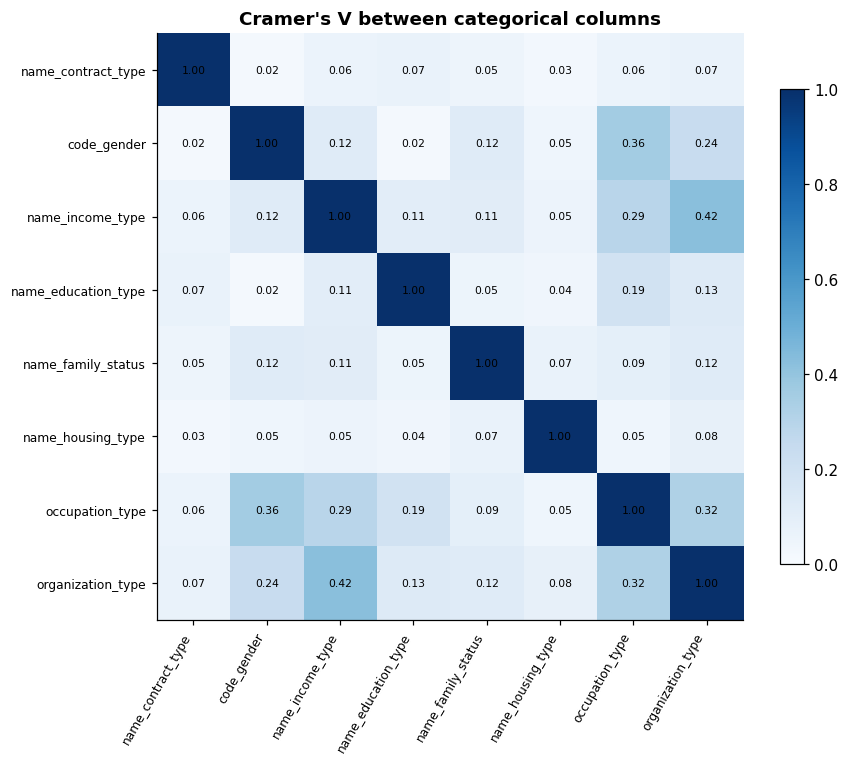

numeric column,age_years,annuity_to_income,credit_amount,credit_term,ext_mean,income,years_employed
categorical column,,,,,,,
code_gender,0.022,0.012,0.000,0.005,0.005,0.047,0.007
name_contract_type,0.007,0.088,0.070,0.002,0.000,0.002,0.002
name_education_type,0.042,0.010,0.012,0.002,0.011,0.057,0.004
name_family_status,0.092,0.018,0.022,0.006,0.007,0.005,0.017
name_housing_type,0.062,0.000,0.004,0.003,0.009,0.001,0.012
name_income_type,0.361,0.007,0.013,0.002,0.013,0.066,0.018
occupation_type,0.194,0.011,0.018,0.005,0.017,0.080,0.026
organization_type,0.382,0.014,0.008,0.004,0.011,0.070,0.070


How to read: high η² means the categorical groups explain a lot of the variation of the numeric column (for example name_income_type ~ years_employed).


In [23]:
# categorical x categorical: Cramer's V
cv_ = pd.DataFrame(index=CAT_V, columns=CAT_V, dtype=float)
for a in CAT_V:
    for b in CAT_V:
        cv_.loc[a, b] = 1.0 if a == b else cramers_v(V[a].to_numpy(), V[b].to_numpy())
fig, ax = plt.subplots(figsize=(0.7 * len(CAT_V) + 3, 0.7 * len(CAT_V) + 2.4))
im = ax.imshow(cv_.values.astype(float), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(CAT_V))); ax.set_xticklabels(CAT_V, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(CAT_V))); ax.set_yticklabels(CAT_V, fontsize=8)
for i in range(len(CAT_V)):
    for j in range(len(CAT_V)):
        ax.text(j, i, f"{cv_.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=0.7); ax.set_title("Cramer's V between categorical columns"); plt.show()

# categorical x numeric: eta^2 (share of the numeric variable's variance explained by the groups), Kruskal-Wallis
keyn = [c for c in ("age_years", "years_employed", "income", "credit_amount", "credit_term", "ext_mean", "annuity_to_income") if c in V.columns]
rows = []
for c in CAT_V:
    for nn_ in keyn:
        d_ = V[[c, nn_]].dropna()
        grp = [g_[nn_].to_numpy() for _, g_ in d_.groupby(c) if len(g_) >= 20]
        if len(grp) < 2:
            continue
        H, p = stats.kruskal(*grp)
        eta = (H - len(grp) + 1) / (len(d_) - len(grp))
        rows.append({"categorical column": c, "numeric column": nn_, "η² (Kruskal)": max(eta, 0), "p": p})
eta = pd.DataFrame(rows).pivot(index="categorical column", columns="numeric column", values="η² (Kruskal)")
display(eta.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))
print("How to read: high η² means the categorical groups explain a lot of the variation of the numeric column (for example name_income_type ~ years_employed).")

## 6. Train vs test

Two checks: (a) the **PSI** of each column (PSI < 0.1: stable; 0.1–0.25: mild shift; > 0.25: clear shift) and (b) **adversarial validation**: train a small LightGBM to tell train rows from test rows; AUC ≈ 0.5 means they cannot be told apart (no shift).

In [24]:
def psi_num(a, b, bins=10):
    qs = np.unique(np.nanquantile(a, np.linspace(0, 1, bins + 1)))
    if len(qs) < 3:
        return np.nan
    qs[0], qs[-1] = -np.inf, np.inf
    pa = np.histogram(a[~np.isnan(a)], qs)[0] / max((~np.isnan(a)).sum(), 1)
    pb = np.histogram(b[~np.isnan(b)], qs)[0] / max((~np.isnan(b)).sum(), 1)
    # add a "missing" bin
    pa = np.append(pa * (1 - np.isnan(a).mean()), np.isnan(a).mean()); pb = np.append(pb * (1 - np.isnan(b).mean()), np.isnan(b).mean())
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))


def psi_cat(a, b):
    ca = a.astype(object).where(a.notna(), "(missing)").value_counts(normalize=True)
    cb = b.astype(object).where(b.notna(), "(missing)").value_counts(normalize=True)
    idx = ca.index.union(cb.index)
    pa, pb = ca.reindex(idx).fillna(0).clip(1e-4), cb.reindex(idx).fillna(0).clip(1e-4)
    return float(np.sum((pb - pa) * np.log(pb / pa)))


rows = []
for c in RAW:
    if c in CAT:
        rows.append((c, psi_cat(tr[c], te[c])))
    else:
        rows.append((c, psi_num(pd.to_numeric(tr[c]).to_numpy(float), pd.to_numeric(te[c]).to_numpy(float))))
psi = pd.DataFrame(rows, columns=["column", "PSI"]).set_index("column").sort_values("PSI", ascending=False)
display(psi.head(12))

adv = full.drop(columns=[TARGET, ID_COL]).copy()
lab = (adv["_set"] == "test").astype(int).to_numpy()
adv = adv.drop(columns="_set")
auc_adv, imp_adv = predict_mask_auc(lab, adv.assign(_set="x").assign(_set2=0), exclude=("_set2",), n=100000)
print(f"Adversarial validation: AUC = {auc_adv:.4f}  (0.5 = train cannot be distinguished from test)")
display(imp_adv.to_frame("gain share"))
note("6. train vs test", "NO SHIFT" if auc_adv < 0.55 else "MILD SHIFT" if auc_adv < 0.65 else "CLEAR SHIFT",
     f"adversarial AUC {auc_adv:.3f}; largest PSI {psi['PSI'].iloc[0]:.3f} ({psi.index[0]})")

,PSI
column,
ext_source_3,0.0034
ext_source_2,0.0032
organization_type,0.0024
days_employed,0.0016
occupation_type,0.0014
days_birth,0.0010
ext_source_1,0.0009
name_income_type,0.0008
amt_goods_price,0.0007


Adversarial validation: AUC = 0.5087  (0.5 = train cannot be distinguished from test)


,gain share
organization_type,0.0969
ext_source_2,0.0828
ext_source_3,0.0743
days_registration,0.0697
days_id_publish,0.0610
annuity,0.0609


[6. train vs test] NO SHIFT
    adversarial AUC 0.509; largest PSI 0.003 (ext_source_3)


## 7. Correlation between variables

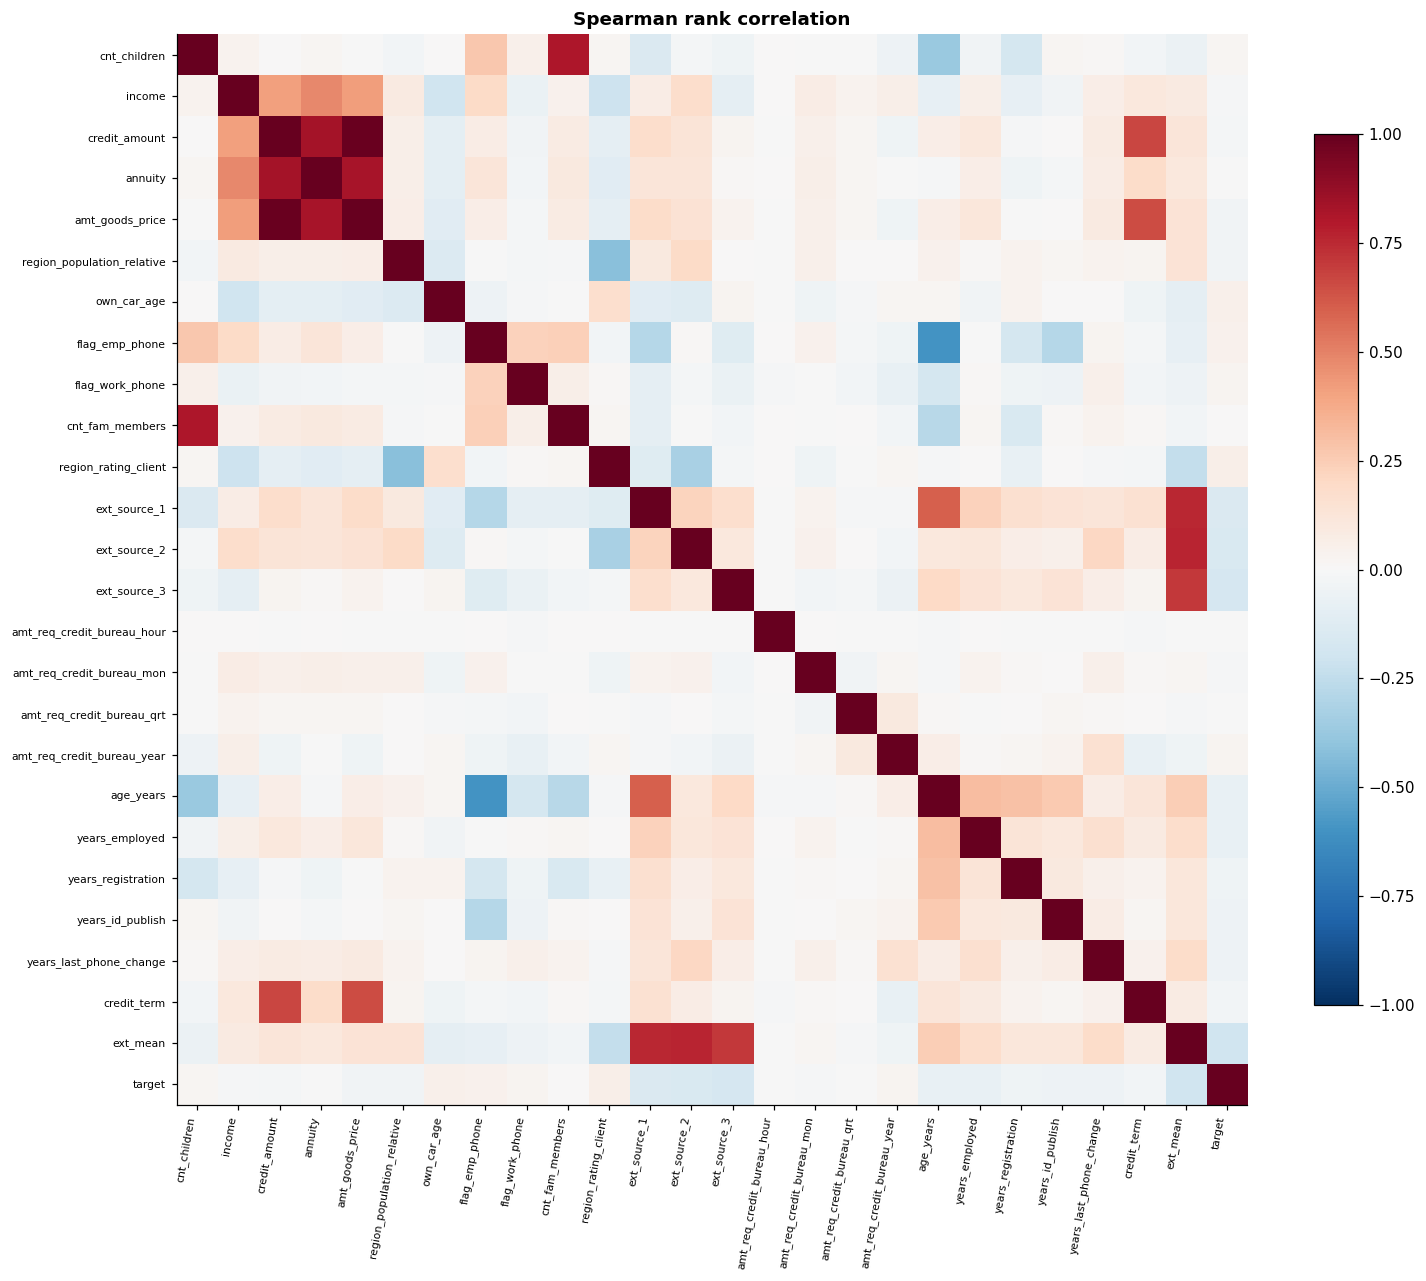

Most strongly correlated pairs (|rho|):


,variable A,variable B,rho
50,credit_amount,amt_goods_price,0.9849
49,credit_amount,annuity,0.8292
72,annuity,amt_goods_price,0.8271
8,cnt_children,cnt_fam_members,0.8118
245,ext_source_2,ext_mean,0.7613
232,ext_source_1,ext_mean,0.7533
257,ext_source_3,ext_mean,0.7104
69,credit_amount,credit_term,0.6705
112,amt_goods_price,credit_term,0.6508
164,flag_emp_phone,age_years,-0.5992


Rank correlation with the label:


,rho with label
ext_mean,-0.1989
ext_source_3,-0.1710
ext_source_2,-0.1518
ext_source_1,-0.1459
years_employed,-0.0774
age_years,-0.0768
region_rating_client,0.0570
years_id_publish,-0.0528
own_car_age,0.0527
years_last_phone_change,-0.0471


In [25]:
d2 = tr.copy()
d2["age_years"] = -d2["days_birth"] / 365.25
d2["years_employed"] = np.where(d2["days_employed"] == 365243, np.nan, -d2["days_employed"] / 365.25)
d2["years_registration"] = -d2["days_registration"] / 365.25
d2["years_id_publish"] = -d2["days_id_publish"] / 365.25
d2["years_last_phone_change"] = -d2["days_last_phone_change"] / 365.25
d2["credit_term"] = d2["credit_amount"] / d2["annuity"].replace(0, np.nan)
d2["ext_mean"] = d2[EXT].mean(axis=1)
d2["target"] = y
ncols = [c for c in NUM if not c.startswith("days_") and c not in ("flag_mobil",)] + ["age_years", "years_employed", "years_registration", "years_id_publish", "years_last_phone_change", "credit_term", "ext_mean", "target"]
ncols = [c for c in dict.fromkeys(ncols) if c in d2.columns and d2[c].nunique() > 1]
cm = d2[ncols].sample(min(60000, len(d2)), random_state=SEED).corr(method="spearman")
fig, ax = plt.subplots(figsize=(0.45 * len(ncols) + 4, 0.45 * len(ncols) + 3))
im = ax.imshow(cm, vmin=-1, vmax=1, cmap="RdBu_r"); ax.grid(False)
ax.set_xticks(range(len(ncols))); ax.set_xticklabels(ncols, rotation=80, ha="right", fontsize=7)
ax.set_yticks(range(len(ncols))); ax.set_yticklabels(ncols, fontsize=7)
plt.colorbar(im, shrink=0.7); ax.set_title("Spearman rank correlation"); plt.show()

pairs = cm.where(np.triu(np.ones(cm.shape, bool), 1)).stack().rename("rho").reset_index()
pairs.columns = ["variable A", "variable B", "rho"]
print("Most strongly correlated pairs (|rho|):")
display(pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(15))
print("Rank correlation with the label:")
display(cm["target"].drop("target").to_frame("rho with label").sort_values("rho with label", key=np.abs, ascending=False).head(12))

## 8. Near-duplicate records (data structure)

Some time-related columns (`days_birth`, `days_registration`, `days_id_publish`...) are fairly stable for each person. If the same set of values appears in several rows, it may be the same person applying for several loans. This section only describes that structure. *Exploiting the labels of duplicate records for prediction exploits a property of the dataset rather than learning credit behaviour, so the modelling notebook does not use it for its main model.*

In [26]:
keys = [c for c in ("days_birth", "days_registration", "days_id_publish", "region_population_relative") if c in full.columns]
gid = full[keys].astype(str).agg("|".join, axis=1)
sz = gid.map(gid.value_counts())
print(f"Group key: {keys}")
print(f"Number of groups: {gid.nunique():,} | rows in groups with ≥ 2 rows: {(sz >= 2).mean():.2%} (train+test)")
print("Group size distribution:"); display(sz.value_counts().sort_index().head(8).rename_axis("size").to_frame("rows"))
# within labeled groups: do two rows in the same group share a label more often than chance?
lab_full = full[TARGET]
pairs_same, pairs_tot, pos_in = 0, 0, 0
grp = pd.DataFrame({"g": gid, "t": lab_full})
grp = grp[grp["t"].notna() & (sz >= 2)]
for _, v in grp.groupby("g")["t"]:
    v = v.to_numpy()
    if len(v) >= 2:
        k, n_ = v.sum(), len(v)
        pairs_tot += n_ * (n_ - 1) / 2
        pairs_same += k * (k - 1) / 2 + (n_ - k) * (n_ - k - 1) / 2
exp_same = BASE ** 2 + (1 - BASE) ** 2
if pairs_tot:
    print(f"Same-group pairs with the same label: {pairs_same / pairs_tot:.2%} vs {exp_same:.2%} if independent → "
          f"{'labels are correlated within groups' if pairs_same / pairs_tot > exp_same + 0.01 else 'nearly independent'}")
note("8. duplicate records", f"{(sz >= 2).mean():.1%} of rows are in groups of ≥ 2 rows", f"key {', '.join(keys)}")

Group key: ['days_birth', 'days_registration', 'days_id_publish', 'region_population_relative']
Number of groups: 232,348 | rows in groups with ≥ 2 rows: 0.30% (train+test)
Group size distribution:


,rows
size,
1,231994
2,708


Same-group pairs with the same label: 96.53% vs 85.16% if independent → labels are correlated within groups
[8. duplicate records] 0.3% of rows are in groups of ≥ 2 rows
    key days_birth, days_registration, days_id_publish, region_population_relative


## 9. Summary of findings

In [27]:
print("Per-column profile:")
display(pd.DataFrame(PROFILE).set_index("column")[["type", "univariate AUC", "hypothesis", "shape", "recommended transform"]])
print("Key findings:")
display(pd.DataFrame(FINDINGS).set_index("section"))

Per-column profile:


,type,univariate AUC,hypothesis,shape,recommended transform
column,,,,,
ext_source_3,numeric,0.6796,CORRECT: direction matches the hypothesis,monotonic decreasing,none needed
ext_source_1,numeric,0.6647,CORRECT: direction matches the hypothesis,monotonic decreasing,none needed
ext_source_2,numeric,0.6582,CORRECT: direction matches the hypothesis,monotonic decreasing,Yeo-Johnson
age_years,numeric,0.5844,CORRECT: direction matches the hypothesis,monotonic decreasing,none needed
years_employed,numeric,0.5807,CORRECT: direction matches the hypothesis,monotonic decreasing,log1p
own_car_age,numeric,0.5595,the hypothesis has no expected direction,monotonic increasing,Yeo-Johnson
years_id_publish,numeric,0.5568,CORRECT: direction matches the hypothesis,monotonic decreasing,none needed
years_since_phone_change,numeric,0.5565,CORRECT: direction matches the hypothesis,monotonic decreasing,log1p
region_rating_client,numeric,0.5481,CORRECT: direction matches the hypothesis,few groups,none needed


Key findings:


,verdict,evidence
section,,
2. missingness vs label,7/9 columns have a significantly different def...,amt_req_credit_bureau_hour: +2.7pp; amt_req_cr...
H1: 365243,CONFIRMED: 365243 marks the non-working group ...,"coverage 100.0%, precision 100.0%; V(education..."
H2: own_car_age,CANNOT BE TESTED DIRECTLY; missing is usually ...,missing 66%; AUC predicting from other columns...
H3: bureau,CONFIRMED: the 4 columns are missing together ...,missing 13.5%; AUC predicting missingness from...
H4: ext_source,STRUCTURED MISSINGNESS (explainable from other...,"ext_source_1: missing 69.5%, AUC 0.65; ext_sou..."
H5: occupation_type,fairly random missingness,missing 0.0%; AUC from other columns nan; 0% o...
H6: ext_source_1,moderate association,"missing 69.5%; AUC 0.65; rule — (precision 0%,..."
H6: own_car_age,moderate association,missing 66.0%; AUC 0.76; rule name_family_stat...
H6: ext_source_3,missing in a cluster with other columns,missing 31.9%; AUC 0.72; rule amt_req_credit_b...


**Suggestions for using the results in the model** (depending on the real conclusions in the tables above):
- If H1 holds: keep `365243 → NaN` and the "not working" flag (already present), and do not create extra ratio features that divide by `years_employed` for this group.
- If H3/H4 show structured missingness (high explanation AUC): the missing flag may carry information; if missingness is nearly random, ML imputation will help little.
- If section 6 shows an adversarial AUC close to 0.5: CV is trustworthy for the public leaderboard; if it is high, look at which columns shift (importance table) before optimizing further.